# CSE 366 · Bone Fracture Classification with CNNs
## Group Information

| Field | Details |
|-------------------------|------------------------------------------------------|
| **Group ID** | 02 |
| **Section** | 01 |
| **Notebook Type** | CNN Models with fracture localization and a two-stage pipeline (ResNet-18 · DenseNet-121 · EfficientNet-B0 · MobileNetV3-Large · custom BoneNet) |
| **Main Dataset** | FracAtlas: musculoskeletal radiographs, fracture / non-fracture (Abedeen et al., *Scientific Data* 2023, doi:10.1038/s41597-023-02432-4) |
| **External Dataset** | HBFMID: Human Bone Fractures Multi-modal Image Dataset (Mendeley Data, doi:10.17632/xwfs6xbk47.1), used only for external testing |
| **Kaggle Dataset Paths** | `/kaggle/input/datasets/arifulislamopi/fracatlas/FracAtlas` · `/kaggle/input/datasets/arifulislamopi/hbfmid/...` |

# Section 1: Global Configuration

In [1]:
import os
from pathlib import Path

QUICK = os.environ.get('FRACTURE_QUICK') == '1'

SEED = 42
DATASETS = {
    'FracAtlas': {'env': 'FRACATLAS_ROOT', 'tokens': ('fracatlas',),
                  'roots': ['/kaggle/input/datasets/arifulislamopi/fracatlas/FracAtlas']},
    'HBFMID':    {'env': 'HBFMID_ROOT', 'tokens': ('hbfmid', 'human bone fractures multi-modal'),
                  'roots': ['/kaggle/input/datasets/arifulislamopi/hbfmid/Human Bone Fractures Multi-modal Image Dataset (HBFMID)']},
}
OUT      = Path(os.environ.get('FRACTURE_OUT', '/kaggle/working/bone_fracture_cnn'))
CACHE    = OUT.parent / '.fracture_eda_cache'
CKPT_DIR = OUT.parent / 'bone_fracture_cnn_checkpoints'
WORKERS  = min(8, max(1, (os.cpu_count() or 2)))
THUMB, TINY = 256, 32

ALLOW_TRUNCATED = True
ASSUME_XRAY_IF_NOT_MRI = True
NEAR_RADIUS = 2
AUTO_GROUP_DIST, AUTO_GROUP_CORR = 1, 0.90
REVIEW_MIN_CORR = 0.60
GROUP_UNREVIEWED = True
MAX_NEAR_PAIRS = 200_000
NEAR_REVIEW_CSV = None
MAKE_SPLITS = True
ALLOW_IMAGE_LEVEL_SPLIT = True
BUDGET_FRACTIONS = [0.01, 0.05, 0.10, 0.25, 1.0]
BUDGET_SEEDS = [42, 123, 2026]
DISPLAY_GALLERIES = True

ARCHS = ['resnet18', 'densenet121', 'efficientnet_b0', 'mobilenet_v3_large', 'custom_cnn']
SEEDS = [42] if QUICK else [42, 123, 2026]
PRETRAINED = not QUICK

IMG_SIZE = 64 if QUICK else 320
HIRES = 96 if QUICK else 512
CROP_SIZE = IMG_SIZE
BATCH = 32
EPOCHS = 2 if QUICK else 20
PATIENCE = 6
WARMUP_EPOCHS = 1
LR, WD = 1e-4, 1e-2
HEAD_LR_MULT = 10
LR_BY_MODEL = {'custom_cnn': 1e-3}
HEAD_MULT_BY_MODEL = {'custom_cnn': 1}
HEAD_DROPOUT = 0.3
LABEL_SMOOTH = 0.05
EMA_DECAY = 0.995
LOSS = 'bce'
TTA = True
ROBUST_AUG = dict(blur_p=0.3, blur_kernels=(3, 5, 7), noise_p=0.5, noise_sigma=(0.0, 0.06), jpeg_p=0.4, jpeg_quality=(30, 95))
LOC_WEIGHT = 1.0
LOC_SELECT_WEIGHT = 1.0
CROP_SCALE = 1.6
MIN_CROP = 0.30
CROP_JITTER = 0.2
NEG_RANDOM_FRAC = 0.3
NUM_WORKERS = 0 if QUICK else min(3, os.cpu_count() or 1)
RESUME = True

THRESHOLD_RULE = 'youden'
SENS_TARGET, SPEC_TARGET = 0.90, 0.90

N_BOOT = 200 if QUICK else 1000
CPU_THREADS = min(4, os.cpu_count() or 1)
TIMING = dict(gpu_b1=10, gpu_bs=2, cpu_b1=3, cpu_bs=1) if QUICK else dict(gpu_b1=200, gpu_bs=20, cpu_b1=30, cpu_bs=5)

CORRUPTIONS = {
    'gaussian_noise': dict(label='Gaussian noise (σ)',          levels=[0.02, 0.05, 0.10, 0.20], clean=0.0),
    'gaussian_blur':  dict(label='Gaussian blur (kernel px)',   levels=[3, 5, 9, 15],            clean=1),
    'brightness':     dict(label='Brightness shift',            levels=[-0.20, -0.10, 0.10, 0.20], clean=0.0),
    'contrast':       dict(label='Contrast factor',             levels=[0.5, 0.7, 1.3, 1.6],     clean=1.0),
    'jpeg':           dict(label='JPEG quality',                levels=[50, 30, 15, 5],          clean=100),
    'low_resolution': dict(label='Down-up scale factor',        levels=[2, 3, 4, 6],             clean=1),
    'rotation':       dict(label='Rotation (degrees)',          levels=[5, 10, 20, 30],          clean=0),
    'occlusion':      dict(label='Occluded area fraction',      levels=[0.05, 0.10, 0.20, 0.30], clean=0.0),
}
if QUICK:
    CORRUPTIONS = {k: dict(v, levels=v['levels'][1::2]) for k, v in CORRUPTIONS.items()}

DISPLAY = {'resnet18': 'ResNet-18', 'resnet34': 'ResNet-34', 'resnet50': 'ResNet-50', 'densenet121': 'DenseNet-121',
           'efficientnet_b0': 'EfficientNet-B0', 'mobilenet_v3_large': 'MobileNetV3-Large', 'custom_cnn': 'BoneNet (custom)', 'ensemble_all': 'Ensemble (all models)'}
MODEL_COLORS = ['#2E86AB', '#A23B72', '#F18F01', '#3B8E5A', '#7A5BA6', '#C45566']
print(f'QUICK={QUICK} | models={ARCHS} | seeds={SEEDS} | img={IMG_SIZE} | hires={HIRES} | epochs<={EPOCHS} | lr={LR} (head x{HEAD_LR_MULT}) | wd={WD} | ema={EMA_DECAY} | tta={TTA} | threshold rule={THRESHOLD_RULE}')

QUICK=False | models=['resnet18', 'densenet121', 'efficientnet_b0', 'mobilenet_v3_large', 'custom_cnn'] | seeds=[42, 123, 2026] | img=320 | hires=512 | epochs<=20 | lr=0.0001 (head x10) | wd=0.01 | ema=0.995 | tta=True | threshold rule=youden


# Section 2: Setup & Imports

In [2]:
import os, re, json, time, hashlib, platform, shutil, importlib.metadata, warnings
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageFile
from scipy.ndimage import laplace
from scipy.stats import wasserstein_distance
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings('ignore', category=FutureWarning)

import random, math, copy, itertools
import torch, torchvision, torch.nn as nn, torch.nn.functional as F
import torchvision.models as tvm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, brier_score_loss
from sklearn.calibration import calibration_curve

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
SKIP_DIRS = {'masks', 'mask', 'annotations', '.ipynb_checkpoints', '__macosx'}
META = ['label', 'modality', 'is_augmented', 'patient_id', 'source_id', 'body_region', 'hospital',
        'split', 'sex', 'age', 'hardware', 'view', 'fracture_type', 'multiscan']
COLORS = {'FracAtlas': '#21618C', 'HBFMID': '#D17A22', 'Non-fracture': '#2A9D8F',
          'Fracture': '#C45566', 'Unknown': '#8A939E'}

ImageFile.LOAD_TRUNCATED_IMAGES = bool(ALLOW_TRUNCATED)
OUT.mkdir(parents=True, exist_ok=True); (OUT / 'figures').mkdir(exist_ok=True); CACHE.mkdir(exist_ok=True); CKPT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})

FINDINGS, summary = [], {}
def note(level, msg):
    FINDINGS.append((level, msg)); print(f'[{level.upper()}] {msg}')
def export(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)
def finish(fig, name, svg=True, tight=True):
    if tight: fig.tight_layout()
    fig.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    if svg: fig.savefig(OUT / 'figures' / f'{name}.svg', bbox_inches='tight')
    plt.show(); plt.close(fig)
def safe_rgb(im):
    try: im = ImageOps.exif_transpose(im)
    except Exception: pass
    return im.convert('RGB')
popcount = int.bit_count if hasattr(int, 'bit_count') else (lambda x: bin(x).count('1'))

def resolve_root(name):
    cfg = DATASETS[name]
    for p in [os.environ.get(cfg['env'])] + cfg['roots']:
        if p and Path(p).is_dir(): return Path(p).resolve()
    base = Path('/kaggle/input')
    if not base.is_dir():
        raise FileNotFoundError(f'{name}: no valid path. Attach the dataset or set env var {cfg["env"]}.')
    hits = []
    for d in base.rglob('*'):
        if d.is_dir() and any(t in d.name.lower() for t in cfg['tokens']):
            n = sum(1 for q in d.rglob('*') if q.suffix.lower() in IMG_EXT)
            if n: hits.append((n, len(d.parts), d))
    if not hits: raise FileNotFoundError(f'{name}: nothing found under /kaggle/input. Set DATASETS["{name}"]["roots"].')
    hits.sort(key=lambda t: (-t[0], -t[1]))
    if len(hits) > 1 and hits[0][:2] == hits[1][:2]:
        raise RuntimeError(f'{name}: ambiguous roots {[str(h[2]) for h in hits[:3]]}. Set the path explicitly.')
    print(f'{name}: auto-discovered {hits[0][2]}'); return hits[0][2].resolve()

versions = {}
for pkg in ['numpy', 'pandas', 'Pillow', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn']:
    try: versions[pkg] = importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError: versions[pkg] = 'n/a'
(OUT / 'run_config.json').write_text(json.dumps({'seed': SEED, 'python': platform.python_version(), 'packages': versions,
    'near_radius': NEAR_RADIUS, 'auto_group': [AUTO_GROUP_DIST, AUTO_GROUP_CORR], 'review_min_corr': REVIEW_MIN_CORR,
    'group_unreviewed': GROUP_UNREVIEWED, 'allow_image_level_split': ALLOW_IMAGE_LEVEL_SPLIT}, indent=2))
print('Output folder:', OUT, '| workers:', WORKERS)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ENV_GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
seed_all(SEED)
print(f'device={DEVICE} | gpu={ENV_GPU} | torch {torch.__version__} | torchvision {torchvision.__version__}')
if DEVICE.type == 'cpu' and not QUICK: print('WARNING: no GPU found. Training 4 models x 3 seeds on CPU takes many hours; enable a GPU in Kaggle (Settings > Accelerator).')

Output folder: /kaggle/working/bone_fracture_cnn | workers: 4
device=cuda | gpu=Tesla T4 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


# Section 3: Data Audit, EDA and Grouped Split

## 3.1 · Inventory and metadata

In [3]:
SPLIT_ALIASES = {'train': 'train', 'training': 'train', 'valid': 'valid', 'val': 'valid',
                 'validation': 'valid', 'test': 'test', 'testing': 'test'}
POS_DIRS = {'fractured', 'fracture', 'fractures', 'positive', 'with fracture', 'fracture positive'}
NEG_DIRS = {'non fractured', 'nonfractured', 'not fractured', 'no fracture', 'normal', 'negative',
            'without fracture', 'unfractured'}
NEG_CLASS = re.compile(r'normal|no[ _-]?fracture|non[ _-]?fractur|healthy|negative', re.I)
ASSUMPTIONS = []

def scan(name, root):
    rows, other, side = [], Counter(), []
    for p in sorted(root.rglob('*')):
        if not p.is_file(): continue
        rel = p.relative_to(root); parts = {x.lower() for x in rel.parts[:-1]}
        ext = p.suffix.lower()
        if ext in IMG_EXT and not (parts & SKIP_DIRS):
            st = p.stat()
            rows.append({'dataset': name, 'path': str(p), 'relative_path': rel.as_posix(), 'filename': p.name,
                         'suffix': ext, 'bytes': st.st_size})
        else:
            other[ext or '(none)'] += 1
            if ext in {'.txt', '.json', '.xml', '.yaml', '.yml', '.csv', '.md'}: side.append(p)
    if not rows: raise ValueError(f'{name}: no images under {root}')
    df = pd.DataFrame(rows)
    for c in META: df[c] = pd.Series([pd.NA] * len(df), dtype=object)
    top = df.relative_path.map(lambda r: '/'.join(r.split('/')[:-1][:2]) or '(root)').value_counts()
    print(f'\n{name}: {len(df):,} images | other files: {dict(other)}')
    print('  image folders:', {k: int(v) for k, v in top.head(12).items()})
    for p in side:
        if p.name.lower().startswith('readme'):
            print(f'  --- {p.name} (first lines) ---')
            for line in p.read_text(errors='ignore').splitlines()[:14]: print('   ', line[:140])
    return df, side

def fill(df, col, values):
    df[col] = df[col].where(df[col].notna(), pd.Series(values, index=df.index, dtype=object))

def folder_label(rel):
    parts = [re.sub(r'[^a-z0-9]+', ' ', x.lower()).strip() for x in rel.split('/')[:-1]]
    hits = [1 if x in POS_DIRS else 0 for x in parts if x in POS_DIRS or x in NEG_DIRS]
    return hits[-1] if hits and len(set(hits)) == 1 else pd.NA

def one_hot_to_text(frame, cols, joiner='+'):
    cols = [c for c in cols if c in frame]
    if not cols: return pd.Series([pd.NA] * len(frame), index=frame.index, dtype=object)
    v = frame[cols].apply(pd.to_numeric, errors='coerce').fillna(0)
    return v.apply(lambda r: joiner.join(c for c in cols if r[c] == 1) or pd.NA, axis=1)

def build_fracatlas(df, side):
    df['modality'] = 'xray'; df['is_augmented'] = 0
    ASSUMPTIONS.append(('FracAtlas', 'is_augmented = 0, modality = xray', 'release describes original X-rays'))
    folder = df.relative_path.map(folder_label)
    meta = None
    for p in side:
        if p.suffix.lower() != '.csv': continue
        try: cols = {c.strip().lower() for c in pd.read_csv(p, nrows=0).columns}
        except Exception: continue
        if {'image_id', 'fractured'} <= cols:
            meta = pd.read_csv(p); meta.columns = [c.strip().lower() for c in meta.columns]
            print(f'  FracAtlas metadata CSV: {p.name} columns={list(meta.columns)}'); break
    if meta is None:
        note('warn', 'FracAtlas: metadata CSV (image_id + fractured) not found; labels from folder names only.')
        fill(df, 'label', folder); df['label_source'] = np.where(folder.notna(), 'folder', 'unknown'); return
    dup_names = df.filename.duplicated(keep=False)
    if dup_names.any():
        export(df.loc[dup_names, ['relative_path', 'filename', 'bytes']].sort_values('filename'), 'duplicate_filenames')
        note('warn', f'FracAtlas: {int(dup_names.sum())} files share a filename across folders (duplicate_filenames.csv). '
                     'Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.')
    meta['filename'] = meta['image_id'].astype(str).map(lambda s: Path(s).name)
    meta = meta.drop_duplicates('filename')
    m = df[['filename']].merge(meta, on='filename', how='left').set_index(df.index)
    csv_label = pd.to_numeric(m['fractured'], errors='coerce')
    if csv_label.isna().all():
        csv_label = m['fractured'].astype(str).str.lower().map({'yes': 1, 'no': 0, 'true': 1, 'false': 0})
    f_num = pd.to_numeric(folder, errors='coerce'); c_num = pd.to_numeric(csv_label, errors='coerce')
    bad = f_num.notna() & c_num.notna() & (f_num != c_num)
    if bad.any():
        export(df.loc[bad, ['relative_path']].assign(folder_label=folder[bad], csv_label=csv_label[bad]), 'label_source_conflicts')
        note('warn', f'FracAtlas: {int(bad.sum())} images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.')
    lab = c_num.where(c_num.notna(), f_num).where(~bad, np.nan)
    fill(df, 'label', lab)
    df['label_source'] = np.where(bad, 'unresolved', np.where(csv_label.notna(), 'csv', np.where(folder.notna(), 'folder', 'unknown')))
    reg = one_hot_to_text(m, ['hand', 'leg', 'hip', 'shoulder'])
    if 'mixed' in m: reg = reg.where(pd.to_numeric(m['mixed'], errors='coerce').fillna(0) != 1, 'mixed')
    fill(df, 'body_region', reg.map(lambda x: 'mixed' if isinstance(x, str) and '+' in x else x))
    fill(df, 'view', one_hot_to_text(m, ['frontal', 'lateral', 'oblique']))
    for col, name in [('hardware', 'hardware'), ('multiscan', 'multiscan')]:
        if col in m: fill(df, name, pd.to_numeric(m[col], errors='coerce').map({1: 'yes', 0: 'no'}))

def load_class_names(side):
    for p in side:
        if p.suffix.lower() in {'.yaml', '.yml'}:
            try:
                import yaml
                names = yaml.safe_load(p.read_text()).get('names')
                if isinstance(names, dict): names = [names[k] for k in sorted(names)]
                if names: return [str(n) for n in names]
            except Exception:
                m = re.search(r'names:\s*\[(.*?)\]', p.read_text(errors='ignore'), re.S)
                if m: return [x.strip(' \'"') for x in m.group(1).split(',')]
    return []

def image_key(rel):
    pp = Path(rel).parent
    if pp.name.lower() == 'images': pp = pp.parent
    return (pp.as_posix(), Path(rel).stem)

def build_hbfmid(df, root, side):
    low = df.relative_path.str.lower()
    parts = low.map(lambda r: r.split('/')[:-1])
    fill(df, 'split', parts.map(lambda ps: next((SPLIT_ALIASES[x] for x in ps if x in SPLIT_ALIASES), pd.NA)))
    base = df.filename.str.extract(r'^(.*?)\.rf\.', expand=False)
    fill(df, 'source_id', df['split'].astype('string').fillna('nosplit') + '/' + base)
    is_mri = low.str.contains('mri'); is_xr = low.str.contains(r'x[-_ ]?ray|radiograph')
    df['modality'] = np.where(is_mri, 'mri', np.where(is_xr | ASSUME_XRAY_IF_NOT_MRI, 'xray', None))
    df['modality_basis'] = np.where(is_mri | is_xr, 'filename/path token', 'by elimination (verify)')
    df['family_size'] = df.groupby('source_id').filename.transform('size')
    aug = df['split'].map({'train': 1, 'valid': 0, 'test': 0})
    fill(df, 'is_augmented', aug)
    ASSUMPTIONS.append(('HBFMID', 'source_id = split + text before ".rf."',
                        'Roboflow naming; the number prefix is NOT unique (e.g. "101_jpg" labels different images), so it is only trusted within one split'))
    ASSUMPTIONS.append(('HBFMID', 'train split = augmented, valid/test = original', 'Roboflow augments the training split only; check README.roboflow.txt'))
    ASSUMPTIONS.append(('HBFMID', 'non-MRI images = X-ray' if ASSUME_XRAY_IF_NOT_MRI else 'non-MRI = unknown', 'compare with published 510 X-ray / 131 MRI originals'))
    names = load_class_names(side); yolo = {}
    for p in side:
        if p.suffix.lower() == '.txt' and p.parent.name.lower() == 'labels':
            ids = set()
            for line in p.read_text(errors='ignore').split('\n'):
                t = line.split()
                if t:
                    try: ids.add(int(float(t[0])))
                    except ValueError: pass
            yolo[(p.parent.parent.relative_to(root).as_posix(), p.stem)] = ids
    print(f'  HBFMID class names: {names or "none found"} | YOLO label files: {len(yolo)}')
    if yolo:
        keys = df.relative_path.map(image_key)
        found = keys.map(lambda k: k in yolo)
        def lab(k):
            ids = yolo.get(k)
            if ids is None: return pd.NA
            if not ids: return 0
            return 0 if names and all(i < len(names) and NEG_CLASS.search(names[i]) for i in ids) else 1
        def ftype(k):
            ids = yolo.get(k) or set()
            return ';'.join(sorted({names[i] if i < len(names) else str(i) for i in ids})) or pd.NA
        fill(df, 'label', keys.map(lab)); fill(df, 'fracture_type', keys.map(ftype))
        ASSUMPTIONS.append(('HBFMID', 'label = 1 if the YOLO file has a box, 0 if the file is empty',
                            'empty label file = no annotated fracture; verify against the dataset paper'))
        note('info', f'HBFMID: {int(found.sum()):,}/{len(df):,} images matched to a YOLO label file.')
    else:
        fill(df, 'label', df.relative_path.map(folder_label))
        note('warn', 'HBFMID: no YOLO label files found. Check the folder tree printed above; labels stay unknown.')

def finalize(df):
    for c in ['label', 'is_augmented']:
        v = pd.to_numeric(df[c], errors='coerce')
        if (v.dropna().isin([0, 1]) == False).any(): raise ValueError(f'{c} must be 0/1')
        df[c] = v.astype('Int64')
    df['modality'] = df['modality'].astype('string').str.strip().str.lower()
    for c in ['patient_id', 'source_id', 'body_region', 'hospital', 'split', 'sex', 'view', 'hardware', 'fracture_type', 'multiscan']:
        df[c] = df[c].astype('string').str.strip().replace('', pd.NA)
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    return df

frames, ROOTS = [], {}
for name in DATASETS:
    root = resolve_root(name); ROOTS[name] = root
    if root == OUT.resolve() or root in OUT.resolve().parents: raise ValueError('OUT must be outside the image root')
    df, side = scan(name, root)
    (build_fracatlas(df, side) if name == 'FracAtlas' else build_hbfmid(df, root, side))
    frames.append(finalize(df))
inventory = pd.concat(frames, ignore_index=True)
if inventory.path.duplicated().any(): raise ValueError('dataset roots overlap')
export(inventory, 'file_inventory')
export(inventory[['dataset', 'relative_path'] + META].rename(columns={'relative_path': 'path'}), 'metadata_to_review')
display(pd.DataFrame(ASSUMPTIONS, columns=['dataset', 'assumption', 'basis']))
display(inventory.groupby('dataset').agg(images=('path', 'size'), MB=('bytes', lambda x: round(x.sum() / 1e6, 1))))


FracAtlas: 4,085 images | other files: {'.json': 2, '.xml': 4083, '.txt': 4084, '.csv': 4, '.ipynb': 2}
  image folders: {'images/Non_fractured': 3366, 'images/Fractured': 719}
  FracAtlas metadata CSV: dataset.csv columns=['image_id', 'hand', 'leg', 'hip', 'shoulder', 'mixed', 'hardware', 'multiscan', 'fractured', 'fracture_count', 'frontal', 'lateral', 'oblique']
[WARN] FracAtlas: 4 files share a filename across folders (duplicate_filenames.csv). Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.
[WARN] FracAtlas: 2 images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.

HBFMID: 1,539 images | other files: {'.txt': 1540, '.yaml': 1}
  image folders: {'Bone Fractures Detection/train': 1347, 'Bone Fractures Detection/valid': 128, 'Bone Fractures Detection/test': 64}
  --- README.roboflow.txt (first lines) ---
    
    Bon Fracture Detection  - v2 2023-10-07 8:58pm
  

,dataset,assumption,basis
0,FracAtlas,"is_augmented = 0, modality = xray",release describes original X-rays
1,HBFMID,"source_id = split + text before "".rf.""",Roboflow naming; the number prefix is NOT uniq...
2,HBFMID,"train split = augmented, valid/test = original",Roboflow augments the training split only; che...
3,HBFMID,non-MRI images = X-ray,compare with published 510 X-ray / 131 MRI ori...
4,HBFMID,"label = 1 if the YOLO file has a box, 0 if the...",empty label file = no annotated fracture; veri...


,images,MB
dataset,,
FracAtlas,4085,339.5
HBFMID,1539,41.2


## 3.2 · Cached parallel image audit

In [4]:
CACHE_VERSION = 'audit-v2'
def sha_file(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()

def audit(path):
    try:
        bh = sha_file(path)
        cache = CACHE / (hashlib.sha256(f'{CACHE_VERSION}|{path}|{bh}|{THUMB}|{TINY}'.encode()).hexdigest() + '.json')
        if cache.exists(): return json.loads(cache.read_text())
        with Image.open(path) as im:
            im.load()
            mode, frames_n = im.mode, getattr(im, 'n_frames', 1)
            rgb = safe_rgb(im)
        w, h = rgb.size; full = rgb.convert('L')
        small = full.copy(); small.thumbnail((THUMB, THUMB), Image.Resampling.LANCZOS)
        a = np.asarray(small, dtype=np.float32) / 255.
        hist = np.histogram(a, bins=64, range=(0, 1))[0].astype(float); pr = hist[hist > 0] / hist.sum()
        dh = np.asarray(full.resize((9, 8), Image.Resampling.LANCZOS)); bits = (dh[:, 1:] > dh[:, :-1]).ravel()
        edge = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
        res = dict(path=path, valid=True, error='', width=w, height=h, aspect=w / h, mode=mode, frames=frames_n,
                   high_bit_depth=bool(mode.startswith('I') or mode == 'F'), sha256=bh,
                   pixel_sha256=hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest(),
                   dhash=f'{int("".join(map(str, bits.astype(int))), 2):016x}',
                   brightness=float(a.mean()), contrast=float(a.std()), entropy=float(-(pr * np.log2(pr)).sum()),
                   blur_score=float(laplace(a).var()), dark_fraction=float((a <= .02).mean()),
                   bright_fraction=float((a >= .98).mean()), border_mean=float(edge.mean()),
                   thumbnail_pixels=int(a.size), intensity_sum=float(a.sum()), intensity_sq_sum=float((a * a).sum()),
                   tiny=np.asarray(full.resize((TINY, TINY), Image.Resampling.BILINEAR), dtype=np.uint8).ravel().tolist())
        cache.write_text(json.dumps(res)); return res
    except Exception as e:
        return dict(path=path, valid=False, error=f'{type(e).__name__}: {str(e)[:160]}')

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    rows = list(tqdm(pool.map(audit, inventory.path.tolist()), total=len(inventory), desc='Auditing images'))
tiny_map = {r['path']: np.asarray(r.pop('tiny'), dtype=np.float32) for r in rows if r.get('valid')}
df = inventory.merge(pd.DataFrame(rows), on='path', validate='one_to_one')
export(df.loc[~df.valid, ['dataset', 'relative_path', 'error']], 'unreadable_images')
good = df.loc[df.valid].reset_index(drop=True)
if good.empty: raise ValueError('No decodable images; see unreadable_images.csv')
good['class'] = good.label.map({0: 'Non-fracture', 1: 'Fracture'}).fillna('Unknown')
print(f'Audit {time.perf_counter() - t0:.1f}s | readable {len(good):,} | unreadable {int((~df.valid).sum())}')
if (~df.valid).any():
    bad = df.loc[~df.valid]
    display(bad.groupby(['dataset', bad.error.str[:90]]).size().rename('files').reset_index())
    cls = bad.assign(c=bad.label.map({0: 'Non-fracture', 1: 'Fracture'}).fillna('Unknown')).groupby(['dataset', 'c']).size()
    cls = {f'{k[0]}/{k[1]}': int(v) for k, v in cls.items()}
    note('warn', f'{int((~df.valid).sum())} unreadable images ({cls}). Unreadable images are excluded from every later step; '
                 'if the errors say "truncated" make sure ALLOW_TRUNCATED=True and rerun.')
summary.update(scanned=len(df), readable=len(good), unreadable=int((~df.valid).sum()))

Auditing images:   0%|          | 0/5624 [00:00<?, ?it/s]

Audit 119.9s | readable 5,624 | unreadable 0


## 3.3 · Coverage, class balance and image quality

,label,modality,is_augmented,patient_id,source_id,body_region,hospital,split,sex,age,hardware,view,fracture_type,multiscan
dataset,,,,,,,,,,,,,,
FracAtlas,100.0,100.0,100.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,100.0
HBFMID,100.0,100.0,100.0,0.0,100.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,99.8,0.0


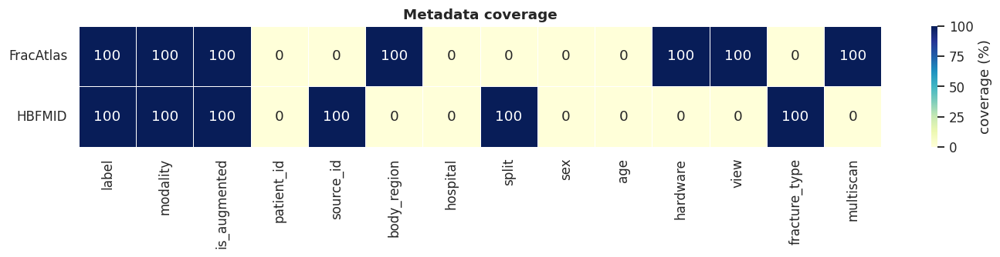

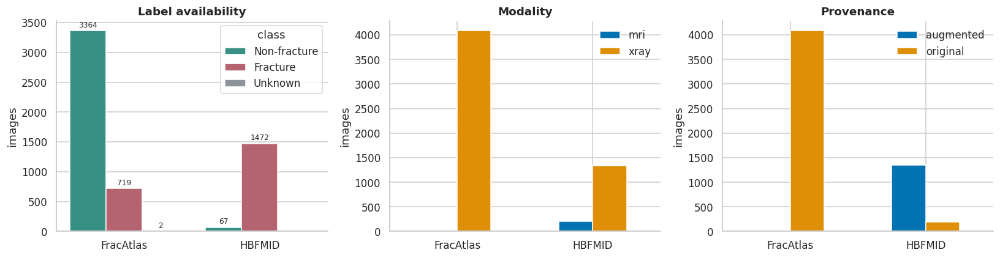

,dataset,labeled,positive,negative,prevalence,wilson_low,wilson_high,majority_class_accuracy
0,FracAtlas,4083,719,3364,0.1761,0.1647,0.1881,0.8239
1,HBFMID,1539,1472,67,0.9565,0.9451,0.9656,0.9565


[INFO] FracAtlas: prevalence 17.6%; use class weights / balanced sampling (a majority guess already scores 82.4%).


In [5]:
cov = df.groupby('dataset')[META].agg(lambda x: 100 * x.notna().mean()).apply(pd.to_numeric).astype('float64').round(1)
display(cov)
fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(cov, annot=True, fmt='.0f', cmap='YlGnBu', vmin=0, vmax=100, linewidths=.4, linecolor='white',
            cbar_kws={'label': 'coverage (%)'}, ax=ax)
ax.set(title='Metadata coverage', ylabel=''); ax.tick_params(axis='y', rotation=0); finish(fig, '01_metadata_coverage')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cls = good.groupby(['dataset', 'class']).size().rename('n').reset_index()
sns.barplot(data=cls, x='dataset', y='n', hue='class', hue_order=['Non-fracture', 'Fracture', 'Unknown'],
            palette=COLORS, ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c, fmt='%.0f', fontsize=8, padding=2)
axes[0].set(title='Label availability', xlabel='', ylabel='images')
for ax, c in zip(axes[1:], ['modality', 'is_augmented']):
    vals = good[c].astype('string').fillna('unknown')
    if c == 'is_augmented': vals = vals.replace({'0': 'original', '1': 'augmented'})
    tab = pd.crosstab(good.dataset, vals)
    tab.plot.bar(ax=ax, rot=0, color=sns.color_palette('colorblind', len(tab.columns)))
    ax.set(title={'modality': 'Modality', 'is_augmented': 'Provenance'}[c], xlabel='', ylabel='images'); ax.legend(frameon=False)
finish(fig, '02_labels_modality_provenance')

bal = []
for name, g in good.groupby('dataset'):
    y = g.label.dropna().astype(int); n, k = len(y), int(y.sum())
    if n:
        z = 1.96; ctr = (k / n + z * z / (2 * n)) / (1 + z * z / n)
        half = z * np.sqrt(k / n * (1 - k / n) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        bal.append(dict(dataset=name, labeled=n, positive=k, negative=n - k, prevalence=round(k / n, 4),
                        wilson_low=round(ctr - half, 4), wilson_high=round(ctr + half, 4),
                        majority_class_accuracy=round(max(k, n - k) / n, 4)))
bal = pd.DataFrame(bal); export(bal, 'class_balance'); display(bal)
for r in bal.itertuples():
    if r.positive in (0, r.labeled):
        note('warn', f'{r.dataset}: all labeled images are one class -> AUROC/specificity are not estimable; report sensitivity only.')
    elif r.prevalence < .3:
        note('info', f'{r.dataset}: prevalence {r.prevalence:.1%}; use class weights / balanced sampling (a majority guess already scores {r.majority_class_accuracy:.1%}).')

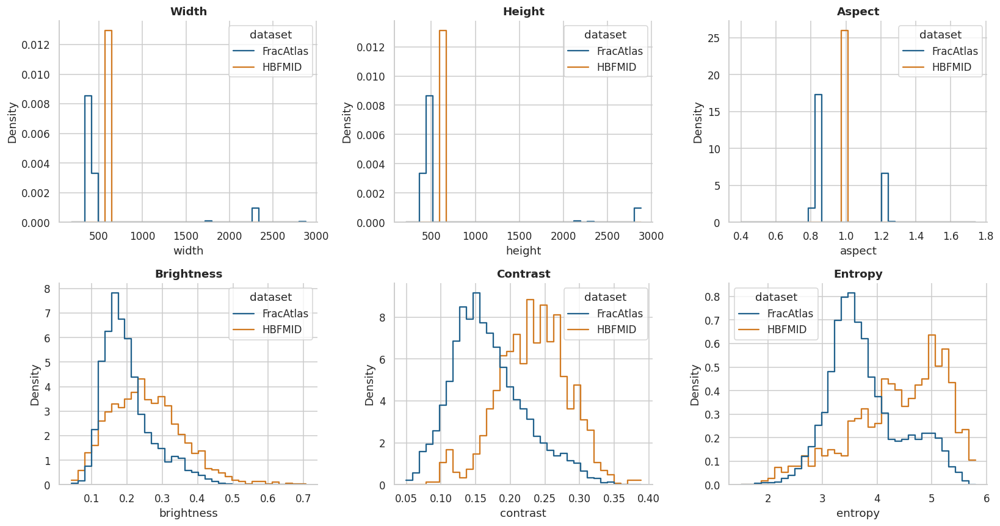

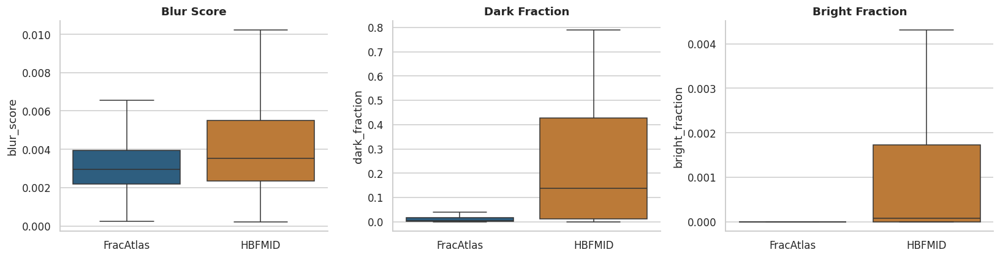

Flags are for review only; subtle fractures can look "blurry". Nothing is deleted automatically.


,small_image,near_constant,needs_decode_review,low_sharpness_1pct
dataset,,,,
FracAtlas,0,0,0,41
HBFMID,0,0,0,16


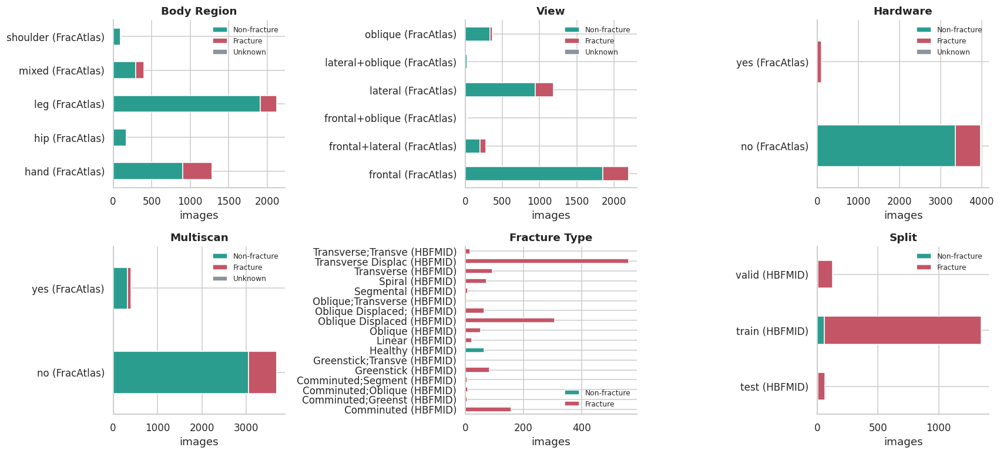

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), ['width', 'height', 'aspect', 'brightness', 'contrast', 'entropy']):
    sns.histplot(data=good, x=c, hue='dataset', palette=COLORS, element='step', fill=False, stat='density',
                 common_norm=False, bins=35, ax=ax); ax.set_title(c.title())
finish(fig, '03_resolution_intensity')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['blur_score', 'dark_fraction', 'bright_fraction']):
    sns.boxplot(data=good, x='dataset', y=c, hue='dataset', palette=COLORS, showfliers=False, ax=ax, legend=False)
    ax.set_title(c.replace('_', ' ').title()); ax.set_xlabel('')
finish(fig, '04_quality_distributions')

q = good[['dataset', 'path', 'width', 'height', 'frames', 'high_bit_depth', 'contrast', 'blur_score']].copy()
q['small_image'] = (q.width < 128) | (q.height < 128)
q['near_constant'] = q.contrast < .01
q['needs_decode_review'] = q.high_bit_depth | (q.frames > 1)
q['low_sharpness_1pct'] = q.blur_score < q.groupby('dataset').blur_score.transform(lambda x: x.quantile(.01))
export(q, 'quality_flags')
print('Flags are for review only; subtle fractures can look "blurry". Nothing is deleted automatically.')
display(q.groupby('dataset')[['small_image', 'near_constant', 'needs_decode_review', 'low_sharpness_1pct']].sum())

cols = [c for c in ['body_region', 'view', 'hardware', 'multiscan', 'fracture_type', 'split'] if good[c].notna().any()]
if cols:
    nc = 3; nr = int(np.ceil(len(cols) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(5.2 * nc, 3.6 * nr), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, c in zip(axes.ravel(), cols):
        ax.axis('on'); sub = good[good[c].notna()]
        tab = pd.crosstab(sub[c].astype(str).str[:18] + ' (' + sub.dataset + ')', sub['class'])
        tab = tab[[x for x in ['Non-fracture', 'Fracture', 'Unknown'] if x in tab.columns]]
        tab.plot.barh(stacked=True, ax=ax, color=[COLORS[x] for x in tab.columns])
        ax.set(title=c.replace('_', ' ').title(), ylabel='', xlabel='images'); ax.legend(frameon=False, fontsize=8)
    finish(fig, '05_metadata_by_class')

## 3.4 · Label sanity check against bounding boxes (FracAtlas COCO, if present)

COCO file: COCO_fracture_masks.json | boxes 924 (invalid 0)


has_box,0,1
label,,
0,3364,0
1,0,719


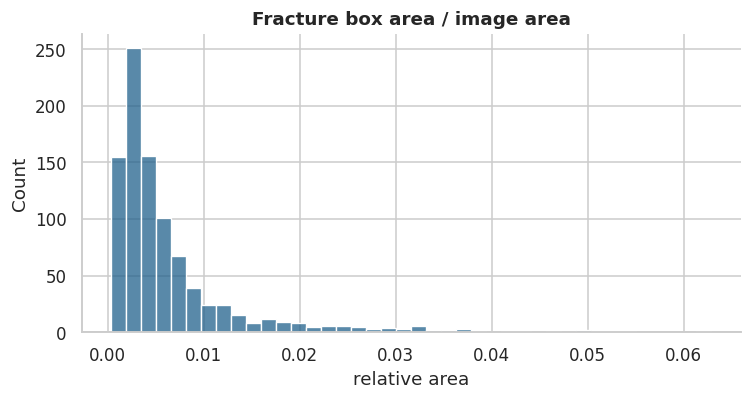

In [7]:
def find_coco(root):
    for p in sorted(root.rglob('*.json')):
        if p.stat().st_size > 300e6: continue
        try: obj = json.loads(p.read_text())
        except Exception: continue
        if isinstance(obj, dict) and {'images', 'annotations'} <= obj.keys(): return p, obj
    return None, None

coco_path, coco = find_coco(ROOTS['FracAtlas'])
good['has_box'] = pd.NA
if coco is None:
    print('No COCO annotation JSON found under the FracAtlas root; box check skipped (not verified).')
else:
    imgs = {i['id']: i for i in coco['images']}; boxes = []
    for a in coco['annotations']:
        r = imgs.get(a.get('image_id')); b = a.get('bbox') or []
        if r is None or len(b) != 4: continue
        W, H = r.get('width'), r.get('height')
        ok = bool(np.isfinite(b).all() and b[2] > 0 and b[3] > 0 and b[0] >= 0 and b[1] >= 0 and W and H
                  and b[0] + b[2] <= W + 1 and b[1] + b[3] <= H + 1)
        boxes.append(dict(file=Path(r['file_name']).name, valid=ok, rel_area=b[2] * b[3] / (W * H) if ok else np.nan))
    boxes = pd.DataFrame(boxes)
    with_box = set(boxes.loc[boxes.valid, 'file'])
    fa = good.dataset.eq('FracAtlas')
    good.loc[fa, 'has_box'] = good.loc[fa, 'filename'].isin(with_box).astype(int)
    chk = good.loc[fa & good.label.notna()].copy(); chk['has_box'] = chk.has_box.astype(int)
    print(f'COCO file: {coco_path.name} | boxes {len(boxes):,} (invalid {int((~boxes.valid).sum())})')
    display(pd.crosstab(chk.label.rename('label'), chk.has_box.rename('has_box')))
    dis = chk[chk.label != chk.has_box]
    export(dis[['relative_path', 'label', 'has_box']], 'label_vs_box_disagreements')
    if len(dis): note('warn', f'{len(dis)} FracAtlas images where label and box presence disagree (see label_vs_box_disagreements.csv).')
    if boxes.valid.any():
        fig, ax = plt.subplots(figsize=(7, 3.8)); sns.histplot(boxes.loc[boxes.valid, 'rel_area'], bins=40, color=COLORS['FracAtlas'], ax=ax)
        ax.set(title='Fracture box area / image area', xlabel='relative area'); finish(fig, '06_box_scale')

## 3.5 · Exact and near duplicates → leakage-safe families

In [8]:
ex = []
for col in ['sha256', 'pixel_sha256']:
    d = good[good.duplicated(col, keep=False)]
    if len(d): ex.append(d[['dataset', 'relative_path', 'label', 'split', col]].rename(columns={col: 'hash'}).assign(type=col))
exact = pd.concat(ex, ignore_index=True) if ex else pd.DataFrame(columns=['dataset', 'relative_path', 'label', 'split', 'hash', 'type'])
export(exact, 'exact_duplicates')
redundant = len(good) - good.pixel_sha256.nunique()
conf_ids = good.groupby('pixel_sha256').label.nunique().loc[lambda s: s > 1].index
conflicts = good[good.pixel_sha256.isin(conf_ids)]
export(conflicts[['dataset', 'relative_path', 'label', 'pixel_sha256']], 'exact_label_conflicts')
print(f'Exact: {len(exact)} duplicate records, {redundant} redundant copies | label-conflict records: {len(conflicts)}')
by_ds = good.groupby('dataset').pixel_sha256.agg(lambda s: len(s) - s.nunique())
note('info', f'redundant exact copies per dataset: { {k: int(v) for k, v in by_ds.items()} }')
if len(conflicts): note('warn', f'{len(conflicts)} images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.')

class BKTree:
    def __init__(self): self.root = None
    def add(self, v, i):
        if self.root is None: self.root = [v, [i], {}]; return
        node = self.root
        while True:
            d = popcount(v ^ node[0])
            if d == 0: node[1].append(i); return
            if d not in node[2]: node[2][d] = [v, [i], {}]; return
            node = node[2][d]
    def query(self, v, r):
        stack = [self.root] if self.root else []
        while stack:
            nv, ids, ch = stack.pop(); d = popcount(v ^ nv)
            if d <= r:
                for i in ids: yield i, d
            stack.extend(c for e, c in ch.items() if d - r <= e <= d + r)

H = [int(h, 16) for h in good.dhash]; px = good.pixel_sha256.values
tree, pr, truncated = BKTree(), [], False
for i in tqdm(range(len(good)), desc='Near-duplicate search'):
    for j, d in tree.query(H[i], NEAR_RADIUS):
        if px[j] != px[i]: pr.append((j, i, d))
    if len(pr) >= MAX_NEAR_PAIRS: truncated = True; break
    tree.add(H[i], i)
P = np.array(pr, dtype=int).reshape(-1, 3)

X = np.stack([tiny_map[p] for p in good.path]); X = X - X.mean(1, keepdims=True)
nrm = np.linalg.norm(X, axis=1, keepdims=True); Z = np.divide(X, nrm, out=np.zeros_like(X), where=nrm > 0)
corr = np.concatenate([(Z[P[k:k + 20000, 0]] * Z[P[k:k + 20000, 1]]).sum(1) for k in range(0, len(P), 20000)]) if len(P) else np.array([])
near = pd.DataFrame({'path_a': good.path.values[P[:, 0]], 'path_b': good.path.values[P[:, 1]],
                     'dataset_a': good.dataset.values[P[:, 0]], 'dataset_b': good.dataset.values[P[:, 1]],
                     'dhash_dist': P[:, 2], 'corr': corr.round(4)})
near['tier'] = np.select([(near.dhash_dist <= AUTO_GROUP_DIST) & (near['corr'] >= AUTO_GROUP_CORR), near['corr'] >= REVIEW_MIN_CORR],
                         ['auto_group', 'review'], 'distinct_auto')
near['decision'] = ''
if NEAR_REVIEW_CSV:
    dec = pd.read_csv(NEAR_REVIEW_CSV).fillna('')
    near = near.drop(columns='decision').merge(dec[['path_a', 'path_b', 'decision']], on=['path_a', 'path_b'], how='left').fillna({'decision': ''})
    assert near.decision.isin(['', 'same_source', 'distinct']).all(), 'decision must be same_source / distinct / blank'
near['link'] = ((near.decision == 'same_source') | ((near.decision == '') & (near.tier == 'auto_group'))
                | ((near.decision == '') & (near.tier == 'review') & GROUP_UNREVIEWED))
export(near.loc[near.tier != 'distinct_auto'].sort_values(['tier', 'corr'], ascending=[True, False]).drop(columns='link'), 'near_duplicate_review')
print(f'Near candidates {len(near):,} (search truncated: {truncated})')
display(pd.crosstab(near.tier, (near.dataset_a != near.dataset_b).map({True: 'cross-dataset', False: 'within dataset'})))
if truncated: note('error', 'near-duplicate search hit MAX_NEAR_PAIRS; raise it and rerun before splitting.')

parent = list(range(len(good)))
def find(i):
    while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a, b): parent[find(b)] = find(a)
for key, scope in [('sha256', None), ('pixel_sha256', None), ('patient_id', 'dataset'), ('source_id', 'dataset')]:
    sub = good.dropna(subset=[key])
    for ids in (sub.groupby(key) if scope is None else sub.groupby([scope, key])).groups.values():
        ids = list(ids)
        for j in ids[1:]: union(ids[0], j)
pos = dict(zip(good.path, good.index))
for r in near.loc[near.link].itertuples(): union(pos[r.path_a], pos[r.path_b])
good['group_id'] = [f'g{find(i):06d}' for i in good.index]
gs = good.groupby('group_id').size()
print(f'Families: {len(gs):,} | multi-image families: {(gs > 1).sum():,} | largest family: {gs.max()} images ({gs.max() / len(good):.1%})')
if gs.max() / len(good) > .05: note('warn', 'one family holds >5% of all images: loosen GROUP_UNREVIEWED or AUTO_GROUP_CORR, or review near_duplicate_review.csv.')
ov = good.groupby('group_id').agg(datasets=('dataset', 'nunique'), splits=('split', 'nunique'), images=('path', 'size'))
export(ov.loc[(ov.datasets > 1) | (ov.splits > 1)].reset_index(), 'families_spanning_datasets_or_splits')
n_x = int((ov.datasets > 1).sum()); n_s = int((ov.splits > 1).sum())
if n_x: note('warn', f'{n_x} families contain images from BOTH datasets (external-set overlap; removed from the external set later).')
if n_s: note('warn', f'{n_s} families span more than one published split (publisher splits leak; this notebook re-splits).')
summary.update(exact_redundant=int(redundant), label_conflict_records=len(conflicts), near_candidates=len(near),
               near_auto_group=int((near.tier == 'auto_group').sum()), near_review=int((near.tier == 'review').sum()),
               near_truncated=bool(truncated), families=int(len(gs)), largest_family=int(gs.max()))
export(good, 'grouped_image_audit')

Exact: 198 duplicate records, 86 redundant copies | label-conflict records: 7
[INFO] redundant exact copies per dataset: {'FracAtlas': 86, 'HBFMID': 0}
[WARN] 7 images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.


Near-duplicate search:   0%|          | 0/5624 [00:00<?, ?it/s]

Near candidates 941 (search truncated: False)


col_0,cross-dataset,within dataset
tier,,
auto_group,0,195
distinct_auto,0,122
review,16,608


Families: 4,029 | multi-image families: 440 | largest family: 52 images (0.9%)
[WARN] 3 families contain images from BOTH datasets (external-set overlap; removed from the external set later).
[WARN] 20 families span more than one published split (publisher splits leak; this notebook re-splits).


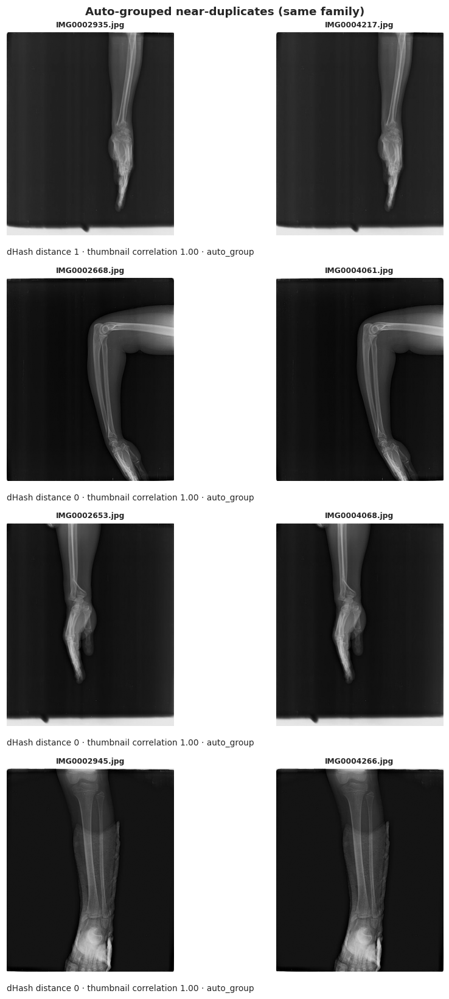

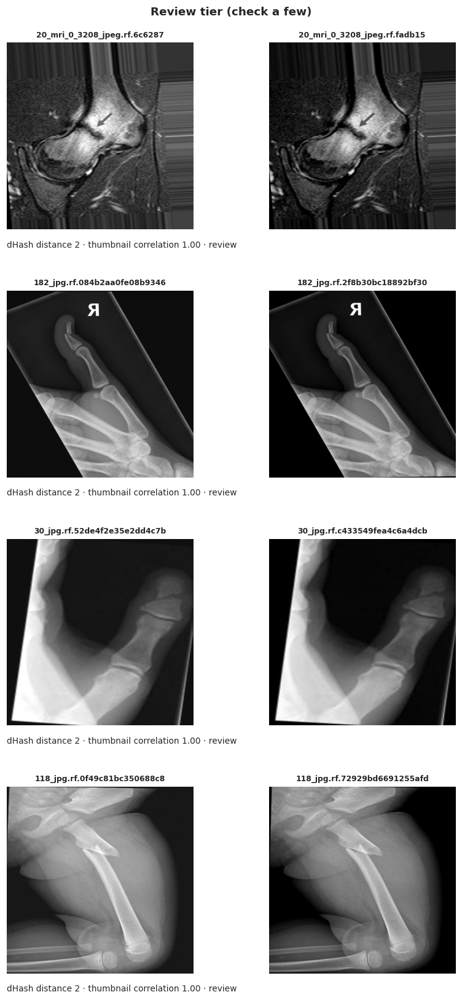

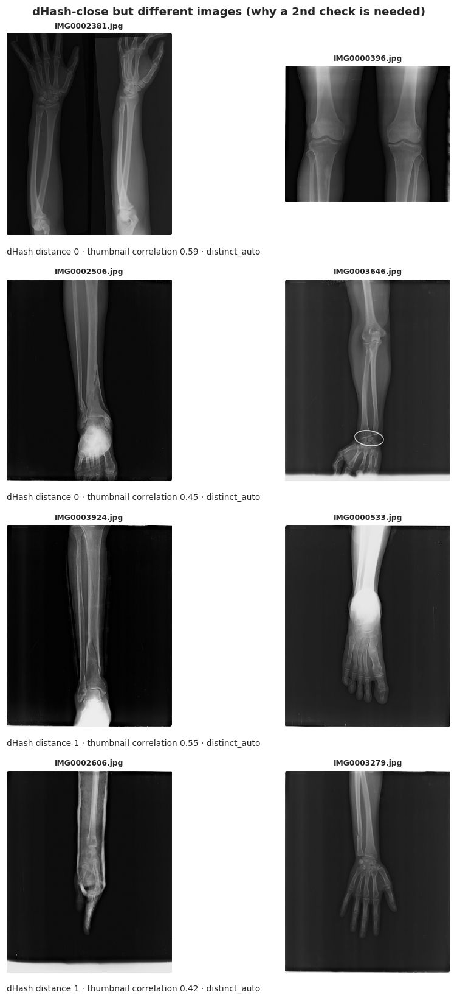

In [9]:
def pair_gallery(pairs, title, name, n=4):
    pairs = pairs.head(n)
    if pairs.empty: return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(7, 3.8 * len(pairs)), squeeze=False)
    for row, (_, r) in zip(axes, pairs.iterrows()):
        for ax, p in zip(row, [r.path_a, r.path_b]):
            with Image.open(p) as im: g = safe_rgb(im).convert('L'); g.thumbnail((480, 480))
            ax.imshow(g, cmap='gray', vmin=0, vmax=255); ax.axis('off')
        row[0].set_title(Path(r.path_a).name[:28], fontsize=8); row[1].set_title(Path(r.path_b).name[:28], fontsize=8)
        row[0].text(0.0, -0.06, f'dHash distance {r.dhash_dist} · thumbnail correlation {r["corr"]:.2f} · {r.tier}',
                    transform=row[0].transAxes, fontsize=9, va='top')
    fig.suptitle(title, fontsize=12, fontweight='bold'); finish(fig, name, svg=False)

if DISPLAY_GALLERIES:
    pair_gallery(near[near.tier == 'auto_group'].sort_values('corr', ascending=False), 'Auto-grouped near-duplicates (same family)', '07_pairs_auto')
    pair_gallery(near[near.tier == 'review'].sort_values('corr', ascending=False), 'Review tier (check a few)', '07_pairs_review')
    pair_gallery(near[near.tier == 'distinct_auto'].sort_values('dhash_dist'), 'dHash-close but different images (why a 2nd check is needed)', '07_pairs_rejected')

## 3.6 · Galleries and dataset shift

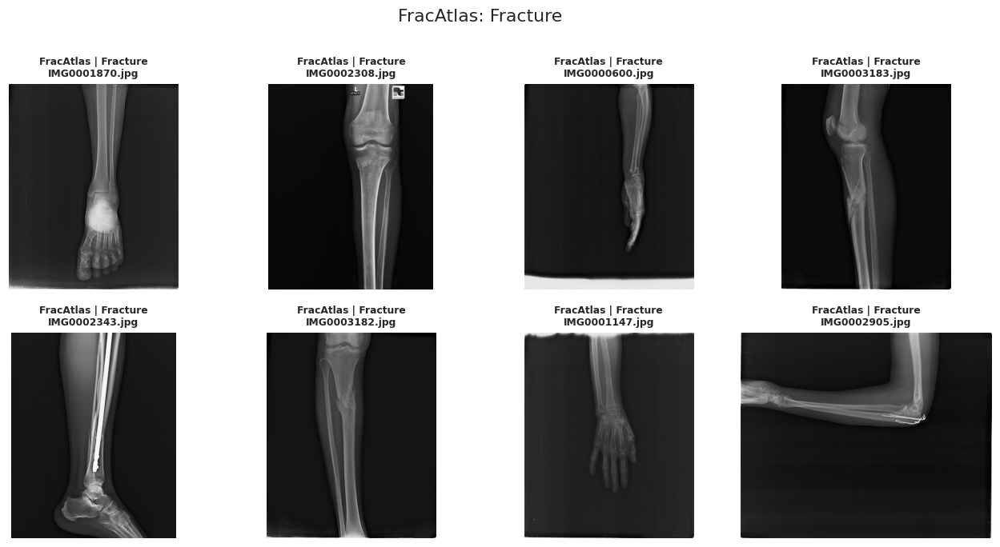

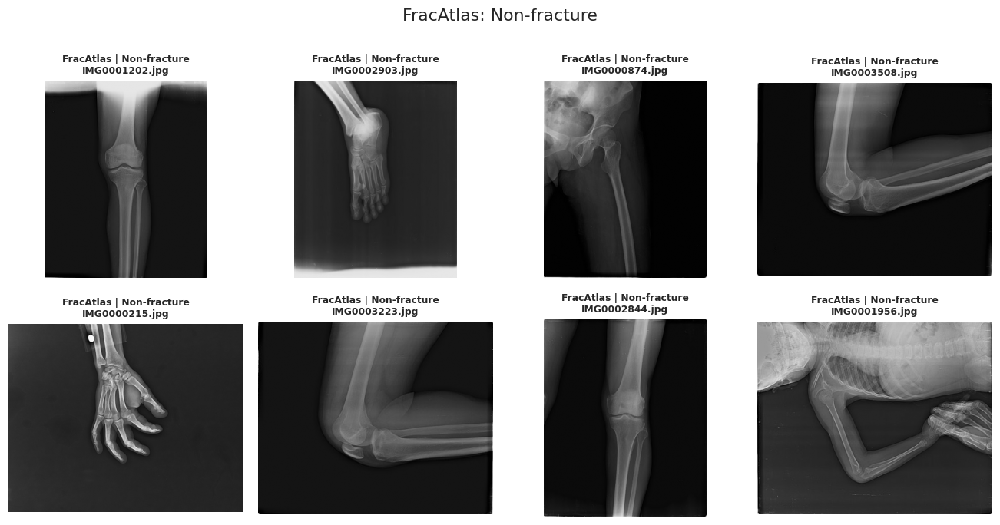

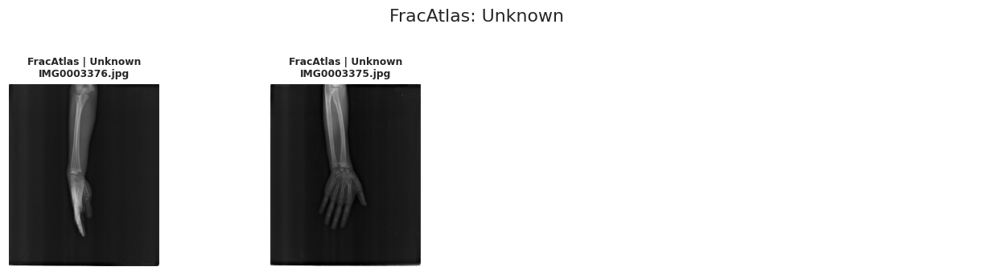

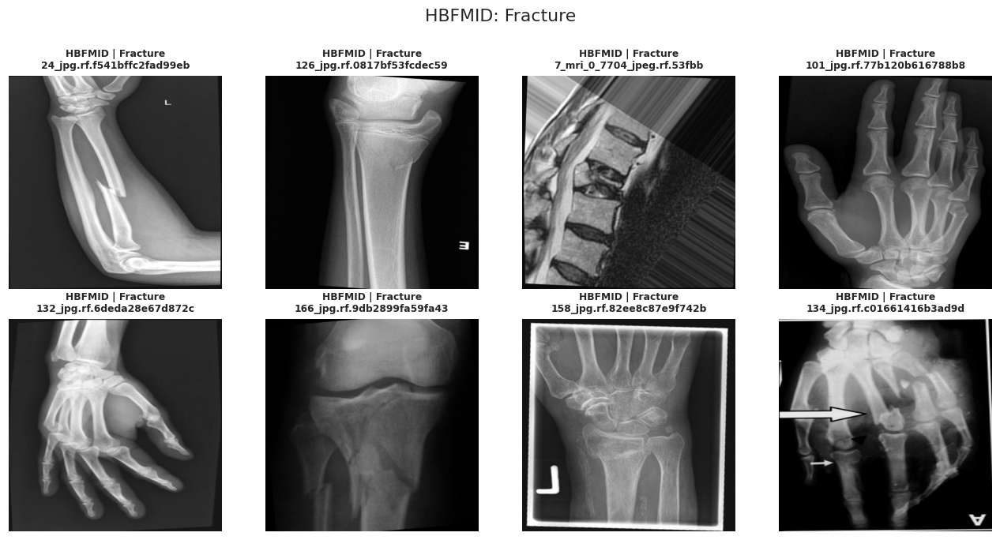

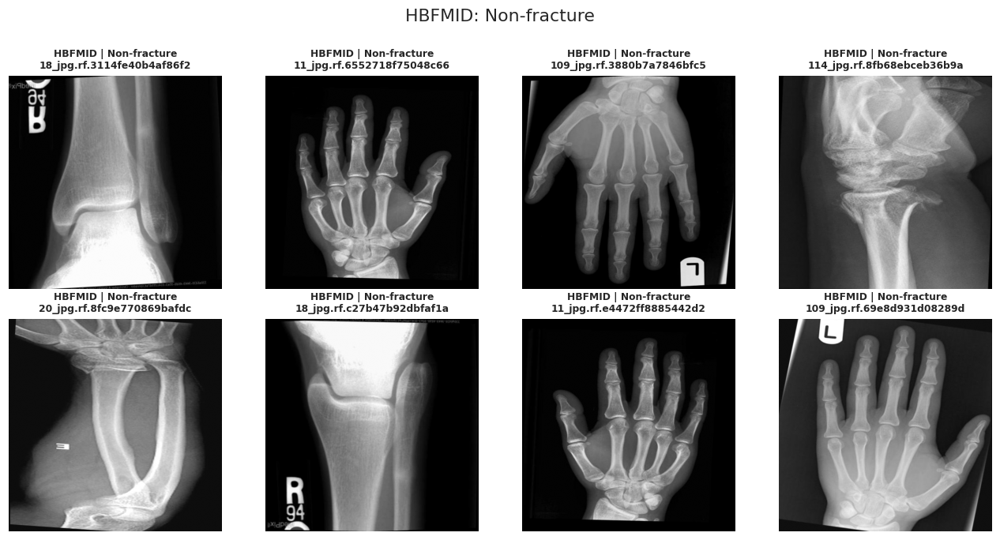

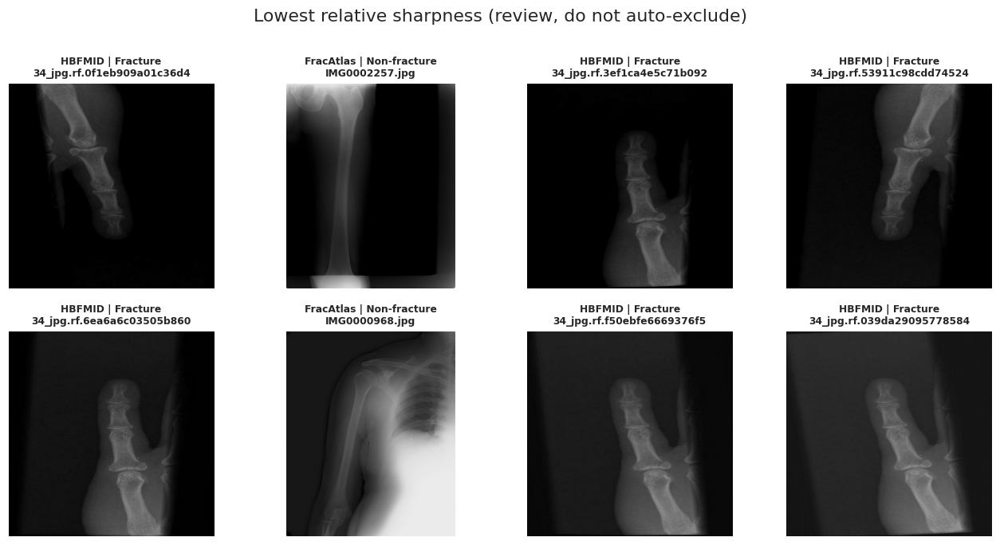

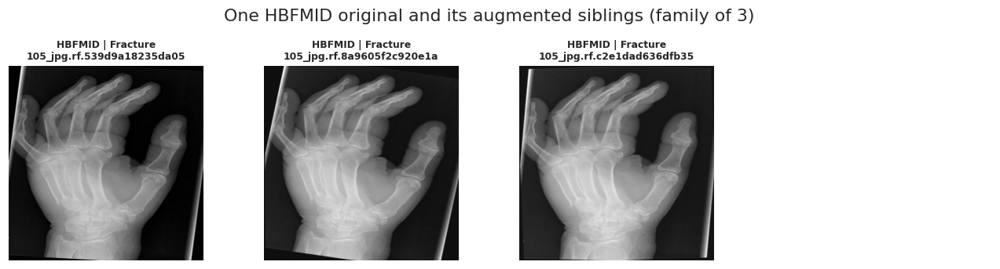

,aspect,brightness,contrast,entropy,blur_score,dark_fraction,bright_fraction,border_mean
dataset,,,,,,,,
FracAtlas,0.822,0.186,0.160,3.645,0.003,0.004,0.0,0.307
HBFMID,1.000,0.247,0.236,4.531,0.004,0.137,0.0,0.081


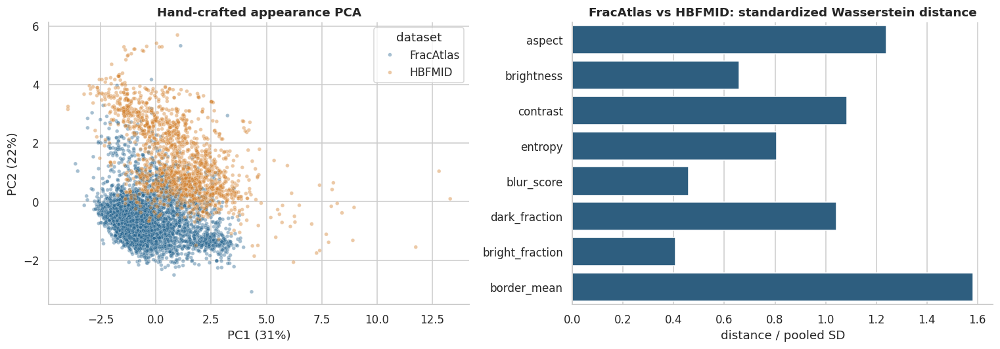

In [10]:
def gallery(rows, title, name, cols=4):
    rows = rows.head(12)
    if rows.empty: return
    nr = int(np.ceil(len(rows) / cols))
    fig, axes = plt.subplots(nr, cols, figsize=(cols * 3, 3.1 * nr), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        with Image.open(r.path) as im: g = safe_rgb(im).convert('L'); g.thumbnail((512, 512))
        ax.imshow(g, cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'{r.dataset} | {r["class"]}\n{Path(r.path).name[:26]}', fontsize=8)
    fig.suptitle(title, y=1.0); finish(fig, name, svg=False)

if DISPLAY_GALLERIES:
    for (ds, cl), sub in good.groupby(['dataset', 'class']):
        gallery(sub.sample(min(8, len(sub)), random_state=SEED), f'{ds}: {cl}', f'08_gallery_{ds}_{cl}')
    gallery(good.nsmallest(8, 'blur_score'), 'Lowest relative sharpness (review, do not auto-exclude)', '09_low_sharpness')
    fam = good[(good.dataset == 'HBFMID') & good.source_id.notna()]
    sizes = fam.groupby('source_id').size(); pick = sizes[sizes == 3].index
    if len(pick): gallery(fam[fam.source_id == pick[0]], 'One HBFMID original and its augmented siblings (family of 3)', '10_hbfmid_family')

FEATURES = ['aspect', 'brightness', 'contrast', 'entropy', 'blur_score', 'dark_fraction', 'bright_fraction', 'border_mean']
display(good.groupby('dataset')[FEATURES].median().round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(good) >= 3 and good.dataset.nunique() > 1:
    zc = PCA(2, random_state=SEED).fit(StandardScaler().fit_transform(good[FEATURES].fillna(0)))
    emb = zc.transform(StandardScaler().fit_transform(good[FEATURES].fillna(0)))
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=good.dataset, palette=COLORS, alpha=.4, s=14, ax=axes[0])
    axes[0].set(title='Hand-crafted appearance PCA', xlabel=f'PC1 ({zc.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({zc.explained_variance_ratio_[1]:.0%})')
    a_n, b_n = good.dataset.unique()[:2]; sh = []
    for c in FEATURES:
        a = good.loc[good.dataset == a_n, c].dropna(); b = good.loc[good.dataset == b_n, c].dropna(); sd = good[c].std()
        sh.append({'feature': c, 'shift': wasserstein_distance(a, b) / sd if sd > 0 else np.nan})
    sh = pd.DataFrame(sh); export(sh, 'appearance_shift')
    sns.barplot(data=sh, x='shift', y='feature', color=COLORS['FracAtlas'], ax=axes[1])
    axes[1].set(title=f'{a_n} vs {b_n}: standardized Wasserstein distance', xlabel='distance / pooled SD', ylabel='')
finish(fig, '11_dataset_shift')

## 3.7 · Eligibility waterfall

In [11]:
def waterfall(frame, steps):
    cur = frame; rows = [('readable', len(cur), int(cur.label.fillna(0).sum()))]
    for text, fn in steps:
        cur = cur.loc[fn(cur).fillna(False).astype(bool)]
        rows.append((text, len(cur), int(cur.label.fillna(0).sum())))
    return cur, pd.DataFrame(rows, columns=['step', 'images', 'fractured'])

common = [('single-frame, not high-bit-depth', lambda d: (d.frames == 1) & ~d.high_bit_depth),
          ('not a label-conflict copy', lambda d: ~d.pixel_sha256.isin(conf_ids)),
          ('label agrees with COCO boxes (if available)', lambda d: pd.to_numeric(d.has_box, errors='coerce').isna()
                                                                   | (pd.to_numeric(d.has_box, errors='coerce') == d.label.astype('float')))]
prim_pool, wf_p = waterfall(good[good.dataset == 'FracAtlas'].sort_values('relative_path'),
    [('label known', lambda d: d.label.notna()), ('X-ray', lambda d: d.modality.eq('xray')),
     ('original (not augmented)', lambda d: d.is_augmented.eq(0))] + common)
primary = prim_pool.drop_duplicates('pixel_sha256').copy()
wf_p.loc[len(wf_p)] = ['exact duplicates removed', len(primary), int(primary.label.sum())]
ext_pool, wf_e = waterfall(good[good.dataset == 'HBFMID'],
    [('label known', lambda d: d.label.notna()), ('X-ray', lambda d: d.modality.eq('xray')),
     ('original (valid/test, not augmented)', lambda d: d.is_augmented.eq(0))] + common)
external = ext_pool.drop_duplicates('pixel_sha256').copy()
overlap = external.group_id.isin(primary.group_id)
export(external[overlap], 'external_overlap_exclusions')
external = external[~overlap].copy()
wf_e.loc[len(wf_e)] = ['no overlap with FracAtlas families', len(external), int(external.label.sum())]
display(wf_p.assign(set='FracAtlas (primary)')); display(wf_e.assign(set='HBFMID (external)'))
export(pd.concat([wf_p.assign(set='primary'), wf_e.assign(set='external')]), 'eligibility_waterfall')
export(good[~good.path.isin(set(primary.path) | set(external.path))][['dataset', 'relative_path', 'label', 'modality', 'is_augmented', 'group_id']], 'excluded_or_unresolved')
n_neg_ext = int((external.label == 0).sum()) if len(external) else 0
if len(external) and n_neg_ext < 30:
    note('warn', f'External set has only {n_neg_ext} negatives (HBFMID "Healthy", mostly augmented copies of few originals): '
                 'specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.')
if primary.empty: note('error', 'No eligible FracAtlas images; fix labels/metadata (sections 2-3) before continuing.')
if external.empty:
    why = 'HBFMID has no labels' if good[good.dataset == 'HBFMID'].label.isna().all() else 'no labeled X-ray originals remain'
    note('warn', f'External set is empty: {why}. HBFMID stays pending until labels/originals are confirmed.')
elif external.label.nunique() < 2:
    note('warn', f'External set is single-class (all label={int(external.label.iloc[0])}): report sensitivity only; no AUROC/specificity.')
summary.update(primary_images=len(primary), primary_positive=int(primary.label.sum()) if len(primary) else 0,
               external_images=len(external), external_single_class=bool(len(external) and external.label.nunique() < 2))

,step,images,fractured,set
0,readable,4085,719,FracAtlas (primary)
1,label known,4083,719,FracAtlas (primary)
2,X-ray,4083,719,FracAtlas (primary)
3,original (not augmented),4083,719,FracAtlas (primary)
4,"single-frame, not high-bit-depth",4083,719,FracAtlas (primary)
5,not a label-conflict copy,4076,716,FracAtlas (primary)
6,label agrees with COCO boxes (if available),4076,716,FracAtlas (primary)
7,exact duplicates removed,3996,701,FracAtlas (primary)


,step,images,fractured,set
0,readable,1539,1472,HBFMID (external)
1,label known,1539,1472,HBFMID (external)
2,X-ray,1337,1270,HBFMID (external)
3,"original (valid/test, not augmented)",164,154,HBFMID (external)
4,"single-frame, not high-bit-depth",164,154,HBFMID (external)
5,not a label-conflict copy,164,154,HBFMID (external)
6,label agrees with COCO boxes (if available),164,154,HBFMID (external)
7,no overlap with FracAtlas families,161,151,HBFMID (external)


[WARN] External set has only 10 negatives (HBFMID "Healthy", mostly augmented copies of few originals): specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.


## 3.8 · Grouped split, label budgets and training statistics

,images,fractured,families,prevalence,image_share
proposed_split,,,,,
test,771,122,711,0.158,0.193
train,2821,507,2603,0.18,0.706
validation,404,72,374,0.178,0.101


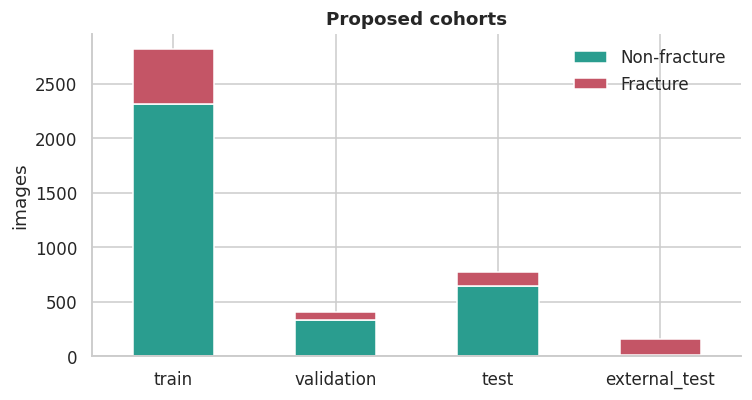

[INFO] label budgets [0.01] contain <10 fractured images: results at those sizes are very unstable.


,seed,fraction,families,images,image_share,fractured,non_fractured
0,42,0.01,27,29,0.010,5,24
1,42,0.05,131,135,0.048,24,111
2,42,0.10,261,268,0.095,49,219
3,42,0.25,652,728,0.258,135,593
4,42,1.00,2603,2821,1.000,507,2314


{
  "train_images": 2821,
  "class_weights": {
    "non_fracture": 0.6096,
    "fracture": 2.7821,
    "pos_weight_for_BCEWithLogits": 4.5641
  },
  "grayscale_mean": 0.2031,
  "grayscale_std": 0.1909,
  "note": "thumbnail estimate; recompute at final input size"
}


In [12]:
READY = False
if not MAKE_SPLITS: print('MAKE_SPLITS is False; skipped.')
elif primary.empty or truncated: note('error', 'Split skipped (no eligible images or incomplete near-duplicate search).')
elif primary.patient_id.isna().any() and not ALLOW_IMAGE_LEVEL_SPLIT: note('error', 'Patient IDs missing and ALLOW_IMAGE_LEVEL_SPLIT=False.')
elif primary.label.nunique() < 2 or primary.groupby('label').group_id.nunique().min() < 10:
    note('error', 'Need both classes with >=10 families each for the 10-fold design.')
else:
    primary = primary.reset_index(drop=True)
    folds = np.full(len(primary), -1)
    cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
    for k, (_, idx) in enumerate(cv.split(primary, primary.label.astype(int), primary.group_id)): folds[idx] = k
    primary['proposed_split'] = np.where(folds < 2, 'test', np.where(folds == 2, 'validation', 'train'))
    assert primary.groupby('group_id').proposed_split.nunique().max() == 1, 'a family straddles splits'
    assert primary.groupby('pixel_sha256').proposed_split.nunique().max() == 1, 'identical pixels in two splits'
    for s, g in primary.groupby('proposed_split'): assert g.label.nunique() == 2, f'{s} has one class'
    primary['patient_level'] = primary.patient_id.notna()
    external['proposed_split'] = 'external_test'
    manifest = pd.concat([primary, external], ignore_index=True)
    export(manifest.drop(columns=['tiny'], errors='ignore'), 'split_manifest')
    tab = primary.groupby('proposed_split').agg(images=('path', 'size'), fractured=('label', 'sum'), families=('group_id', 'nunique'))
    tab['prevalence'] = (tab.fractured / tab.images).round(3); tab['image_share'] = (tab.images / len(primary)).round(3)
    display(tab); export(tab.reset_index(), 'split_summary')
    fig, ax = plt.subplots(figsize=(7, 3.8))
    (pd.crosstab(manifest.proposed_split, manifest.label).rename(columns={0: 'Non-fracture', 1: 'Fracture'})
       .reindex(['train', 'validation', 'test', 'external_test']).dropna(how='all')
       .plot.bar(stacked=True, ax=ax, color=[COLORS['Non-fracture'], COLORS['Fracture']], rot=0))
    ax.set(title='Proposed cohorts', xlabel='', ylabel='images'); ax.legend(frameon=False); finish(fig, '12_split_counts')

    train = primary[primary.proposed_split == 'train']
    export(train[['path', 'group_id']], 'ssl_train_pool')
    gt = train.groupby('group_id').label.max()
    bud, rows, tiny_budget = [], [], set()
    for seed in BUDGET_SEEDS:
        rng = np.random.default_rng(seed)
        order = {int(l): rng.permutation(gg.index.to_numpy()) for l, gg in gt.groupby(gt)}
        prev = set()
        for f in BUDGET_FRACTIONS:
            sel = set()
            for l, ids in order.items(): sel.update(ids[:max(1, int(np.ceil(len(ids) * f)))])
            assert prev <= sel; prev = sel
            sub = train[train.group_id.isin(sel)]
            if sub.label.nunique() < 2: note('warn', f'budget {f:.0%} seed {seed} has one class')
            if sub.label.sum() < 10: tiny_budget.add(f)
            rows.append(sub[['path', 'group_id', 'label']].assign(seed=seed, fraction=f))
            bud.append(dict(seed=seed, fraction=f, families=len(sel), images=len(sub), image_share=round(len(sub) / len(train), 3),
                            fractured=int(sub.label.sum()), non_fractured=int((sub.label == 0).sum())))
    if tiny_budget: note('info', f'label budgets {sorted(tiny_budget)} contain <10 fractured images: results at those sizes are very unstable.')
    export(pd.concat(rows), 'label_budgets'); bud = pd.DataFrame(bud); export(bud, 'label_budget_summary')
    display(bud[bud.seed == BUDGET_SEEDS[0]])

    n1, n0 = int(train.label.sum()), int((train.label == 0).sum())
    class_weights = {'non_fracture': round(len(train) / (2 * n0), 4), 'fracture': round(len(train) / (2 * n1), 4),
                     'pos_weight_for_BCEWithLogits': round(n0 / n1, 4)}
    npx = train.thumbnail_pixels.sum(); mean = train.intensity_sum.sum() / npx
    std = float(np.sqrt(max(0., train.intensity_sq_sum.sum() / npx - mean ** 2)))
    stats = {'train_images': len(train), 'class_weights': class_weights, 'grayscale_mean': round(float(mean), 4),
             'grayscale_std': round(std, 4), 'note': 'thumbnail estimate; recompute at final input size'}
    (OUT / 'train_statistics.json').write_text(json.dumps(stats, indent=2)); print(json.dumps(stats, indent=2))
    summary.update(splits_generated=True, patient_level_split=bool(primary.patient_id.notna().all()), train_stats=stats)
    READY = True
_ = summary.setdefault('splits_generated', False)

## 3.9 · Summary, findings and exports (data part)

,dataset,readable,labeled,xray,originals,augmented,unique_pixels,eligible
0,FracAtlas,4085,4083,4085,4085,0,3999,3996
1,HBFMID,1539,1539,1337,192,1347,1539,161


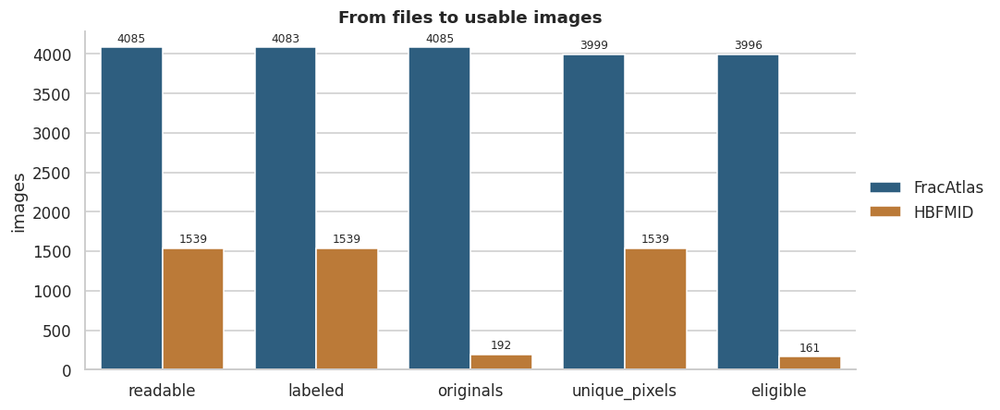


===== FINDINGS =====
[WARN ] FracAtlas: 4 files share a filename across folders (duplicate_filenames.csv). Each is labelled only if its folder agrees with the CSV; otherwise the label stays unknown and the image is excluded.
[WARN ] FracAtlas: 2 images where folder label and CSV label disagree (label_source_conflicts.csv); left unlabeled and excluded.
[WARN ] 7 images share pixels with images of the OPPOSITE label (label noise); they are removed from the cohort.
[WARN ] 3 families contain images from BOTH datasets (external-set overlap; removed from the external set later).
[WARN ] 20 families span more than one published split (publisher splits leak; this notebook re-splits).
[WARN ] External set has only 10 negatives (HBFMID "Healthy", mostly augmented copies of few originals): specificity/AUROC there are unreliable; report sensitivity with a Wilson interval.
[INFO ] HBFMID: 1,539/1,539 images matched to a YOLO label file.
[INFO ] FracAtlas: prevalence 17.6%; use class weights / bal

In [13]:
dash = good.groupby('dataset').agg(readable=('path', 'size'), labeled=('label', 'count'),
        xray=('modality', lambda s: int(s.eq('xray').sum())), originals=('is_augmented', lambda s: int(s.eq(0).sum())),
        augmented=('is_augmented', lambda s: int(s.eq(1).sum())), unique_pixels=('pixel_sha256', 'nunique')).reset_index()
dash['eligible'] = dash.dataset.map({'FracAtlas': len(primary), 'HBFMID': len(external)})
export(dash, 'executive_summary'); display(dash)
long = dash.melt(id_vars='dataset', value_vars=['readable', 'labeled', 'originals', 'unique_pixels', 'eligible'], var_name='stage', value_name='images')
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=long, x='stage', y='images', hue='dataset', palette=COLORS, ax=ax)
for c in ax.containers: ax.bar_label(c, fmt='%.0f', fontsize=8, padding=2)
ax.set(title='From files to usable images', xlabel='', ylabel='images'); sns.move_legend(ax, 'center left', bbox_to_anchor=(1, .5), frameon=False, title=''); finish(fig, '15_executive_summary')

known_aug = int(good.is_augmented.notna().sum())
summary['augmentation_decision'] = ('FracAtlas: mild on-the-fly training-only augmentation + class weights; '
                                    'HBFMID: already augmented, add none, evaluate on originals only.')
(OUT / 'audit_summary.json').write_text(json.dumps(summary, indent=2, default=str))

print('\n===== FINDINGS =====')
order = {'error': 0, 'warn': 1, 'info': 2}
for lvl, msg in sorted(FINDINGS, key=lambda t: order[t[0]]): print(f'[{lvl.upper():5}] {msg}')
pd.DataFrame(FINDINGS, columns=['level', 'message']).to_csv(OUT / 'findings.csv', index=False)
print('\nData-part outputs so far:', OUT)

# Section 4: Data Preprocessing & Augmentation

## 4.1 · Augmentation policy (training only)

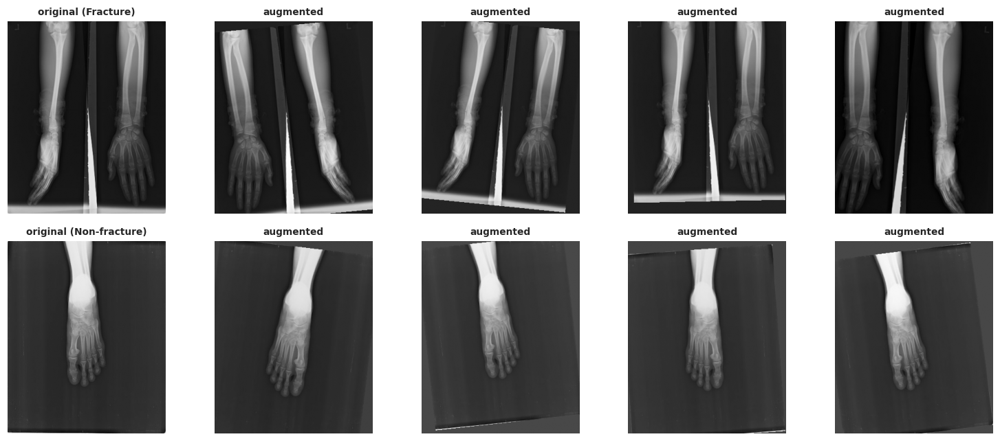

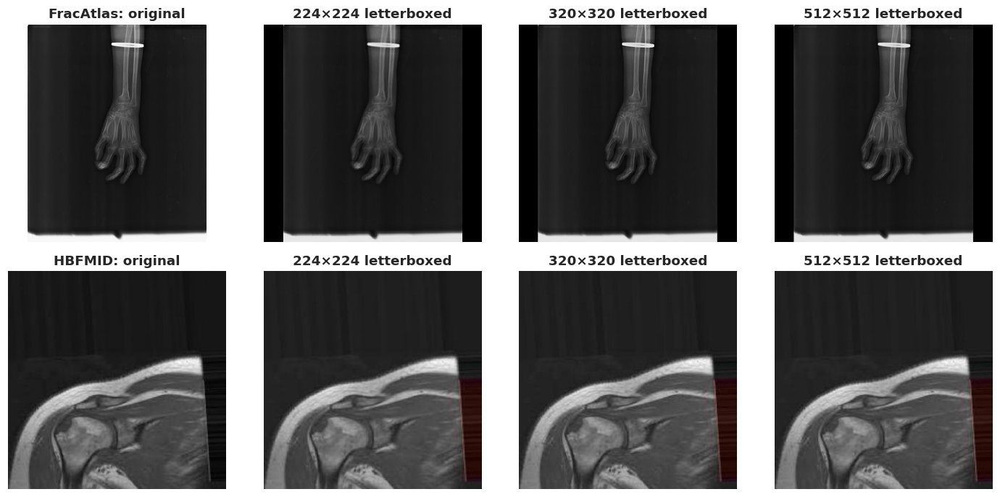

In [14]:
POLICY = {'apply_to': 'train split only, on the fly', 'rotation_deg': 10, 'scale': [0.92, 1.08], 'translate_frac': 0.05,
          'hflip_p': 0.5, 'brightness_shift': 0.05, 'contrast_range': [0.9, 1.1],
          'never': ['vertical flip', 'strong crop / random-erasing over the bone', 'elastic warps', 'any change to val/test'],
          'fill': 'border median (no black wedges)',
          'blur_noise_jpeg': ROBUST_AUG, 'test_time': 'horizontal-flip averaging'}
(OUT / 'augmentation_policy.json').write_text(json.dumps(POLICY, indent=2))

def mild_aug(g, rng):
    w, h = g.size; cx, cy = w / 2, h / 2
    th = np.deg2rad(rng.uniform(-POLICY['rotation_deg'], POLICY['rotation_deg'])); sc = rng.uniform(*POLICY['scale'])
    tx, ty = rng.uniform(-1, 1, 2) * POLICY['translate_frac'] * np.array([w, h]); c, s = np.cos(th), np.sin(th)
    arr = np.asarray(g); border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    out = g.transform((w, h), Image.AFFINE, (c / sc, s / sc, cx - (c * cx + s * cy) / sc - tx,
                                              -s / sc, c / sc, cy - (-s * cx + c * cy) / sc - ty),
                      resample=Image.Resampling.BILINEAR, fillcolor=int(np.median(border)))
    if rng.random() < POLICY['hflip_p']: out = ImageOps.mirror(out)
    a = np.asarray(out, dtype=np.float32); m = a.mean()
    a = (a - m) * rng.uniform(*POLICY['contrast_range']) + m + rng.uniform(-1, 1) * POLICY['brightness_shift'] * 255
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))

pool = train if READY else good[good.dataset == 'FracAtlas']
if DISPLAY_GALLERIES and len(pool):
    rng = np.random.default_rng(SEED)
    picks = [pool[pool.label == 1].sample(1, random_state=SEED).iloc[0]] if (pool.label == 1).any() else []
    picks += [pool[pool.label == 0].sample(1, random_state=SEED).iloc[0]] if (pool.label == 0).any() else []
    fig, axes = plt.subplots(len(picks), 5, figsize=(14, 3 * len(picks)), squeeze=False)
    for row, r in zip(axes, picks):
        with Image.open(r.path) as im: g = safe_rgb(im).convert('L'); g.thumbnail((384, 384))
        row[0].imshow(g, cmap='gray', vmin=0, vmax=255); row[0].set_title(f'original ({r["class"]})', fontsize=9)
        for ax in row[1:]: ax.imshow(mild_aug(g, rng), cmap='gray', vmin=0, vmax=255); ax.set_title('augmented', fontsize=9)
        for ax in row: ax.axis('off')
    finish(fig, '13_augmentation_preview', svg=False)

def letterbox(im, size):
    im = safe_rgb(im); r = ImageOps.contain(im, (size, size), Image.Resampling.LANCZOS)
    c = Image.new('RGB', (size, size)); c.paste(r, ((size - r.width) // 2, (size - r.height) // 2)); return c
if DISPLAY_GALLERIES:
    ex = good.groupby('dataset', group_keys=False).sample(1, random_state=SEED)
    fig, axes = plt.subplots(len(ex), 4, figsize=(13, 3.2 * len(ex)), squeeze=False)
    for row, (_, r) in zip(axes, ex.iterrows()):
        with Image.open(r.path) as im:
            row[0].imshow(safe_rgb(im).convert('L'), cmap='gray'); row[0].set_title(f'{r.dataset}: original')
            for ax, s in zip(row[1:], [224, IMG_SIZE, HIRES]): ax.imshow(letterbox(im, s)); ax.set_title(f'{s}×{s} letterboxed')
        for ax in row: ax.axis('off')
    finish(fig, '14_input_resolution_preview', svg=False)

## 4.2 · Load the frozen split, check for leakage, cache the model inputs

In [15]:
if not READY: raise RuntimeError('The split was not created (see FINDINGS above). Fix Section 3 first.')
man = manifest.copy()
need = {'path', 'label', 'proposed_split', 'group_id', 'dataset'}
if not need <= set(man.columns): raise ValueError(f'manifest is missing columns: {need - set(man.columns)}')
man = man.dropna(subset=['label']).copy(); man['label'] = man.label.astype(int)
parts = {s: man[man.proposed_split == s].reset_index(drop=True) for s in ['train', 'validation', 'test']}
ext = man[man.proposed_split == 'external_test'].reset_index(drop=True)
for a_, b_ in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert not (set(parts[a_].group_id) & set(parts[b_].group_id)), f'family leakage between {a_} and {b_}'
    assert not (set(parts[a_].path) & set(parts[b_].path)), f'file overlap between {a_} and {b_}'
for s, d_ in parts.items(): assert d_.label.nunique() == 2, f'{s} needs both classes'
split_tab = pd.DataFrame({s: dict(images=len(d_), fractured=int(d_.label.sum()), healthy=int((d_.label == 0).sum()),
                                  prevalence=round(d_.label.mean(), 3), families=d_.group_id.nunique())
                          for s, d_ in {**parts, 'external (HBFMID)': ext}.items() if len(d_)}).T
split_tab.to_csv(OUT / 'table_split_summary.csv'); display(split_tab)

def load_square(path, size):
    with Image.open(path) as im:
        g = safe_rgb(im).convert('L')
    W, H = g.size
    g = ImageOps.contain(g, (size, size), Image.Resampling.LANCZOS)
    canvas = Image.new('L', (size, size), 0)
    ox, oy = (size - g.width) // 2, (size - g.height) // 2
    canvas.paste(g, (ox, oy))
    return torch.from_numpy(np.asarray(canvas).copy()), (W, H, g.width, g.height, ox, oy)

def to_model_res(hi):
    if hi.shape[-1] == IMG_SIZE: return hi
    x = F.interpolate(hi.float().unsqueeze(1), size=(IMG_SIZE, IMG_SIZE), mode='bilinear', antialias=True, align_corners=False)
    return x.round().clamp(0, 255).to(torch.uint8)[:, 0]

paths = sorted(set(man.path))
with ThreadPoolExecutor(max_workers=WORKERS) as ex_pool:
    loaded = list(tqdm(ex_pool.map(lambda p: load_square(p, HIRES), paths), total=len(paths), desc='Caching images'))
IMGS_HI = {p: t for p, (t, _) in zip(paths, loaded)}
GEOM = {p: g for p, (_, g) in zip(paths, loaded)}
del loaded
IMGS = {}
for i in range(0, len(paths), 256):
    chunk = paths[i:i + 256]
    small = to_model_res(torch.stack([IMGS_HI[p] for p in chunk]))
    IMGS.update({p: small[j] for j, p in enumerate(chunk)})
CONTENT = {p: (g[4] / HIRES, g[5] / HIRES, (g[4] + g[2]) / HIRES, (g[5] + g[3]) / HIRES) for p, g in GEOM.items()}

def build_boxes():
    if coco is None: raise RuntimeError('FracAtlas COCO annotations are required for the localization head, but none were found in Section 3.4.')
    info = {i['id']: i for i in coco['images']}
    per_file = defaultdict(list)
    for a in coco['annotations']:
        r = info.get(a.get('image_id')); b = a.get('bbox') or []
        if r is None or len(b) != 4: continue
        per_file[Path(r['file_name']).name].append((b, r.get('width'), r.get('height')))
    ds_of = dict(zip(man.path, man.dataset)); by_name = defaultdict(list)
    for p in paths:
        if ds_of[p] == 'FracAtlas': by_name[Path(p).name].append(p)
    out, bad = {}, Counter()
    for fname, lst in per_file.items():
        cand = by_name.get(fname, [])
        if len(cand) != 1: bad['file name unmatched or ambiguous'] += 1; continue
        p = cand[0]; W, H, nw, nh, ox, oy = GEOM[p]; x0s, y0s, x1s, y1s = [], [], [], []
        for b, w_, h_ in lst:
            if not (w_ == W and h_ == H and np.isfinite(b).all() and b[2] > 0 and b[3] > 0): bad['box invalid or image size differs from COCO'] += 1; continue
            x0s.append(b[0]); y0s.append(b[1]); x1s.append(b[0] + b[2]); y1s.append(b[1] + b[3])
        if not x0s: continue
        x0, y0, x1, y1 = min(x0s), min(y0s), max(x1s), max(y1s)
        X0, X1 = (ox + x0 * nw / W) / HIRES, (ox + x1 * nw / W) / HIRES
        Y0, Y1 = (oy + y0 * nh / H) / HIRES, (oy + y1 * nh / H) / HIRES
        X0, Y0, X1, Y1 = [min(max(float(v), 0.0), 1.0) for v in (X0, Y0, X1, Y1)]
        if X1 - X0 < 1e-3 or Y1 - Y0 < 1e-3: bad['box collapsed after clipping'] += 1; continue
        out[p] = np.array([(X0 + X1) / 2, (Y0 + Y1) / 2, X1 - X0, Y1 - Y0], np.float32)
    return out, bad

BOX, box_issues = build_boxes()
def box_array(df):
    return np.stack([BOX.get(p, np.full(4, np.nan, np.float32)) for p in df.path]).astype(np.float32)
bx_tr, bx_va, bx_te = (box_array(parts[s]) for s in ['train', 'validation', 'test'])
ytr, yv, yt = parts['train'].label.values, parts['validation'].label.values, parts['test'].label.values
box_cov = pd.DataFrame({s: dict(fractured=int(y_.sum()), with_box=int((np.isfinite(b_).all(1) & (y_ == 1)).sum()), box_on_healthy=int((np.isfinite(b_).all(1) & (y_ == 0)).sum()))
                        for s, (y_, b_) in {'train': (ytr, bx_tr), 'validation': (yv, bx_va), 'test': (yt, bx_te)}.items()}).T
display(box_cov)
if box_issues: print('Box issues:', dict(box_issues))
assert box_cov.loc['train', 'with_box'] > 0, 'no usable fracture boxes in the training split'

_tr = torch.stack([IMGS[p] for p in parts['train'].path]).float() / 255.
MEAN, STD = float(_tr.mean()), float(_tr.std()); del _tr
n_pos, n_neg = int(parts['train'].label.sum()), int((parts['train'].label == 0).sum())
gt = parts['test'].group_id.values; ye = ext.label.values if len(ext) else np.array([])
print(f'train mean/std at {IMG_SIZE}px: {MEAN:.4f}/{STD:.4f} | train positives {n_pos}, negatives {n_neg}, prevalence {n_pos / (n_pos + n_neg):.3f} | source cache {HIRES}px')
print(f'Majority-class baseline on test: accuracy {1 - yt.mean():.3f}, sensitivity 0.000, AUROC 0.500')

,images,fractured,healthy,prevalence,families
train,2821.0,507.0,2314.0,0.180,2603.0
validation,404.0,72.0,332.0,0.178,374.0
test,771.0,122.0,649.0,0.158,711.0
external (HBFMID),161.0,151.0,10.0,0.938,118.0


Caching images:   0%|          | 0/4157 [00:00<?, ?it/s]

,fractured,with_box,box_on_healthy
train,507,507,0
validation,72,72,0
test,122,122,0


Box issues: {'file name unmatched or ambiguous': 18}
train mean/std at 320px: 0.1667/0.1891 | train positives 507, negatives 2314, prevalence 0.180 | source cache 512px
Majority-class baseline on test: accuracy 0.842, sensitivity 0.000, AUROC 0.500


# Section 5: Training Infrastructure

## 5.1 · Augmentation, dataset and model builder

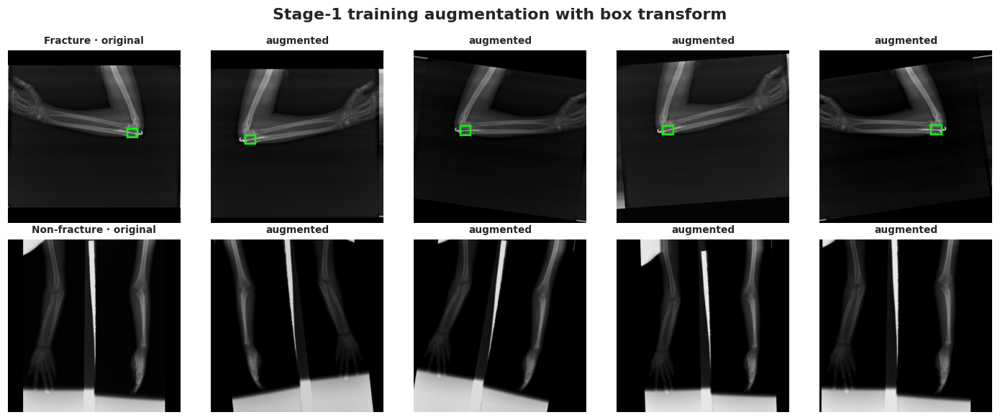

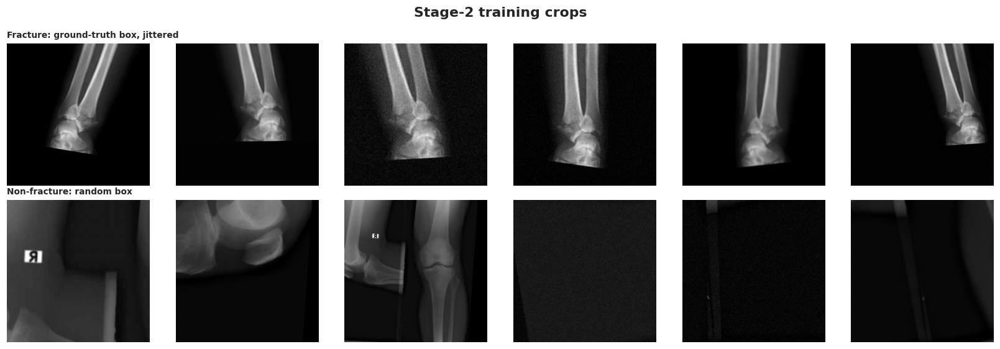

In [16]:
import io
from scipy.special import expit as sig

def _gauss_kernel(k):
    sigma = max(0.3 * ((k - 1) * 0.5 - 1) + 0.8, 0.5); ax = torch.arange(k).float() - (k - 1) / 2
    g = torch.exp(-ax ** 2 / (2 * sigma ** 2)); return g / g.sum()

def _u():
    return float(torch.rand(1)) * 2 - 1

def jit(x):
    m = x.mean()
    return ((x - m) * (1 + 0.10 * _u()) + m + 0.05 * _u()).clamp(0, 1)

def aug_full(x, box=None):
    ang, sc = math.radians(10) * _u(), 1 + 0.08 * _u()
    t = torch.tensor([0.10 * _u(), 0.10 * _u()], dtype=torch.float32)
    flip = -1.0 if torch.rand(1) < 0.5 else 1.0
    c, s = math.cos(ang) / sc, math.sin(ang) / sc
    A = torch.tensor([[c * flip, -s], [s * flip, c]], dtype=torch.float32)
    grid = F.affine_grid(torch.cat([A, t[:, None]], 1)[None], (1, 1) + tuple(x.shape[-2:]), align_corners=False)
    out = jit(F.grid_sample(x[None], grid, mode='bilinear', padding_mode='border', align_corners=False)[0])
    if box is None: return out, None
    cx, cy, w, h = [float(v) for v in box]
    pts = torch.tensor([[cx - w / 2, cy - h / 2], [cx + w / 2, cy - h / 2], [cx - w / 2, cy + h / 2], [cx + w / 2, cy + h / 2]], dtype=torch.float32) * 2 - 1
    q = (torch.linalg.inv(A) @ (pts - t).T).T
    lo, hi = ((q.amin(0) + 1) / 2).clamp(0, 1), ((q.amax(0) + 1) / 2).clamp(0, 1)
    return out, torch.stack([(lo[0] + hi[0]) / 2, (lo[1] + hi[1]) / 2, (hi[0] - lo[0]).clamp_min(1e-3), (hi[1] - lo[1]).clamp_min(1e-3)])

def extras(x):
    c = ROBUST_AUG
    if float(torch.rand(1)) < c['blur_p']:
        k = int(c['blur_kernels'][int(torch.randint(0, len(c['blur_kernels']), (1,)))]); pad = k // 2; k1 = _gauss_kernel(k)
        x = F.conv2d(F.pad(x[None], (pad, pad, 0, 0), mode='reflect'), k1.view(1, 1, 1, -1)); x = F.conv2d(F.pad(x, (0, 0, pad, pad), mode='reflect'), k1.view(1, 1, -1, 1))[0]
    if float(torch.rand(1)) < c['noise_p']:
        x = (x + float(torch.empty(1).uniform_(*c['noise_sigma'])) * torch.randn_like(x)).clamp(0, 1)
    if float(torch.rand(1)) < c['jpeg_p']:
        q = int(torch.randint(c['jpeg_quality'][0], c['jpeg_quality'][1] + 1, (1,))); buf = io.BytesIO()
        Image.fromarray((x[0] * 255).round().to(torch.uint8).numpy()).save(buf, format='JPEG', quality=q); buf.seek(0)
        x = torch.from_numpy(np.asarray(Image.open(buf).convert('L')).copy()).float().unsqueeze(0) / 255.
    return x

def crop_geom(box, scale=None, min_side=None):
    scale = CROP_SCALE if scale is None else scale; min_side = MIN_CROP if min_side is None else min_side
    cx, cy, w, h = box.unbind(-1)
    side = (torch.maximum(w, h) * scale).clamp(min_side, 1.0)
    return torch.maximum(torch.minimum(cx, 1 - side / 2), side / 2), torch.maximum(torch.minimum(cy, 1 - side / 2), side / 2), side

def sample_crops(src, cx, cy, side, rot=None, flip=None, out_size=None):
    out_size = out_size or CROP_SIZE; B = src.shape[0]
    rot = torch.zeros(B, device=src.device) if rot is None else rot; fl = torch.ones(B, device=src.device) if flip is None else flip
    c, s = torch.cos(rot) * side, torch.sin(rot) * side
    theta = torch.stack([torch.stack([c * fl, -s, 2 * cx - 1], 1), torch.stack([s * fl, c, 2 * cy - 1], 1)], 1)
    grid = F.affine_grid(theta, (B, 1, out_size, out_size), align_corners=False)
    return F.grid_sample(src, grid, mode='bilinear', padding_mode='border', align_corners=False)

class FullDS(Dataset):
    def __init__(self, df, boxes, train=False):
        self.p, self.y, self.b, self.train = df.path.values, df.label.values, boxes, train
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        x = IMGS[self.p[i]].float().unsqueeze(0) / 255.; y = float(self.y[i]); b = self.b[i]
        has = bool(np.isfinite(b).all() and y == 1); box = torch.from_numpy(b) if has else None
        if self.train:
            x, box = aug_full(x, box); x = extras(x)
        bt = box.float() if box is not None else torch.zeros(4)
        return ((x - MEAN) / STD).expand(3, -1, -1).contiguous(), torch.tensor(y), bt, torch.tensor(float(has))

class CropDS(Dataset):
    def __init__(self, df, base_boxes, pos_sides):
        self.p, self.y, self.b, self.sides = df.path.values, df.label.values, base_boxes, pos_sides
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        p, y = self.p[i], float(self.y[i]); src = IMGS_HI[p].float()[None, None] / 255.; b = self.b[i]
        if y == 0 and (not np.isfinite(b).all() or float(torch.rand(1)) < NEG_RANDOM_FRAC):
            side = float(self.sides[int(torch.randint(0, len(self.sides), (1,)))]); x0, y0, x1, y1 = CONTENT[p]
            lo_x, hi_x, lo_y, hi_y = max(x0, side / 2), min(x1, 1 - side / 2), max(y0, side / 2), min(y1, 1 - side / 2)
            cx = lo_x + (hi_x - lo_x) * float(torch.rand(1)) if hi_x > lo_x else (x0 + x1) / 2
            cy = lo_y + (hi_y - lo_y) * float(torch.rand(1)) if hi_y > lo_y else (y0 + y1) / 2
        else:
            cx, cy, side = [float(v) for v in crop_geom(torch.from_numpy(b).float())]
            side = min(1.0, max(0.8 * MIN_CROP, side * (1 + 1.25 * CROP_JITTER * _u())))
            cx += CROP_JITTER * side * _u(); cy += CROP_JITTER * side * _u()
        cx, cy = min(max(cx, side / 2), 1 - side / 2), min(max(cy, side / 2), 1 - side / 2)
        flip = -1.0 if torch.rand(1) < 0.5 else 1.0
        x = sample_crops(src, torch.tensor([cx]), torch.tensor([cy]), torch.tensor([side]), torch.tensor([math.radians(10) * _u()]), torch.tensor([flip]))[0]
        x = extras(jit(x))
        return ((x - MEAN) / STD).expand(3, -1, -1).contiguous(), torch.tensor(y)

def draw_box(ax, b, size, color, lw=1.6):
    if b is None or not np.isfinite(np.asarray(b, float)).all(): return
    cx, cy, w, h = [float(v) * size for v in b]
    ax.add_patch(plt.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, ec=color, lw=lw))

_r = np.random.default_rng(0); _df = parts['train']
_pos = np.flatnonzero((_df.label.values == 1) & np.isfinite(bx_tr).all(1)); _neg = np.flatnonzero(_df.label.values == 0)
_pick = [int(_r.choice(_pos)), int(_r.choice(_neg))]
torch.manual_seed(0); fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for row, i in zip(axes, _pick):
    base = IMGS[_df.path.iloc[i]].float().unsqueeze(0) / 255.; b0 = bx_tr[i] if np.isfinite(bx_tr[i]).all() else None
    row[0].imshow(base[0], cmap='gray', vmin=0, vmax=1); draw_box(row[0], b0, IMG_SIZE, 'lime'); row[0].set_title(('Fracture' if _df.label.iloc[i] else 'Non-fracture') + ' · original', fontsize=9)
    for ax in row[1:]:
        a_, nb = aug_full(base, torch.from_numpy(b0) if b0 is not None else None); ax.imshow(a_[0], cmap='gray', vmin=0, vmax=1)
        draw_box(ax, nb.numpy() if nb is not None else None, IMG_SIZE, 'lime'); ax.set_title('augmented', fontsize=9)
    for ax in row: ax.axis('off')
fig.suptitle('Stage-1 training augmentation with box transform', fontweight='bold'); finish(fig, 'S04_augmentation_examples', svg=False)

_sides = crop_geom(torch.from_numpy(bx_tr[_pos]))[2].numpy()
_gt_only = np.where((np.isfinite(bx_tr).all(1) & (_df.label.values == 1))[:, None], bx_tr, np.nan).astype(np.float32)
_ds = CropDS(_df, _gt_only, _sides); torch.manual_seed(1)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for row, i, nm in zip(axes, [_pos[0], _neg[0]], ['Fracture: ground-truth box, jittered', 'Non-fracture: random box']):
    for ax in row:
        x_, _ = _ds[int(i)]; ax.imshow(x_[0] * STD + MEAN, cmap='gray', vmin=0, vmax=1); ax.axis('off')
    row[0].set_title(nm, fontsize=9, loc='left')
fig.suptitle('Stage-2 training crops', fontweight='bold'); finish(fig, 'S05_stage2_crop_examples', svg=False)

In [17]:
class LocHead(nn.Module):
    def __init__(s, cin, mid=128):
        super().__init__()
        s.t = nn.Sequential(nn.Conv2d(cin, mid, 1, bias=False), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
                            nn.Conv2d(mid, mid, 3, padding=1, bias=False), nn.BatchNorm2d(mid), nn.ReLU(inplace=True))
        s.o = nn.Conv2d(mid, 5, 1); nn.init.zeros_(s.o.bias); nn.init.normal_(s.o.weight, std=0.01)
    def forward(s, f):
        z = s.o(s.t(f)).float(); B, _, h, w = z.shape
        a = F.softmax(z[:, 0].flatten(1), 1).view(B, 1, h, w)
        gx = ((torch.arange(w, device=z.device).float() + 0.5) / w).view(1, 1, 1, w)
        gy = ((torch.arange(h, device=z.device).float() + 0.5) / h).view(1, 1, h, 1)
        cx = (a * (gx + torch.tanh(z[:, 1:2]) / w)).sum((1, 2, 3)); cy = (a * (gy + torch.tanh(z[:, 2:3]) / h)).sum((1, 2, 3))
        bw = (a * torch.sigmoid(z[:, 3:4])).sum((1, 2, 3)); bh = (a * torch.sigmoid(z[:, 4:5])).sum((1, 2, 3))
        return torch.stack([cx, cy, bw, bh], 1)

def make_backbone(name, pretrained):
    if name == 'custom_cnn': return BoneNet(), False
    ctor = getattr(tvm, name); ok = bool(pretrained)
    try:
        m = ctor(weights='DEFAULT') if pretrained else ctor(weights=None)
    except Exception as e:
        print(f'WARNING [{name}]: pretrained weights unavailable ({type(e).__name__}); using random initialisation.'); m = ctor(weights=None); ok = False
    if name.startswith('resnet'): body = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
    elif name.startswith('densenet'): body = nn.Sequential(m.features, nn.ReLU(inplace=True))
    else: body = m.features
    return body, ok

class Net(nn.Module):
    def __init__(s, name, pretrained, with_loc=True):
        super().__init__()
        s.body, s.ok = make_backbone(name, pretrained); s.pool_max = name == 'custom_cnn'
        with torch.no_grad():
            was = s.body.training; s.body.eval(); ch = s.body(torch.zeros(1, 3, 64, 64)).shape[1]; s.body.train(was)
        s.drop = nn.Dropout(HEAD_DROPOUT); s.fc = nn.Linear(ch * (2 if s.pool_max else 1), 1)
        s.loc = LocHead(ch) if with_loc else None
    def pooled(s, f):
        a = F.adaptive_avg_pool2d(f, 1).flatten(1)
        return torch.cat([a, F.adaptive_max_pool2d(f, 1).flatten(1)], 1) if s.pool_max else a
    def forward(s, x):
        f = s.body(x)
        return s.fc(s.drop(s.pooled(f))).squeeze(1), (s.loc(f) if s.loc is not None else None)
    def cls(s, x): return s.fc(s.drop(s.pooled(s.body(x)))).squeeze(1)
    def embed(s, x): return s.pooled(s.body(x))

PRETRAINED_OK = {}
def build_model(name, pretrained=None, loc=True):
    pretrained = PRETRAINED if pretrained is None else pretrained
    net = Net(name, bool(pretrained) and name != 'custom_cnn', with_loc=loc)
    if name == 'custom_cnn': PRETRAINED_OK[name] = False
    elif pretrained: PRETRAINED_OK[name] = net.ok
    return net.to(DEVICE), net.ok

def cam_target(model, name):
    b = model.body
    if name == 'custom_cnn': return b.stage4
    if name.startswith('resnet'): return b[-1][-1]
    if name.startswith('densenet'): return b[0].denseblock4
    return b[-1]

In [18]:
FLIP_A, FLIP_B = torch.tensor([-1., 1., 1., 1.]), torch.tensor([1., 0., 0., 0.])

def to_input(u8):
    return ((u8.float() / 255. - MEAN) / STD).unsqueeze(1).expand(-1, 3, -1, -1).contiguous()

@torch.no_grad()
def net_out(net, x, tta=None):
    tta = TTA if tta is None else tta
    lo, bx = net(x); lo = lo.float()
    if tta:
        lo2, bx2 = net(torch.flip(x, dims=[3])); lo = (lo + lo2.float()) / 2
        if bx is not None: bx = (bx + bx2 * FLIP_A.to(bx2.device) + FLIP_B.to(bx2.device)) / 2
    return lo, bx

@torch.no_grad()
def stage1_forward(net, u8, bs=64):
    net.eval(); zs, bxs = [], []
    for i in range(0, len(u8), bs):
        lo, bx = net_out(net, to_input(u8[i:i + bs].to(DEVICE))); zs.append(lo.cpu()); bxs.append(bx.cpu())
    return torch.cat(zs), torch.cat(bxs)

@torch.no_grad()
def make_crops(hi_u8, boxes, bs=64):
    out = []
    for i in range(0, len(hi_u8), bs):
        src = hi_u8[i:i + bs].to(DEVICE).float().unsqueeze(1) / 255.; cx, cy, side = crop_geom(boxes[i:i + bs].to(DEVICE))
        out.append(sample_crops(src, cx, cy, side).half().cpu())
    return torch.cat(out)

@torch.no_grad()
def stage2_forward(net, crops, bs=64):
    net.eval(); out = []
    for i in range(0, len(crops), bs):
        x = ((crops[i:i + bs].float() - MEAN) / STD).to(DEVICE).expand(-1, 3, -1, -1).contiguous(); out.append(net_out(net, x)[0].cpu())
    return torch.cat(out)

class Pipe:
    def __init__(s, n1, n2, alpha=0.5, device=None):
        s.dev = device or DEVICE; s.n1, s.n2, s.alpha = n1.to(s.dev).eval(), n2.to(s.dev).eval(), alpha
    @torch.no_grad()
    def run(s, hi, bs=64):
        z1s, z2s, bxs = [], [], []
        for i in range(0, len(hi), bs):
            h = (hi[i:i + bs] if isinstance(hi, torch.Tensor) else torch.stack([IMGS_HI[p] for p in hi[i:i + bs]])).to(s.dev)
            z1, bx = net_out(s.n1, to_input(to_model_res(h)))
            cx, cy, side = crop_geom(bx); c = sample_crops(h.float().unsqueeze(1) / 255., cx, cy, side)
            z2, _ = net_out(s.n2, ((c - MEAN) / STD).expand(-1, 3, -1, -1).contiguous())
            z1s.append(z1.cpu()); z2s.append(z2.cpu()); bxs.append(bx.cpu())
        z1, z2, bx = torch.cat(z1s).numpy(), torch.cat(z2s).numpy(), torch.cat(bxs).numpy()
        return dict(z1=z1, z2=z2, box=bx, p=sig(s.alpha * z1 + (1 - s.alpha) * z2))

def load_pipe(r):
    n1 = build_model(r['model'], pretrained=False)[0]; n1.load_state_dict(torch.load(r['ckpt'], map_location=DEVICE))
    n2 = build_model(r['model'], pretrained=False, loc=False)[0]; n2.load_state_dict(torch.load(r['ckpt2'], map_location=DEVICE))
    return Pipe(n1, n2, r['alpha'])

def choose_alpha(y, z1, z2):
    best = None
    for a in np.linspace(0, 1, 11):
        key = (average_precision_score(y, sig(a * z1 + (1 - a) * z2)), -abs(a - 0.5))
        if best is None or key > best[0]: best = (key, float(a))
    return best[1]

def xyxy(b): return torch.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], 1)

def giou_iou(a, b):
    a, b = xyxy(a), xyxy(b)
    iw = (torch.minimum(a[:, 2], b[:, 2]) - torch.maximum(a[:, 0], b[:, 0])).clamp(min=0)
    ih = (torch.minimum(a[:, 3], b[:, 3]) - torch.maximum(a[:, 1], b[:, 1])).clamp(min=0)
    inter = iw * ih
    aa = (a[:, 2] - a[:, 0]).clamp(min=0) * (a[:, 3] - a[:, 1]).clamp(min=0); ab = (b[:, 2] - b[:, 0]).clamp(min=0) * (b[:, 3] - b[:, 1]).clamp(min=0)
    union = aa + ab - inter + 1e-7; iou = inter / union
    cw = torch.maximum(a[:, 2], b[:, 2]) - torch.minimum(a[:, 0], b[:, 0]); ch = torch.maximum(a[:, 3], b[:, 3]) - torch.minimum(a[:, 1], b[:, 1])
    carea = cw * ch + 1e-7
    return iou - (carea - union) / carea, iou

def box_loss(pred, gt):
    return F.l1_loss(pred, gt) + (1 - giou_iou(pred, gt)[0]).mean()

def box_iou_np(a, b):
    return giou_iou(torch.from_numpy(np.asarray(a, np.float32)), torch.from_numpy(np.asarray(b, np.float32)))[1].numpy()

## 5.2 · Metrics, thresholds and confidence intervals

In [19]:
safe_auc = lambda y, p: roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
safe_ap  = lambda y, p: average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan
bce_np   = lambda y, p: float(-np.mean(y * np.log(np.clip(p, 1e-7, 1)) + (1 - y) * np.log(np.clip(1 - p, 1e-7, 1))))

def choose_threshold(y, p, rule=None):
    rule = rule or THRESHOLD_RULE; fpr, tpr, thr = roc_curve(y, p)
    if rule == 'youden': return float(thr[np.argmax(tpr - fpr)])
    if rule == 'spec90':
        ok = np.where((1 - fpr) >= SPEC_TARGET)[0]; return float(thr[ok[np.argmax(tpr[ok])]]) if len(ok) else float(thr[0])
    if rule == 'sens90':
        ok = np.where(tpr >= SENS_TARGET)[0]; return float(thr[ok[0]]) if len(ok) else float(thr[-1])
    raise ValueError(rule)

def confusion(y, p, t):
    pred = p >= t; y1 = y == 1
    return int((pred & y1).sum()), int((pred & ~y1).sum()), int((~pred & y1).sum()), int((~pred & ~y1).sum())
def ece_score(y, p, bins=10):
    idx = np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1]); e = 0.0
    for b_ in range(bins):
        mk = idx == b_
        if mk.any(): e += mk.mean() * abs(y[mk].mean() - p[mk].mean())
    return float(e)
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = k / n; c = (ph + z * z / (2 * n)) / (1 + z * z / n); h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / (1 + z * z / n); return max(0.0, c - h), min(1.0, c + h)

def full_metrics(y, p, t):
    tp, fp, fn, tn = confusion(y, p, t); n = len(y)
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1); ppv, npv = tp / max(tp + fp, 1), tn / max(tn + fn, 1)
    f1 = 2 * ppv * sens / max(ppv + sens, 1e-12)
    den = math.sqrt(max((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn), 0)); mcc = (tp * tn - fp * fn) / den if den > 0 else 0.0
    po = (tp + tn) / n; pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n ** 2
    return dict(auroc=safe_auc(y, p), auprc=safe_ap(y, p), accuracy=po, balanced_acc=(sens + spec) / 2, sensitivity=sens, specificity=spec,
                ppv=ppv, npv=npv, f1=f1, mcc=mcc, kappa=(po - pe) / (1 - pe) if pe < 1 else 0.0, brier=brier_score_loss(y, p),
                loss=bce_np(y, p), ece=ece_score(y, p), tp=tp, fp=fp, fn=fn, tn=tn)

BOOT_METRICS = ['auroc', 'auprc', 'accuracy', 'sensitivity', 'specificity', 'ppv', 'f1', 'mcc']
def quick_metrics(y, p, t):
    pred = p >= t; y1 = y == 1; tp = (pred & y1).sum(); fp = (pred & ~y1).sum(); fn = (~pred & y1).sum(); tn = (~pred & ~y1).sum()
    sens, spec, ppv = tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp / max(tp + fp, 1)
    den = math.sqrt(max(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)), 0))
    return dict(auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p), accuracy=(tp + tn) / len(y), sensitivity=sens, specificity=spec,
                ppv=ppv, f1=2 * ppv * sens / max(ppv + sens, 1e-12), mcc=(tp * tn - fp * fn) / den if den > 0 else 0.0)

def cluster_bootstrap(y, P, groups, T, n_boot, seed=0):
    rng = np.random.default_rng(seed); ug = pd.unique(groups); gi = {g: np.where(groups == g)[0] for g in ug}
    out = {k: {m: [] for m in BOOT_METRICS} for k in P}
    for _ in tqdm(range(n_boot), desc='Cluster bootstrap', leave=False):
        ii = np.concatenate([gi[ug[s]] for s in rng.integers(0, len(ug), len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        for k, p in P.items():
            for m, v in quick_metrics(y[ii], p[ii], T[k]).items(): out[k][m].append(v)
    return {k: {m: np.array(v) for m, v in d.items()} for k, d in out.items()}
ci95 = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))
def errbars(v, lo, hi):
    v, lo, hi = (np.nan_to_num(np.asarray(a, float)) for a in (v, lo, hi)); return [np.clip(v - lo, 0, None), np.clip(hi - v, 0, None)]

## 5.3 · Training loop, history plot and per-model report

In [20]:
MODEL_RUNS, RESULTS = {}, {}
(OUT / 'runs').mkdir(exist_ok=True); (OUT / 'tables').mkdir(exist_ok=True)
nice = lambda k: DISPLAY.get(k, k)
MODEL_PAL = {a: MODEL_COLORS[i % len(MODEL_COLORS)] for i, a in enumerate(ARCHS)}; MODEL_PAL['ensemble_all'] = '#333333'

def run_paths(name, seed): return OUT / 'runs' / f'{name}_s{seed}.npz', OUT / 'runs' / f'{name}_s{seed}.json'

class EMA:
    def __init__(s, model, decay):
        s.m = copy.deepcopy(model).eval(); s.decay, s.n = decay, 0
        for p in s.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(s, model):
        s.n += 1; d = min(s.decay, (1 + s.n) / (10 + s.n)); msd = model.state_dict()
        for k, v in s.m.state_dict().items():
            if v.dtype.is_floating_point: v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else: v.copy_(msd[k])

def make_optimizer(net, name):
    lr, mult = LR_BY_MODEL.get(name, LR), HEAD_MULT_BY_MODEL.get(name, HEAD_LR_MULT)
    groups = {(h, d): [] for h in (False, True) for d in (False, True)}
    for n_, p in net.named_parameters(): groups[(n_.startswith(('fc.', 'loc.')), p.ndim > 1)].append(p)
    return torch.optim.AdamW([dict(params=ps, lr=lr * (mult if h else 1.0), weight_decay=WD if d else 0.0) for (h, d), ps in groups.items() if ps])

def cls_metrics(p):
    pred = p >= 0.5
    return dict(val_loss=bce_np(yv, p), val_auroc=safe_auc(yv, p), val_auprc=safe_ap(yv, p), val_acc=float((pred == yv).mean()),
                val_sens_at_0p5=float((pred & (yv == 1)).sum() / max((yv == 1).sum(), 1)), val_spec_at_0p5=float((~pred & (yv == 0)).sum() / max((yv == 0).sum(), 1)))

def val_iou(bx):
    m = np.isfinite(bx_va).all(1) & (yv == 1)
    return float(box_iou_np(bx[m], bx_va[m]).mean()) if m.any() else float('nan')

def pos_weight(): return torch.tensor(n_neg / n_pos, device=DEVICE) if LOSS == 'wbce' else None

def stage1_step(net, batch):
    x, y, b, m = batch; logit, box = net(x); logit = logit.float()
    lc = F.binary_cross_entropy_with_logits(logit, y * (1 - LABEL_SMOOTH) + 0.5 * LABEL_SMOOTH, pos_weight=pos_weight())
    sel = m > 0; nb = int(sel.sum())
    lb = box_loss(box[sel], b[sel]) if nb else logit.sum() * 0.0
    return lc + LOC_WEIGHT * lb, dict(n=len(y), bce=float(F.binary_cross_entropy_with_logits(logit.detach(), y, reduction='sum')),
                                      correct=float(((logit.detach() > 0).float() == y).sum()), nb=nb, box=float(lb.detach()) * nb)

def stage2_step(net, batch):
    x, y = batch; logit = net(x)[0].float()
    lc = F.binary_cross_entropy_with_logits(logit, y * (1 - LABEL_SMOOTH) + 0.5 * LABEL_SMOOTH, pos_weight=pos_weight())
    return lc, dict(n=len(y), bce=float(F.binary_cross_entropy_with_logits(logit.detach(), y, reduction='sum')),
                    correct=float(((logit.detach() > 0).float() == y).sum()), nb=0, box=0.0)

def fit(stage, name, seed, net, loader, loss_step, eval_epoch):
    opt = make_optimizer(net, name); steps, warm = EPOCHS * len(loader), max(1, int(WARMUP_EPOCHS * len(loader)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: (i + 1) / warm if i < warm else max(0.01, 0.5 * (1 + math.cos(math.pi * (i - warm) / max(1, steps - warm)))))
    use_amp = DEVICE.type == 'cuda'; scaler = torch.amp.GradScaler('cuda', enabled=use_amp); ema = EMA(net, EMA_DECAY)
    best, best_state, hist, bad = -1.0, None, [], 0
    if use_amp: torch.cuda.reset_peak_memory_stats()
    for ep in range(1, EPOCHS + 1):
        net.train(); t0 = time.perf_counter(); acc = defaultdict(float); lr_now = opt.param_groups[0]['lr']
        for batch in loader:
            batch = [t.to(DEVICE) for t in batch]; opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp): loss, st = loss_step(net, batch)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); ema.update(net)
            for k, v in st.items(): acc[k] += v
        ev = eval_epoch(ema.m); ap = ev.get('select', ev['val_auprc']); is_best = ap > best
        row = dict(model=name, seed=seed, stage=stage, epoch=ep, lr=lr_now, train_loss=acc['bce'] / acc['n'], train_acc=acc['correct'] / acc['n'],
                   train_box=acc['box'] / max(acc['nb'], 1), epoch_time_s=time.perf_counter() - t0, **ev)
        hist.append(row); mem = f' | mem {torch.cuda.max_memory_allocated() / 2**30:.1f} GB' if use_amp else ''
        iou = f' IoU {ev["val_iou"]:.3f}' if 'val_iou' in ev else ''
        print(f'[stage {stage}] epoch {ep:02d}/{EPOCHS} | lr {lr_now:.1e} | train loss {row["train_loss"]:.4f} acc {row["train_acc"]:.3f} | '
              f'val loss {ev["val_loss"]:.4f} AUROC {ev["val_auroc"]:.4f} AUPRC {ap:.4f}{iou} | {row["epoch_time_s"]:.1f}s{mem}{"  <- best" if is_best else ""}')
        if is_best: best, best_state, bad = ap, {k: v.detach().clone() for k, v in ema.m.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= PATIENCE: print(f'early stopping at epoch {ep} (no validation-AUPRC gain for {PATIENCE} epochs)'); break
    return best_state, hist, (torch.cuda.max_memory_allocated() / 2**30 if use_amp else None)

def train_run(name, seed):
    t_start = time.perf_counter(); seed_all(seed)
    tr, va, te = parts['train'], parts['validation'], parts['test']; X_va = torch.stack([IMGS[p] for p in va.path])
    net1, ok = build_model(name); p1 = sum(p.numel() for p in net1.parameters())
    print(f'\n{"=" * 100}\n  {nice(name)} | seed {seed} | stage 1 (full image + localization): {p1 / 1e6:.2f}M parameters | ImageNet weights: {ok}\n{"=" * 100}')
    loader1 = DataLoader(FullDS(tr, bx_tr, train=True), batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS,
                         generator=torch.Generator().manual_seed(seed), drop_last=len(tr) >= 2 * BATCH)
    def ev1(m):
        z, bx = stage1_forward(m, X_va); m_ = cls_metrics(torch.sigmoid(z).numpy()); iou_ = val_iou(bx.numpy())
        return {**m_, 'val_iou': iou_, 'select': m_['val_auprc'] + LOC_SELECT_WEIGHT * iou_ if np.isfinite(iou_) else m_['val_auprc']}
    state1, hist1, peak1 = fit(1, name, seed, net1, loader1, stage1_step, ev1)
    net1.load_state_dict(state1); ckpt1 = CKPT_DIR / f'{name}_s{seed}.pt'; torch.save(state1, ckpt1)
    X_tr = torch.stack([IMGS[p] for p in tr.path]); bx_tr_pred = stage1_forward(net1, X_tr)[1]; del X_tr
    bx_va_pred = stage1_forward(net1, X_va)[1]
    gt_ok = np.isfinite(bx_tr).all(1) & (ytr == 1)
    base = np.where(gt_ok[:, None], bx_tr, bx_tr_pred.numpy()).astype(np.float32)
    pos_sides = crop_geom(torch.from_numpy(bx_tr[gt_ok]))[2].numpy() if gt_ok.any() else np.array([0.5], np.float32)
    val_crops = make_crops(torch.stack([IMGS_HI[p] for p in va.path]), bx_va_pred)
    seed_all(seed); net2, ok2 = build_model(name, loc=False); p2 = sum(p.numel() for p in net2.parameters())
    print(f'\n{"-" * 100}\n  {nice(name)} | seed {seed} | stage 2 (zoomed crop): {p2 / 1e6:.2f}M parameters\n{"-" * 100}')
    loader2 = DataLoader(CropDS(tr, base, pos_sides), batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS,
                         generator=torch.Generator().manual_seed(seed), drop_last=len(tr) >= 2 * BATCH)
    def ev2(m): return cls_metrics(torch.sigmoid(stage2_forward(m, val_crops)).numpy())
    state2, hist2, peak2 = fit(2, name, seed, net2, loader2, stage2_step, ev2)
    net2.load_state_dict(state2); ckpt2 = CKPT_DIR / f'{name}_s{seed}_stage2.pt'; torch.save(state2, ckpt2)
    pipe = Pipe(net1, net2, 0.5); R = {}
    for k, d in [('train', tr), ('val', va), ('test', te)] + ([('ext', ext)] if len(ext) else []): R[k] = pipe.run(list(d.path))
    alpha = choose_alpha(yv, R['val']['z1'], R['val']['z2']); P, PF, PC = {}, {}, {}
    for k in ['train', 'val', 'test', 'ext']:
        if k in R: PF[k], PC[k], P[k] = sig(R[k]['z1']), sig(R[k]['z2']), sig(alpha * R[k]['z1'] + (1 - alpha) * R[k]['z2'])
        else: PF[k] = PC[k] = P[k] = np.array([])
    best_ep, best_ep2 = int(np.argmax([h.get('select', h['val_auprc']) for h in hist1]) + 1), int(np.argmax([h.get('select', h['val_auprc']) for h in hist2]) + 1)
    thr_ = choose_threshold(yv, P['val']); train_time = time.perf_counter() - t_start
    meta = dict(model=name, seed=seed, best_epoch=best_ep, best_epoch2=best_ep2, epochs_run=len(hist1), epochs_run2=len(hist2), train_time_s=train_time, thr=thr_,
                alpha=alpha, ckpt=str(ckpt1), ckpt2=str(ckpt2), params=p1 + p2, params_stage1=p1, pretrained_ok=ok,
                peak_gpu_gb=max(peak1, peak2) if peak1 is not None else None, hist=hist1, hist2=hist2)
    arrays = {**{f'p_{k}': v for k, v in P.items()}, **{f'pf_{k}': v for k, v in PF.items()}, **{f'pc_{k}': v for k, v in PC.items()}, 'box_val': R['val']['box'], 'box_test': R['test']['box']}
    npz, js = run_paths(name, seed); np.savez(npz, **arrays); js.write_text(json.dumps(meta, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
    print(f'-> stage 1 best epoch {best_ep} | stage 2 best epoch {best_ep2} | alpha {alpha:.1f} | val AUPRC full {safe_ap(yv, PF["val"]):.4f} crop {safe_ap(yv, PC["val"]):.4f} '
          f'fused {safe_ap(yv, P["val"]):.4f} | threshold {thr_:.3f} | train time {train_time / 60:.1f} min')
    del net1, net2, pipe
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return {**meta, **arrays}

def load_run(name, seed):
    npz, js = run_paths(name, seed); z = np.load(npz); meta = json.loads(js.read_text())
    PRETRAINED_OK[name] = meta.get('pretrained_ok', False)
    print(f'(reused finished run) {nice(name)} seed {seed}: best epochs {meta["best_epoch"]}/{meta["best_epoch2"]}, alpha {meta["alpha"]:.1f}')
    return {**meta, **{k: z[k] for k in z.files}}

def run_model_training(name):
    runs = []
    for seed in SEEDS:
        npz, js = run_paths(name, seed)
        runs.append(load_run(name, seed) if (RESUME and npz.exists() and js.exists()) else train_run(name, seed))
    MODEL_RUNS[name] = runs
    return runs

def plot_history(name):
    fig, axes = plt.subplots(2, 3, figsize=(17, 8.4))
    for r_, (key, ttl) in enumerate([('hist', 'Stage 1 (full image)'), ('hist2', 'Stage 2 (zoomed crop)')]):
        h = pd.concat([pd.DataFrame(r[key]) for r in MODEL_RUNS[name]]); ax = axes[r_]
        for seed, g in h.groupby('seed'):
            ax[0].plot(g.epoch, g.train_loss, color='#2E86AB', alpha=.75); ax[0].plot(g.epoch, g.val_loss, color='#F18F01', ls='--', alpha=.85)
            ax[1].plot(g.epoch, g.val_auroc, marker='o', ms=3, label=f'seed {seed}'); ax[2].plot(g.epoch, g.val_auprc, marker='o', ms=3, label=f'seed {seed}')
            sc = 'select' if 'select' in g else 'val_auprc'; k_ = g[sc].idxmax(); ax[2].plot(g.loc[k_, 'epoch'], g.loc[k_, 'val_auprc'], '*', color='k', ms=11)
        ax[0].set(title=f'{ttl}: loss, training (blue) · validation (orange, dashed)', xlabel='epoch', ylabel='BCE'); ax[1].set(title='Validation AUROC', xlabel='epoch')
        ax[2].set(title='Validation AUPRC (★ = selected epoch)', xlabel='epoch'); ax[2].legend(frameon=False, fontsize=8)
    fig.suptitle(f'Training history · {nice(name)}', fontweight='bold'); finish(fig, f'M_{name}_training_history')

SPLIT_KEYS = [('Train', 'train', ytr), ('Validation', 'val', yv), ('Test', 'test', yt)]
SHOW = [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('accuracy', 'Acc'), ('balanced_acc', 'BalAcc'), ('sensitivity', 'Sens'), ('specificity', 'Spec'),
        ('ppv', 'PPV'), ('npv', 'NPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('brier', 'Brier'), ('loss', 'BCE loss')]

def ensemble_of(name, key): return np.mean([r[f'p_{key}'] for r in MODEL_RUNS[name]], axis=0)

def report_model(name):
    runs = MODEL_RUNS[name]; rows, seed_rows = [], []
    ens_t = choose_threshold(yv, ensemble_of(name, 'val'))
    for label, key, y in SPLIT_KEYS:
        per = pd.DataFrame([full_metrics(y, r[f'p_{key}'], r['thr']) for r in runs])
        for r, (_, m) in zip(runs, per.iterrows()): seed_rows.append(dict(split=label, seed=r['seed'], threshold=r['thr'], **{k: m[k] for k, _ in SHOW}, tp=int(m.tp), fp=int(m.fp), fn=int(m.fn), tn=int(m.tn)))
        base = dict(split=label, n=len(y), fractured=int(y.sum()))
        if len(runs) > 1: rows.append({**base, 'row': f'mean ± SD over {len(runs)} seeds', **{lab: f'{per[k].mean():.3f} ± {per[k].std():.3f}' for k, lab in SHOW}})
        m = full_metrics(y, ensemble_of(name, key), ens_t); rows.append({**base, 'row': 'seed-ensemble' if len(runs) > 1 else f'seed {runs[0]["seed"]}', **{lab: f'{m[k]:.3f}' for k, lab in SHOW}})
    tab = pd.DataFrame(rows).set_index(['split', 'row']); seed_tab = pd.DataFrame(seed_rows)
    print('=' * 112); print(f'  {nice(name).upper()} · TRAIN / VALIDATION / TEST RESULTS · threshold from validation ({THRESHOLD_RULE}) = {ens_t:.3f} (ensemble)'); print('=' * 112)
    display(tab); print('Per-seed results (each seed uses its own validation threshold):'); display(seed_tab.round(3))
    tab.to_csv(OUT / 'tables' / f'model_{name}_train_val_test.csv'); seed_tab.round(4).to_csv(OUT / 'tables' / f'model_{name}_per_seed.csv', index=False)
    gap = seed_tab[seed_tab.split == 'Train'].auroc.mean() - seed_tab[seed_tab.split == 'Validation'].auroc.mean()
    print(f'Train − validation AUROC gap: {gap:+.3f} (large positive = overfitting) | best epoch(s): {[r["best_epoch"] for r in runs]} | train time per run: {np.mean([r["train_time_s"] for r in runs]) / 60:.1f} min')
    fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
    for ax, (label, key, y) in zip(axes[:3], SPLIT_KEYS):
        tp, fp, fn, tn = confusion(y, ensemble_of(name, key), ens_t); cm = np.array([[tn, fp], [fn, tp]]); rp = cm / cm.sum(1, keepdims=True)
        sns.heatmap(rp, annot=np.array([[f'{cm[i, j]}\n({100 * rp[i, j]:.1f}%)' for j in range(2)] for i in range(2)]), fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False,
                    xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=ax); ax.set(title=f'{label} · confusion', xlabel='Predicted fracture', ylabel='Actual fracture')
    for label, key, y in SPLIT_KEYS:
        p = ensemble_of(name, key); fpr, tpr, _ = roc_curve(y, p); pr, rc, _ = precision_recall_curve(y, p)
        axes[3].plot(fpr, tpr, label=f'{label} (AUC {roc_auc_score(y, p):.3f})'); axes[4].plot(rc, pr, label=f'{label} (AP {average_precision_score(y, p):.3f})')
    axes[3].plot([0, 1], [0, 1], 'k--', lw=1); axes[3].set(title='ROC', xlabel='False positive rate', ylabel='Sensitivity'); axes[3].legend(frameon=False, fontsize=8)
    axes[4].set(title='Precision–recall', xlabel='Recall', ylabel='Precision', ylim=(0, 1.02)); axes[4].legend(frameon=False, fontsize=8)
    fig.suptitle(f'{nice(name)}: results on train, validation and test (seed-ensemble)', fontweight='bold'); finish(fig, f'M_{name}_train_val_test_results')
    RESULTS[name] = dict(runs=runs, thr=ens_t, table=tab, seed_table=seed_tab, params=runs[0]['params'])
    return tab

## 5.4 · Custom CNN: BoneNet

BoneNet: 2.93M parameters per network (input 320×320, logit (1,), box (1, 4))


,block,output_shape,params,share_%
0,stem,32×160×160,928,0.0
1,stage1,32×160×160,18852,0.6
2,stage2,64×80×80,58824,2.0
3,stage3,128×40×40,534048,18.2
4,stage4,256×20×20,2133056,72.9
5,"classification head (avg+max pool, dropout, li...",1 logit,513,0.0
6,"localization head (conv, soft-argmax box)",4 box values,181381,6.2


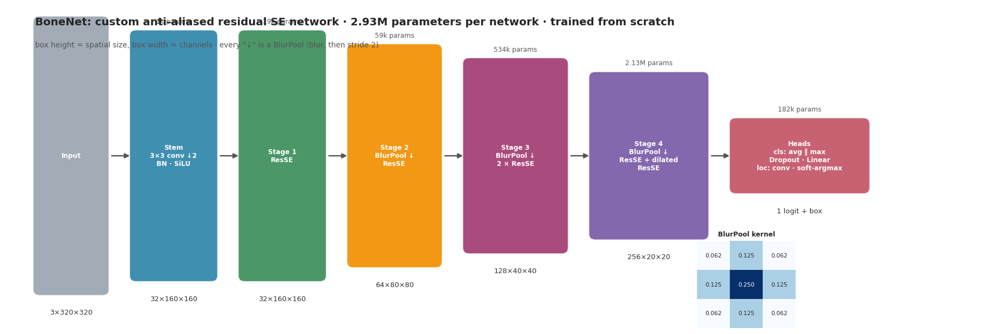

In [21]:
class BlurPool(nn.Module):
    def __init__(s, ch):
        super().__init__(); k = torch.tensor([1., 2., 1.]); k = k[:, None] * k[None, :]; k = k / k.sum()
        s.register_buffer('k', k[None, None].repeat(ch, 1, 1, 1)); s.ch = ch
    def forward(s, x): return F.conv2d(F.pad(x, (1, 1, 1, 1), mode='reflect'), s.k, stride=2, groups=s.ch)

class SE(nn.Module):
    def __init__(s, ch, r=8):
        super().__init__(); mid = max(ch // r, 4)
        s.f = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(ch, mid, 1), nn.SiLU(), nn.Conv2d(mid, ch, 1), nn.Sigmoid())
    def forward(s, x): return x * s.f(x)

class ResSE(nn.Module):
    def __init__(s, cin, cout, dilation=1):
        super().__init__()
        s.c1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.SiLU())
        s.c2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=dilation, dilation=dilation, bias=False), nn.BatchNorm2d(cout))
        s.se = SE(cout); s.act = nn.SiLU()
        s.skip = nn.Identity() if cin == cout else nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout))
    def forward(s, x): return s.act(s.se(s.c2(s.c1(x))) + s.skip(x))

class BoneNet(nn.Module):
    def __init__(s, widths=(32, 64, 128, 256)):
        super().__init__(); w = widths; s.out_ch = w[3]
        s.stem = nn.Sequential(nn.Conv2d(3, w[0], 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(w[0]), nn.SiLU())
        s.stage1 = nn.Sequential(ResSE(w[0], w[0]))
        s.stage2 = nn.Sequential(BlurPool(w[0]), ResSE(w[0], w[1]))
        s.stage3 = nn.Sequential(BlurPool(w[1]), ResSE(w[1], w[2]), ResSE(w[2], w[2]))
        s.stage4 = nn.Sequential(BlurPool(w[2]), ResSE(w[2], w[3]), ResSE(w[3], w[3], dilation=2))
        for m in s.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    def forward(s, x): return s.stage4(s.stage3(s.stage2(s.stage1(s.stem(x)))))

_net = Net('custom_cnn', False).eval(); _bn = _net.body; _shapes = {}
_hooks = [getattr(_bn, n).register_forward_hook(lambda m, i, o, n=n: _shapes.__setitem__(n, tuple(o.shape[1:]))) for n in ['stem', 'stage1', 'stage2', 'stage3', 'stage4']]
with torch.no_grad(): _out = _net(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))
for h_ in _hooks: h_.remove()
pc = lambda m: sum(p.numel() for p in m.parameters())
arch = pd.DataFrame([dict(block=n, output_shape='×'.join(map(str, _shapes[n])), params=pc(getattr(_bn, n))) for n in ['stem', 'stage1', 'stage2', 'stage3', 'stage4']] +
                    [dict(block='classification head (avg+max pool, dropout, linear)', output_shape='1 logit', params=pc(_net.fc)),
                     dict(block='localization head (conv, soft-argmax box)', output_shape='4 box values', params=pc(_net.loc))])
arch['share_%'] = (100 * arch.params / arch.params.sum()).round(1); arch.to_csv(OUT / 'tables' / 'bonenet_architecture.csv', index=False)
print(f'BoneNet: {pc(_net) / 1e6:.2f}M parameters per network (input {IMG_SIZE}×{IMG_SIZE}, logit {tuple(_out[0].shape)}, box {tuple(_out[1].shape)})'); display(arch)

fig, ax = plt.subplots(figsize=(17, 5.8)); ax.set_xlim(0, 17); ax.set_ylim(0, 5.8); ax.axis('off')
blocks = [('Input', f'3×{IMG_SIZE}×{IMG_SIZE}', None, '#9AA5B1', 3, IMG_SIZE), ('Stem\n3×3 conv ↓2\nBN · SiLU', '×'.join(map(str, _shapes['stem'])), pc(_bn.stem), '#2E86AB', _shapes['stem'][0], _shapes['stem'][1]),
          ('Stage 1\nResSE', '×'.join(map(str, _shapes['stage1'])), pc(_bn.stage1), '#3B8E5A', _shapes['stage1'][0], _shapes['stage1'][1]),
          ('Stage 2\nBlurPool ↓\nResSE', '×'.join(map(str, _shapes['stage2'])), pc(_bn.stage2), '#F18F01', _shapes['stage2'][0], _shapes['stage2'][1]),
          ('Stage 3\nBlurPool ↓\n2 × ResSE', '×'.join(map(str, _shapes['stage3'])), pc(_bn.stage3), '#A23B72', _shapes['stage3'][0], _shapes['stage3'][1]),
          ('Stage 4\nBlurPool ↓\nResSE + dilated\nResSE', '×'.join(map(str, _shapes['stage4'])), pc(_bn.stage4), '#7A5BA6', _shapes['stage4'][0], _shapes['stage4'][1]),
          ('Heads\ncls: avg ‖ max\nDropout · Linear\nloc: conv · soft-argmax', '1 logit + box', pc(_net.fc) + pc(_net.loc), '#C45566', 512, 1)]
x = 0.5
for i, (title, shp, par, col, ch, sp) in enumerate(blocks):
    wd = 1.15 + 0.85 * math.sqrt(ch / 256); ht = 0.8 + 0.5 * math.log2(max(sp, 2)); y0 = 3.1 - ht / 2
    ax.add_patch(plt.matplotlib.patches.FancyBboxPatch((x, y0), wd, ht, boxstyle='round,pad=0.04,rounding_size=0.12', fc=col, ec='white', lw=2, alpha=.92))
    ax.text(x + wd / 2, 3.1, title, ha='center', va='center', color='white', fontsize=8, fontweight='bold')
    ax.text(x + wd / 2, y0 - 0.28, shp, ha='center', va='top', fontsize=8.5, color='#333')
    if par is not None: ax.text(x + wd / 2, y0 + ht + 0.15, f'{par / 1e3:.0f}k params' if par < 1e6 else f'{par / 1e6:.2f}M params', ha='center', fontsize=8, color='#555')
    if i < len(blocks) - 1: ax.annotate('', xy=(x + wd + 0.42, 3.1), xytext=(x + wd + 0.05, 3.1), arrowprops=dict(arrowstyle='-|>', color='#555', lw=1.6))
    x += wd + 0.42
ax.text(0.5, 5.45, f'BoneNet: custom anti-aliased residual SE network · {pc(_net) / 1e6:.2f}M parameters per network · trained from scratch', fontsize=13, fontweight='bold')
ax.text(0.5, 5.05, 'box height = spatial size, box width = channels · every "↓" is a BlurPool (blur, then stride 2)', fontsize=9, color='#555')
kin = ax.inset_axes([0.70, 0.0, 0.10, 0.27]); k = np.outer([1, 2, 1], [1, 2, 1]) / 16; sns.heatmap(k, annot=True, fmt='.3f', cmap='Blues', cbar=False, xticklabels=False, yticklabels=False, ax=kin, annot_kws={'fontsize': 7}); kin.set_title('BlurPool kernel', fontsize=8)
finish(fig, 'G00_bonenet_architecture')
del _net, _bn

# Section 6: CNN Learning Models

## Model 1: ResNet-18

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 248MB/s]



  ResNet-18 | seed 42 | stage 1 (full image + localization): 11.39M parameters | ImageNet weights: True
[stage 1] epoch 01/20 | lr 1.1e-06 | train loss 0.4617 acc 0.788 | val loss 0.3634 AUROC 0.8260 AUPRC 0.6795 IoU 0.113 | 17.7s | mem 1.2 GB  <- best
[stage 1] epoch 02/20 | lr 1.0e-04 | train loss 0.3445 acc 0.867 | val loss 0.3489 AUROC 0.8529 AUPRC 0.7820 IoU 0.166 | 12.6s | mem 1.3 GB  <- best
[stage 1] epoch 03/20 | lr 9.9e-05 | train loss 0.3185 acc 0.864 | val loss 0.3143 AUROC 0.8740 AUPRC 0.8442 IoU 0.179 | 12.5s | mem 1.3 GB  <- best
[stage 1] epoch 04/20 | lr 9.7e-05 | train loss 0.2982 acc 0.888 | val loss 0.2897 AUROC 0.8914 AUPRC 0.9056 IoU 0.195 | 12.7s | mem 1.3 GB  <- best
[stage 1] epoch 05/20 | lr 9.4e-05 | train loss 0.2950 acc 0.880 | val loss 0.2746 AUROC 0.9073 AUPRC 0.9678 IoU 0.206 | 12.7s | mem 1.3 GB  <- best
[stage 1] epoch 06/20 | lr 8.9e-05 | train loss 0.2662 acc 0.898 | val loss 0.2616 AUROC 0.9036 AUPRC 1.0053 IoU 0.225 | 12.7s | mem 1.3 GB  <- best
[

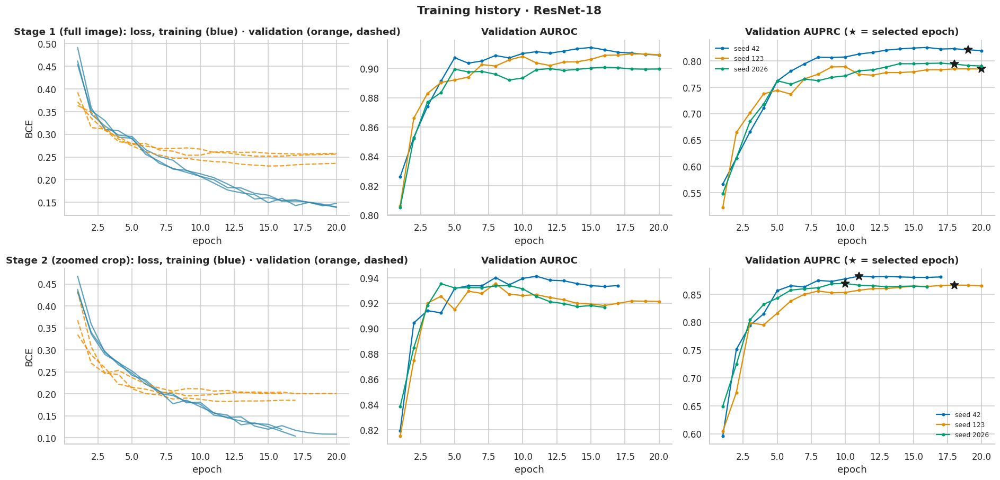

In [22]:
runs = run_model_training('resnet18')
plot_history('resnet18')

### 6.1b · ResNet-18: train / validation / test results

  RESNET-18 · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.328 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.989 ± 0.006   
           seed-ensemble           2821        507          0.992   
Validation mean ± SD over 3 seeds   404         72  0.934 ± 0.009   
           seed-ensemble            404         72          0.940   
Test       mean ± SD over 3 seeds   771        122  0.914 ± 0.009   
           seed-ensemble            771        122          0.928   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.972 ± 0.014  0.957 ± 0.023   
           seed-ensemble                   0.979          0.975   
Validation mean ± SD over 3 seeds  0.877 ± 0.010  0.922 ± 0.030   
           seed-ensemble                   0.882          0.948   
Test       mean ± SD over 3 seeds  0.788 ± 0.007  0.896 ± 0.028   
           seed-ensemble                   0.808          0.922   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.945 ± 0.007  0.926 ± 0.034   
           seed-ensemble                   0.951          0.913   
Validation mean ± SD over 3 seeds  0.889 ± 0.007  0.838 ± 0.032   
           seed-ensemble                   0.898          0.819   
Test       mean ± SD over 3 seeds  0.814 ± 0.027  0.694 ± 0.096   
           seed-ensemble                   0.817          0.664   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.964 ± 0.034  0.863 ± 0.118   
           seed-ensemble                   0.988          0.945   
Validation mean ± SD over 3 seeds  0.940 ± 0.043  0.767 ± 0.119   
           seed-ensemble                   0.976          0.881   
Test       mean ± SD over 3 seeds  0.934 ± 0.049  0.693 ± 0.136   
           seed-ensemble                   0.971          0.810   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.984 ± 0.007  0.889 ± 0.050   
           seed-ensemble                   0.981          0.929   
Validation mean ± SD over 3 seeds  0.964 ± 0.006  0.796 ± 0.054   
           seed-ensemble                   0.961          0.849   
Test       mean ± SD over 3 seeds  0.943 ± 0.014  0.681 ± 0.035   
           seed-ensemble                   0.939          0.730   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.867 ± 0.060  0.023 ± 0.006  0.095 ± 0.018  
           seed-ensemble                   0.914          0.022          0.091  
Validation mean ± SD over 3 seeds  0.753 ± 0.065  0.050 ± 0.002  0.191 ± 0.008  
           seed-ensemble                   0.818          0.048          0.183  
Test       mean ± SD over 3 seeds  0.628 ± 0.045  0.065 ± 0.002  0.231 ± 0.007  
           seed-ensemble                   0.689          0.063          0.219

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.101,0.989,0.972,0.935,0.947,0.964,0.929,0.748,0.992,0.842,0.813,0.024,0.098,489,165,18,2149
1,Train,123,0.441,0.995,0.986,0.980,0.951,0.905,0.997,0.983,0.980,0.943,0.932,0.017,0.076,459,8,48,2306
2,Train,2026,0.209,0.983,0.958,0.956,0.937,0.907,0.967,0.858,0.979,0.882,0.856,0.028,0.112,460,76,47,2238
3,Validation,42,0.101,0.944,0.888,0.889,0.883,0.875,0.892,0.636,0.970,0.737,0.682,0.048,0.181,63,36,9,296
4,Validation,123,0.441,0.927,0.870,0.946,0.896,0.819,0.973,0.868,0.961,0.843,0.810,0.050,0.195,59,9,13,323
5,Validation,2026,0.209,0.931,0.871,0.931,0.887,0.819,0.955,0.797,0.961,0.808,0.766,0.052,0.197,59,15,13,317
6,Test,42,0.101,0.919,0.796,0.864,0.829,0.779,0.880,0.549,0.955,0.644,0.576,0.063,0.224,95,78,27,571
7,Test,123,0.441,0.919,0.782,0.914,0.783,0.590,0.975,0.818,0.927,0.686,0.649,0.067,0.237,72,16,50,633
8,Test,2026,0.209,0.903,0.787,0.909,0.830,0.713,0.946,0.713,0.946,0.713,0.659,0.064,0.231,87,35,35,614


Train − validation AUROC gap: +0.055 (large positive = overfitting) | best epoch(s): [19, 20, 18] | train time per run: 8.9 min


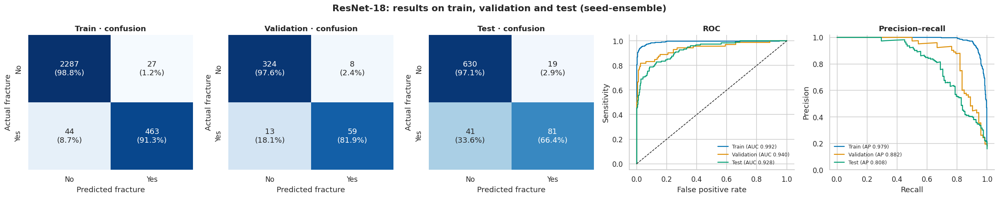

In [23]:
_ = report_model('resnet18')

## Model 2: DenseNet-121

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 247MB/s]



  DenseNet-121 | seed 42 | stage 1 (full image + localization): 7.23M parameters | ImageNet weights: True
[stage 1] epoch 01/20 | lr 1.1e-06 | train loss 0.4630 acc 0.802 | val loss 0.3712 AUROC 0.8163 AUPRC 0.6509 IoU 0.098 | 37.0s | mem 4.2 GB  <- best
[stage 1] epoch 02/20 | lr 1.0e-04 | train loss 0.3534 acc 0.860 | val loss 0.3332 AUROC 0.8525 AUPRC 0.7506 IoU 0.101 | 36.4s | mem 4.3 GB  <- best
[stage 1] epoch 03/20 | lr 9.9e-05 | train loss 0.3150 acc 0.871 | val loss 0.3008 AUROC 0.8775 AUPRC 0.8616 IoU 0.146 | 36.3s | mem 4.3 GB  <- best
[stage 1] epoch 04/20 | lr 9.7e-05 | train loss 0.2938 acc 0.888 | val loss 0.2824 AUROC 0.8935 AUPRC 0.9194 IoU 0.179 | 36.4s | mem 4.3 GB  <- best
[stage 1] epoch 05/20 | lr 9.4e-05 | train loss 0.2762 acc 0.888 | val loss 0.2700 AUROC 0.9059 AUPRC 0.9868 IoU 0.208 | 36.4s | mem 4.3 GB  <- best
[stage 1] epoch 06/20 | lr 8.9e-05 | train loss 0.2534 acc 0.910 | val loss 0.2509 AUROC 0.9078 AUPRC 1.0383 IoU 0.243 | 36.7s | mem 4.3 GB  <- best

/tmp/ipykernel_23/4223304818.py:62: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(net)


[stage 2] epoch 01/20 | lr 1.1e-06 | train loss 0.4604 acc 0.783 | val loss 0.3742 AUROC 0.8318 AUPRC 0.6091 | 36.2s | mem 4.3 GB  <- best
[stage 2] epoch 02/20 | lr 1.0e-04 | train loss 0.3329 acc 0.863 | val loss 0.2978 AUROC 0.8877 AUPRC 0.6894 | 36.3s | mem 4.3 GB  <- best
[stage 2] epoch 03/20 | lr 9.9e-05 | train loss 0.2866 acc 0.891 | val loss 0.2363 AUROC 0.9243 AUPRC 0.8302 | 36.5s | mem 4.3 GB  <- best
[stage 2] epoch 04/20 | lr 9.7e-05 | train loss 0.2333 acc 0.910 | val loss 0.2085 AUROC 0.9449 AUPRC 0.8565 | 36.1s | mem 4.3 GB  <- best
[stage 2] epoch 05/20 | lr 9.4e-05 | train loss 0.2269 acc 0.916 | val loss 0.2062 AUROC 0.9289 AUPRC 0.8525 | 36.2s | mem 4.3 GB
[stage 2] epoch 06/20 | lr 8.9e-05 | train loss 0.1977 acc 0.931 | val loss 0.2066 AUROC 0.9259 AUPRC 0.8545 | 36.3s | mem 4.3 GB
[stage 2] epoch 07/20 | lr 8.4e-05 | train loss 0.1935 acc 0.930 | val loss 0.2039 AUROC 0.9240 AUPRC 0.8544 | 36.2s | mem 4.3 GB
[stage 2] epoch 08/20 | lr 7.7e-05 | train loss 0.1566

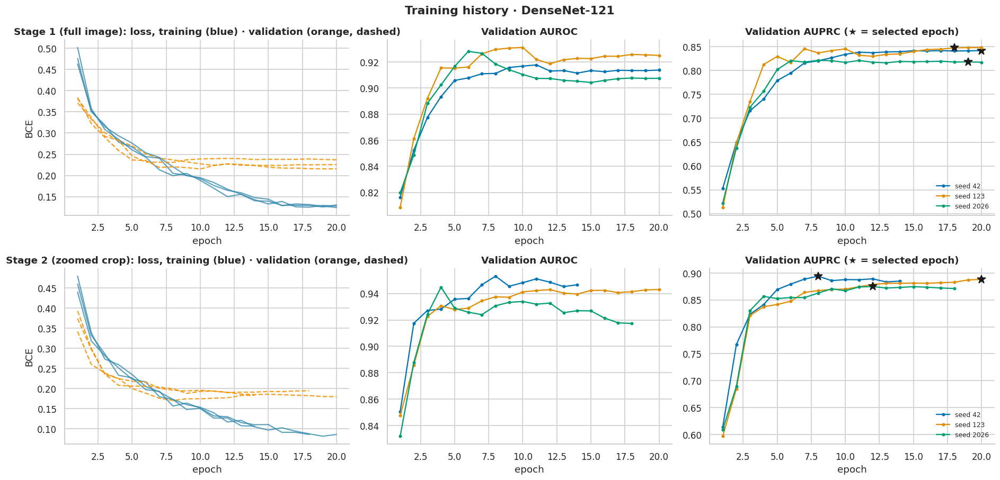

In [24]:
runs = run_model_training('densenet121')
plot_history('densenet121')

### 6.2b · DenseNet-121: train / validation / test results

  DENSENET-121 · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.298 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.993 ± 0.007   
           seed-ensemble           2821        507          0.996   
Validation mean ± SD over 3 seeds   404         72  0.946 ± 0.010   
           seed-ensemble            404         72          0.952   
Test       mean ± SD over 3 seeds   771        122  0.915 ± 0.006   
           seed-ensemble            771        122          0.925   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.983 ± 0.016  0.978 ± 0.008   
           seed-ensemble                   0.990          0.983   
Validation mean ± SD over 3 seeds  0.889 ± 0.011  0.939 ± 0.016   
           seed-ensemble                   0.895          0.946   
Test       mean ± SD over 3 seeds  0.818 ± 0.013  0.918 ± 0.009   
           seed-ensemble                   0.829          0.930   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.963 ± 0.022  0.940 ± 0.046   
           seed-ensemble                   0.968          0.945   
Validation mean ± SD over 3 seeds  0.898 ± 0.002  0.833 ± 0.024   
           seed-ensemble                   0.902          0.833   
Test       mean ± SD over 3 seeds  0.828 ± 0.016  0.697 ± 0.051   
           seed-ensemble                   0.842          0.713   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.987 ± 0.006  0.941 ± 0.024   
           seed-ensemble                   0.991          0.958   
Validation mean ± SD over 3 seeds  0.962 ± 0.025  0.833 ± 0.083   
           seed-ensemble                   0.970          0.857   
Test       mean ± SD over 3 seeds  0.959 ± 0.020  0.772 ± 0.070   
           seed-ensemble                   0.971          0.821   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.987 ± 0.010  0.940 ± 0.023   
           seed-ensemble                   0.988          0.951   
Validation mean ± SD over 3 seeds  0.964 ± 0.004  0.831 ± 0.032   
           seed-ensemble                   0.964          0.845   
Test       mean ± SD over 3 seeds  0.944 ± 0.008  0.729 ± 0.007   
           seed-ensemble                   0.947          0.763   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.927 ± 0.028  0.017 ± 0.007  0.076 ± 0.024  
           seed-ensemble                   0.941          0.015          0.070  
Validation mean ± SD over 3 seeds  0.795 ± 0.041  0.047 ± 0.001  0.178 ± 0.008  
           seed-ensemble                   0.812          0.044          0.170  
Test       mean ± SD over 3 seeds  0.684 ± 0.015  0.060 ± 0.003  0.217 ± 0.013  
           seed-ensemble                   0.725          0.057          0.207

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.353,0.986,0.965,0.970,0.941,0.897,0.985,0.930,0.978,0.914,0.895,0.025,0.103,455,34,52,2280
1,Train,123,0.129,0.999,0.996,0.983,0.985,0.988,0.982,0.924,0.997,0.955,0.946,0.010,0.056,501,41,6,2273
2,Train,2026,0.350,0.995,0.987,0.983,0.963,0.933,0.994,0.969,0.985,0.951,0.940,0.015,0.068,473,15,34,2299
3,Validation,42,0.353,0.954,0.895,0.950,0.899,0.819,0.979,0.894,0.962,0.855,0.826,0.045,0.171,59,7,13,325
4,Validation,123,0.129,0.949,0.895,0.921,0.897,0.861,0.934,0.738,0.969,0.795,0.750,0.047,0.175,62,22,10,310
5,Validation,2026,0.350,0.935,0.876,0.946,0.896,0.819,0.973,0.868,0.961,0.843,0.810,0.048,0.187,59,9,13,323
6,Test,42,0.353,0.918,0.817,0.922,0.824,0.680,0.968,0.798,0.942,0.735,0.692,0.060,0.213,83,21,39,628
7,Test,123,0.129,0.918,0.832,0.908,0.845,0.754,0.937,0.692,0.953,0.722,0.667,0.056,0.207,92,41,30,608
8,Test,2026,0.350,0.907,0.805,0.923,0.815,0.656,0.974,0.825,0.938,0.731,0.693,0.063,0.232,80,17,42,632


Train − validation AUROC gap: +0.048 (large positive = overfitting) | best epoch(s): [20, 18, 19] | train time per run: 25.1 min


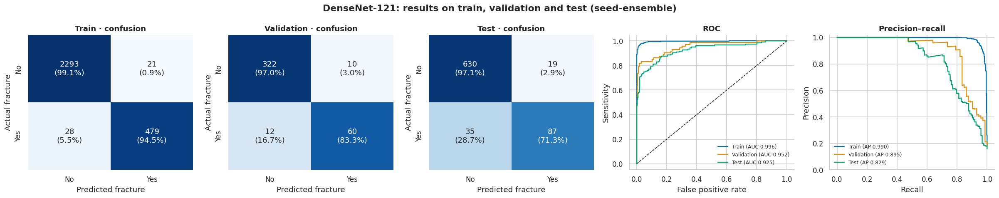

In [25]:
_ = report_model('densenet121')

## Model 3: EfficientNet-B0

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 218MB/s]



  EfficientNet-B0 | seed 42 | stage 1 (full image + localization): 4.32M parameters | ImageNet weights: True
[stage 1] epoch 01/20 | lr 1.1e-06 | train loss 0.5060 acc 0.784 | val loss 0.4024 AUROC 0.7713 AUPRC 0.5714 IoU 0.100 | 25.0s | mem 2.9 GB  <- best
[stage 1] epoch 02/20 | lr 1.0e-04 | train loss 0.3736 acc 0.849 | val loss 0.3626 AUROC 0.8303 AUPRC 0.6914 IoU 0.129 | 20.2s | mem 2.9 GB  <- best
[stage 1] epoch 03/20 | lr 9.9e-05 | train loss 0.3347 acc 0.871 | val loss 0.3473 AUROC 0.8502 AUPRC 0.7779 IoU 0.169 | 20.1s | mem 2.9 GB  <- best
[stage 1] epoch 04/20 | lr 9.7e-05 | train loss 0.3237 acc 0.875 | val loss 0.3196 AUROC 0.8746 AUPRC 0.8544 IoU 0.183 | 19.8s | mem 2.9 GB  <- best
[stage 1] epoch 05/20 | lr 9.4e-05 | train loss 0.3130 acc 0.875 | val loss 0.2985 AUROC 0.8890 AUPRC 0.8970 IoU 0.186 | 20.2s | mem 2.9 GB  <- best
[stage 1] epoch 06/20 | lr 8.9e-05 | train loss 0.2914 acc 0.890 | val loss 0.2784 AUROC 0.9015 AUPRC 0.9282 IoU 0.186 | 20.0s | mem 2.9 GB  <- b

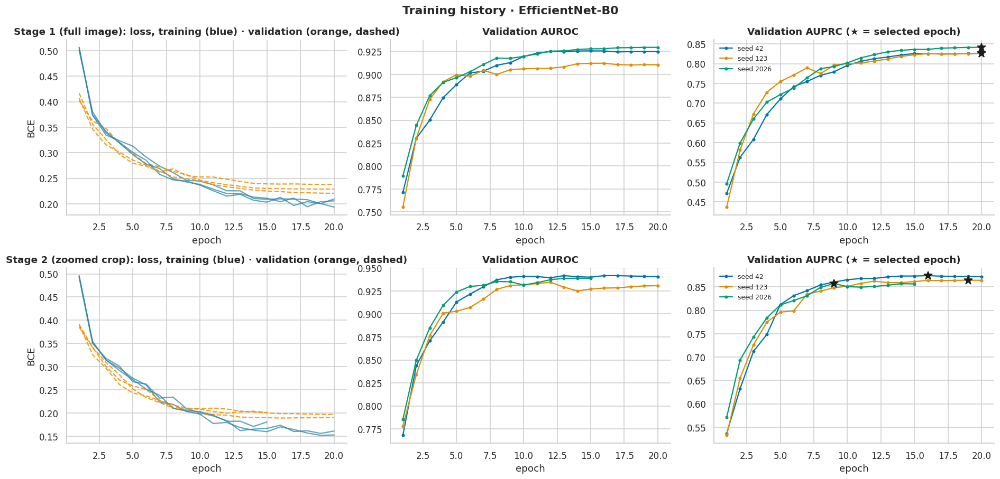

In [26]:
runs = run_model_training('efficientnet_b0')
plot_history('efficientnet_b0')

### 6.3b · EfficientNet-B0: train / validation / test results

  EFFICIENTNET-B0 · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.339 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.985 ± 0.001   
           seed-ensemble           2821        507          0.989   
Validation mean ± SD over 3 seeds   404         72  0.943 ± 0.005   
           seed-ensemble            404         72          0.949   
Test       mean ± SD over 3 seeds   771        122  0.899 ± 0.009   
           seed-ensemble            771        122          0.906   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.959 ± 0.006  0.960 ± 0.003   
           seed-ensemble                   0.965          0.967   
Validation mean ± SD over 3 seeds  0.874 ± 0.005  0.931 ± 0.002   
           seed-ensemble                   0.882          0.941   
Test       mean ± SD over 3 seeds  0.765 ± 0.007  0.900 ± 0.007   
           seed-ensemble                   0.772          0.912   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.937 ± 0.009  0.901 ± 0.019   
           seed-ensemble                   0.931          0.874   
Validation mean ± SD over 3 seeds  0.893 ± 0.005  0.833 ± 0.014   
           seed-ensemble                   0.893          0.819   
Test       mean ± SD over 3 seeds  0.804 ± 0.004  0.664 ± 0.014   
           seed-ensemble                   0.798          0.631   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.973 ± 0.002  0.879 ± 0.007   
           seed-ensemble                   0.988          0.941   
Validation mean ± SD over 3 seeds  0.952 ± 0.005  0.790 ± 0.015   
           seed-ensemble                   0.967          0.843   
Test       mean ± SD over 3 seeds  0.944 ± 0.011  0.692 ± 0.038   
           seed-ensemble                   0.965          0.770   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.978 ± 0.004  0.890 ± 0.009   
           seed-ensemble                   0.973          0.906   
Validation mean ± SD over 3 seeds  0.963 ± 0.003  0.811 ± 0.005   
           seed-ensemble                   0.961          0.831   
Test       mean ± SD over 3 seeds  0.937 ± 0.002  0.677 ± 0.013   
           seed-ensemble                   0.933          0.694   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.866 ± 0.010  0.030 ± 0.003  0.117 ± 0.011  
           seed-ensemble                   0.887          0.028          0.112  
Validation mean ± SD over 3 seeds  0.769 ± 0.006  0.052 ± 0.003  0.191 ± 0.006  
           seed-ensemble                   0.795          0.051          0.186  
Test       mean ± SD over 3 seeds  0.618 ± 0.019  0.070 ± 0.000  0.247 ± 0.002  
           seed-ensemble                   0.647          0.068          0.240

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.217,0.986,0.964,0.963,0.946,0.919,0.973,0.881,0.982,0.900,0.877,0.028,0.110,466,63,41,2251
1,Train,123,0.221,0.986,0.961,0.959,0.937,0.903,0.971,0.871,0.979,0.887,0.862,0.028,0.111,458,68,49,2246
2,Train,2026,0.298,0.984,0.952,0.958,0.928,0.882,0.975,0.885,0.974,0.883,0.858,0.033,0.129,447,58,60,2256
3,Validation,42,0.217,0.947,0.880,0.933,0.894,0.833,0.955,0.800,0.964,0.816,0.776,0.050,0.185,60,15,12,317
4,Validation,123,0.221,0.937,0.871,0.928,0.897,0.847,0.946,0.772,0.966,0.808,0.765,0.051,0.191,61,18,11,314
5,Validation,2026,0.298,0.945,0.871,0.931,0.887,0.819,0.955,0.797,0.961,0.808,0.766,0.055,0.198,59,15,13,317
6,Test,42,0.217,0.910,0.772,0.898,0.799,0.656,0.943,0.684,0.936,0.669,0.609,0.070,0.244,80,37,42,612
7,Test,123,0.221,0.895,0.766,0.894,0.807,0.680,0.934,0.659,0.940,0.669,0.606,0.070,0.248,83,43,39,606
8,Test,2026,0.298,0.893,0.758,0.908,0.806,0.656,0.955,0.734,0.937,0.693,0.640,0.070,0.249,80,29,42,620


Train − validation AUROC gap: +0.042 (large positive = overfitting) | best epoch(s): [20, 20, 20] | train time per run: 13.7 min


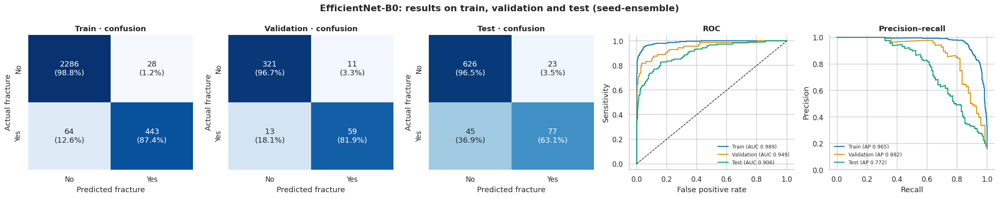

In [27]:
_ = report_model('efficientnet_b0')

## Model 4: MobileNetV3-Large

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 216MB/s]


  MobileNetV3-Large | seed 42 | stage 1 (full image + localization): 3.24M parameters | ImageNet weights: True


[stage 1] epoch 01/20 | lr 1.1e-06 | train loss 0.5049 acc 0.789 | val loss 0.4385 AUROC 0.7277 AUPRC 0.4497 IoU 0.104 | 15.3s | mem 1.5 GB  <- best
[stage 1] epoch 02/20 | lr 1.0e-04 | train loss 0.3911 acc 0.829 | val loss 0.3933 AUROC 0.7921 AUPRC 0.6290 IoU 0.114 | 13.9s | mem 1.5 GB  <- best
[stage 1] epoch 03/20 | lr 9.9e-05 | train loss 0.3410 acc 0.862 | val loss 0.3559 AUROC 0.8235 AUPRC 0.7535 IoU 0.153 | 13.7s | mem 1.5 GB  <- best
[stage 1] epoch 04/20 | lr 9.7e-05 | train loss 0.3255 acc 0.874 | val loss 0.3346 AUROC 0.8452 AUPRC 0.8076 IoU 0.161 | 13.7s | mem 1.5 GB  <- best
[stage 1] epoch 05/20 | lr 9.4e-05 | train loss 0.3142 acc 0.875 | val loss 0.3353 AUROC 0.8684 AUPRC 0.8664 IoU 0.188 | 13.6s | mem 1.5 GB  <- best
[stage 1] epoch 06/20 | lr 8.9e-05 | train loss 0.2945 acc 0.888 | val loss 0.3092 AUROC 0.8865 AUPRC 0.8965 IoU 0.183 | 13.7s | mem 1.5 GB  <- best
[stage 1] epoch 07/20 | lr 8.4e-05 | train loss 0.2796 acc 0.893 | val loss 0.2914 AUROC 0.8922 AUPRC 0.93

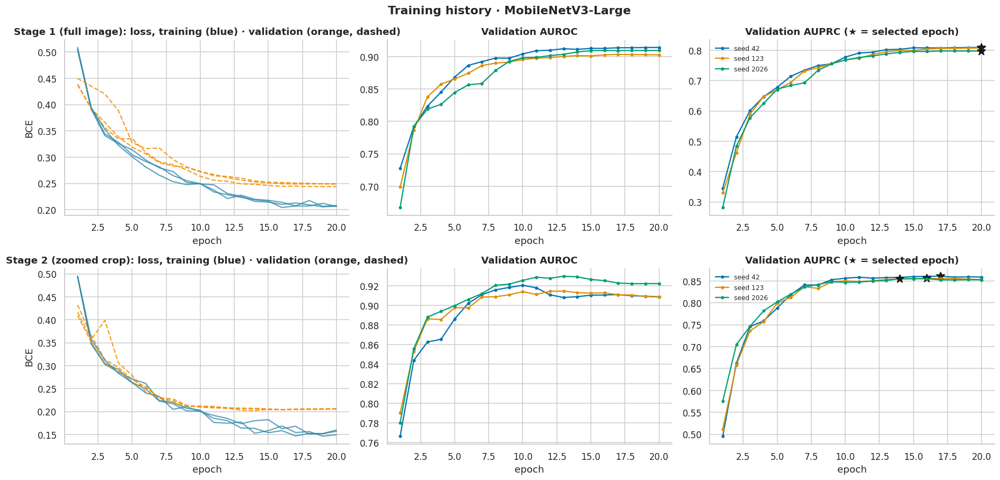

In [28]:
runs = run_model_training('mobilenet_v3_large')
plot_history('mobilenet_v3_large')

### 6.4b · MobileNetV3-Large: train / validation / test results

  MOBILENETV3-LARGE · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.477 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.986 ± 0.005   
           seed-ensemble           2821        507          0.989   
Validation mean ± SD over 3 seeds   404         72  0.927 ± 0.007   
           seed-ensemble            404         72          0.930   
Test       mean ± SD over 3 seeds   771        122  0.905 ± 0.003   
           seed-ensemble            771        122          0.914   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.961 ± 0.008  0.961 ± 0.007   
           seed-ensemble                   0.966          0.963   
Validation mean ± SD over 3 seeds  0.867 ± 0.003  0.935 ± 0.010   
           seed-ensemble                   0.871          0.950   
Test       mean ± SD over 3 seeds  0.782 ± 0.005  0.907 ± 0.007   
           seed-ensemble                   0.794          0.922   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.925 ± 0.009  0.870 ± 0.022   
           seed-ensemble                   0.910          0.826   
Validation mean ± SD over 3 seeds  0.888 ± 0.002  0.815 ± 0.016   
           seed-ensemble                   0.894          0.806   
Test       mean ± SD over 3 seeds  0.798 ± 0.008  0.639 ± 0.022   
           seed-ensemble                   0.791          0.598   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.981 ± 0.011  0.911 ± 0.044   
           seed-ensemble                   0.993          0.961   
Validation mean ± SD over 3 seeds  0.961 ± 0.016  0.822 ± 0.055   
           seed-ensemble                   0.982          0.906   
Test       mean ± SD over 3 seeds  0.957 ± 0.011  0.741 ± 0.045   
           seed-ensemble                   0.983          0.869   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.972 ± 0.004  0.889 ± 0.018   
           seed-ensemble                   0.963          0.889   
Validation mean ± SD over 3 seeds  0.960 ± 0.003  0.817 ± 0.020   
           seed-ensemble                   0.959          0.853   
Test       mean ± SD over 3 seeds  0.934 ± 0.003  0.685 ± 0.015   
           seed-ensemble                   0.929          0.709   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.867 ± 0.023  0.030 ± 0.002  0.122 ± 0.005  
           seed-ensemble                   0.870          0.029          0.118  
Validation mean ± SD over 3 seeds  0.778 ± 0.027  0.052 ± 0.000  0.198 ± 0.002  
           seed-ensemble                   0.825          0.050          0.195  
Test       mean ± SD over 3 seeds  0.634 ± 0.021  0.066 ± 0.001  0.234 ± 0.003  
           seed-ensemble                   0.681          0.064          0.228

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.332,0.990,0.969,0.968,0.934,0.882,0.987,0.935,0.974,0.908,0.889,0.028,0.117,447,31,60,2283
1,Train,123,0.363,0.988,0.961,0.962,0.916,0.844,0.988,0.939,0.967,0.889,0.868,0.031,0.121,428,28,79,2286
2,Train,2026,0.249,0.981,0.952,0.953,0.926,0.884,0.968,0.860,0.974,0.872,0.843,0.032,0.127,448,73,59,2241
3,Validation,42,0.332,0.927,0.870,0.938,0.886,0.806,0.967,0.841,0.958,0.823,0.785,0.052,0.199,58,11,14,321
4,Validation,123,0.363,0.921,0.865,0.943,0.889,0.806,0.973,0.866,0.958,0.835,0.801,0.052,0.199,58,9,14,323
5,Validation,2026,0.249,0.934,0.867,0.923,0.888,0.833,0.943,0.759,0.963,0.795,0.749,0.051,0.196,60,19,12,313
6,Test,42,0.332,0.908,0.783,0.911,0.807,0.656,0.958,0.748,0.937,0.699,0.648,0.066,0.232,80,27,42,622
7,Test,123,0.363,0.906,0.786,0.912,0.791,0.615,0.968,0.781,0.930,0.688,0.644,0.065,0.233,75,21,47,628
8,Test,2026,0.249,0.902,0.777,0.899,0.797,0.648,0.946,0.693,0.935,0.669,0.610,0.067,0.237,79,35,43,614


Train − validation AUROC gap: +0.059 (large positive = overfitting) | best epoch(s): [20, 20, 20] | train time per run: 9.6 min


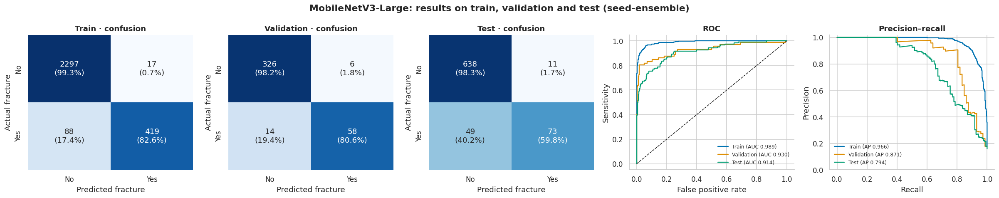

In [29]:
_ = report_model('mobilenet_v3_large')

## Model 5: BoneNet (custom CNN)


  BoneNet (custom) | seed 42 | stage 1 (full image + localization): 2.93M parameters | ImageNet weights: False


/tmp/ipykernel_23/4223304818.py:62: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(net)


[stage 1] epoch 01/20 | lr 1.1e-05 | train loss 0.5549 acc 0.773 | val loss 0.4539 AUROC 0.6935 AUPRC 0.3896 IoU 0.053 | 13.4s | mem 1.7 GB  <- best
[stage 1] epoch 02/20 | lr 1.0e-03 | train loss 0.4788 acc 0.809 | val loss 0.4266 AUROC 0.7267 AUPRC 0.4377 IoU 0.064 | 13.1s | mem 1.7 GB  <- best
[stage 1] epoch 03/20 | lr 9.9e-04 | train loss 0.4405 acc 0.822 | val loss 0.4062 AUROC 0.7574 AUPRC 0.5058 IoU 0.067 | 13.2s | mem 1.7 GB  <- best
[stage 1] epoch 04/20 | lr 9.7e-04 | train loss 0.4261 acc 0.824 | val loss 0.4214 AUROC 0.7526 AUPRC 0.4931 IoU 0.088 | 13.4s | mem 1.7 GB
[stage 1] epoch 05/20 | lr 9.4e-04 | train loss 0.4258 acc 0.827 | val loss 0.4105 AUROC 0.7554 AUPRC 0.5278 IoU 0.092 | 13.1s | mem 1.7 GB  <- best
[stage 1] epoch 06/20 | lr 8.9e-04 | train loss 0.4051 acc 0.830 | val loss 0.3985 AUROC 0.7677 AUPRC 0.5750 IoU 0.107 | 13.2s | mem 1.7 GB  <- best
[stage 1] epoch 07/20 | lr 8.4e-04 | train loss 0.4008 acc 0.835 | val loss 0.3886 AUROC 0.7810 AUPRC 0.6230 IoU 0.

/tmp/ipykernel_23/4223304818.py:62: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(net)


[stage 2] epoch 01/20 | lr 1.1e-05 | train loss 0.5252 acc 0.793 | val loss 0.4752 AUROC 0.6582 AUPRC 0.3118 | 12.8s | mem 1.8 GB  <- best
[stage 2] epoch 02/20 | lr 1.0e-03 | train loss 0.4644 acc 0.822 | val loss 0.4121 AUROC 0.7415 AUPRC 0.4679 | 12.8s | mem 1.8 GB  <- best
[stage 2] epoch 03/20 | lr 9.9e-04 | train loss 0.4338 acc 0.825 | val loss 0.4078 AUROC 0.7384 AUPRC 0.4770 | 12.8s | mem 1.8 GB  <- best
[stage 2] epoch 04/20 | lr 9.7e-04 | train loss 0.4232 acc 0.832 | val loss 0.4154 AUROC 0.7140 AUPRC 0.4440 | 12.9s | mem 1.8 GB
[stage 2] epoch 05/20 | lr 9.4e-04 | train loss 0.4127 acc 0.832 | val loss 0.4078 AUROC 0.7381 AUPRC 0.4877 | 13.0s | mem 1.8 GB  <- best
[stage 2] epoch 06/20 | lr 8.9e-04 | train loss 0.4178 acc 0.833 | val loss 0.4177 AUROC 0.7286 AUPRC 0.4743 | 13.1s | mem 1.8 GB
[stage 2] epoch 07/20 | lr 8.4e-04 | train loss 0.4016 acc 0.837 | val loss 0.4107 AUROC 0.7436 AUPRC 0.5288 | 12.9s | mem 1.8 GB  <- best
[stage 2] epoch 08/20 | lr 7.7e-04 | train lo

/tmp/ipykernel_23/4223304818.py:62: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(net)


... (3 outputs left out)

/tmp/ipykernel_23/4223304818.py:62: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(net)


[stage 1] epoch 01/20 | lr 1.1e-05 | train loss 0.5450 acc 0.796 | val loss 0.4275 AUROC 0.7108 AUPRC 0.4492 IoU 0.046 | 13.5s | mem 1.7 GB  <- best
[stage 1] epoch 02/20 | lr 1.0e-03 | train loss 0.4528 acc 0.818 | val loss 0.4221 AUROC 0.7562 AUPRC 0.4750 IoU 0.064 | 13.3s | mem 1.7 GB  <- best
[stage 1] epoch 03/20 | lr 9.9e-04 | train loss 0.4267 acc 0.822 | val loss 0.4080 AUROC 0.7627 AUPRC 0.5056 IoU 0.077 | 13.3s | mem 1.7 GB  <- best
[stage 1] epoch 04/20 | lr 9.7e-04 | train loss 0.4100 acc 0.837 | val loss 0.4092 AUROC 0.7553 AUPRC 0.5662 IoU 0.092 | 13.3s | mem 1.7 GB  <- best
[stage 1] epoch 05/20 | lr 9.4e-04 | train loss 0.4125 acc 0.828 | val loss 0.3974 AUROC 0.7649 AUPRC 0.5812 IoU 0.100 | 13.3s | mem 1.7 GB  <- best
[stage 1] epoch 06/20 | lr 8.9e-04 | train loss 0.4063 acc 0.836 | val loss 0.3930 AUROC 0.7676 AUPRC 0.6107 IoU 0.108 | 13.4s | mem 1.7 GB  <- best
[stage 1] epoch 07/20 | lr 8.4e-04 | train loss 0.3943 acc 0.836 | val loss 0.3907 AUROC 0.7883 AUPRC 0.63

/tmp/ipykernel_23/4223304818.py:62: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step(); ema.update(net)


[stage 2] epoch 01/20 | lr 1.1e-05 | train loss 0.5224 acc 0.798 | val loss 0.4434 AUROC 0.6876 AUPRC 0.4093 | 12.8s | mem 1.8 GB  <- best
[stage 2] epoch 02/20 | lr 1.0e-03 | train loss 0.4606 acc 0.814 | val loss 0.4268 AUROC 0.6999 AUPRC 0.4654 | 12.9s | mem 1.8 GB  <- best
[stage 2] epoch 03/20 | lr 9.9e-04 | train loss 0.4362 acc 0.824 | val loss 0.4126 AUROC 0.7308 AUPRC 0.4886 | 12.9s | mem 1.8 GB  <- best
[stage 2] epoch 04/20 | lr 9.7e-04 | train loss 0.4192 acc 0.828 | val loss 0.4213 AUROC 0.7052 AUPRC 0.4568 | 12.9s | mem 1.8 GB
[stage 2] epoch 05/20 | lr 9.4e-04 | train loss 0.4094 acc 0.832 | val loss 0.4050 AUROC 0.7381 AUPRC 0.5088 | 12.9s | mem 1.8 GB  <- best
[stage 2] epoch 06/20 | lr 8.9e-04 | train loss 0.3983 acc 0.838 | val loss 0.4015 AUROC 0.7420 AUPRC 0.5092 | 12.8s | mem 1.8 GB  <- best
[stage 2] epoch 07/20 | lr 8.4e-04 | train loss 0.3874 acc 0.844 | val loss 0.3986 AUROC 0.7502 AUPRC 0.5173 | 12.9s | mem 1.8 GB  <- best
[stage 2] epoch 08/20 | lr 7.7e-04 |

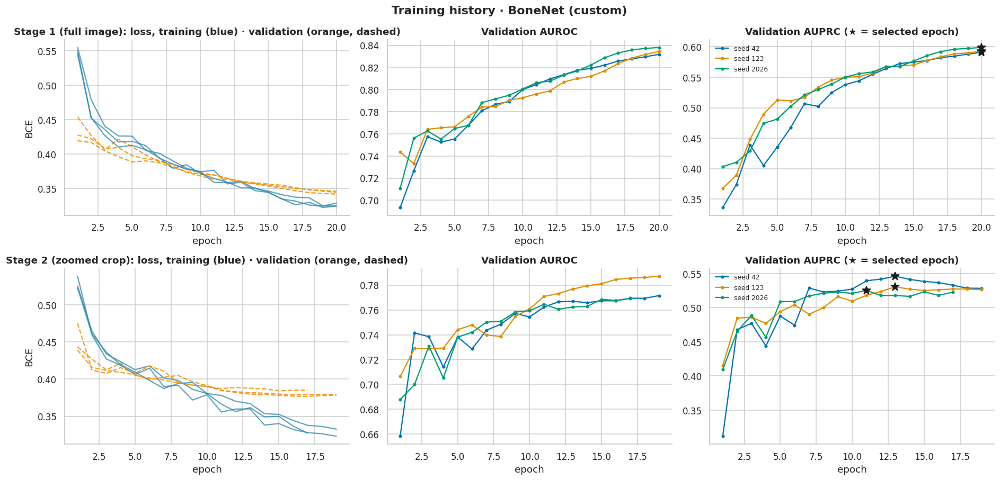

In [30]:
runs = run_model_training('custom_cnn')
plot_history('custom_cnn')

### 6.5b · BoneNet (custom CNN): train / validation / test results

  BONENET (CUSTOM) · TRAIN / VALIDATION / TEST RESULTS · threshold from validation (youden) = 0.171 (ensemble)


n  fractured          AUROC  \
split      row                                                      
Train      mean ± SD over 3 seeds  2821        507  0.885 ± 0.002   
           seed-ensemble           2821        507          0.887   
Validation mean ± SD over 3 seeds   404         72  0.835 ± 0.004   
           seed-ensemble            404         72          0.836   
Test       mean ± SD over 3 seeds   771        122  0.811 ± 0.001   
           seed-ensemble            771        122          0.814   

                                           AUPRC            Acc  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.710 ± 0.008  0.775 ± 0.003   
           seed-ensemble                   0.715          0.794   
Validation mean ± SD over 3 seeds  0.595 ± 0.004  0.738 ± 0.011   
           seed-ensemble                   0.595          0.755   
Test       mean ± SD over 3 seeds  0.557 ± 0.004  0.726 ± 0.003   
           seed-ensemble                   0.563          0.755   

                                          BalAcc           Sens  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.799 ± 0.003  0.836 ± 0.007   
           seed-ensemble                   0.805          0.822   
Validation mean ± SD over 3 seeds  0.771 ± 0.006  0.824 ± 0.008   
           seed-ensemble                   0.769          0.792   
Test       mean ± SD over 3 seeds  0.745 ± 0.010  0.773 ± 0.019   
           seed-ensemble                   0.758          0.762   

                                            Spec            PPV  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.762 ± 0.004  0.435 ± 0.004   
           seed-ensemble                   0.788          0.459   
Validation mean ± SD over 3 seeds  0.719 ± 0.014  0.389 ± 0.011   
           seed-ensemble                   0.747          0.404   
Test       mean ± SD over 3 seeds  0.718 ± 0.001  0.340 ± 0.006   
           seed-ensemble                   0.753          0.368   

                                             NPV             F1  \
split      row                                                    
Train      mean ± SD over 3 seeds  0.955 ± 0.002  0.572 ± 0.004   
           seed-ensemble                   0.953          0.589   
Validation mean ± SD over 3 seeds  0.950 ± 0.002  0.528 ± 0.010   
           seed-ensemble                   0.943          0.535   
Test       mean ± SD over 3 seeds  0.944 ± 0.004  0.472 ± 0.009   
           seed-ensemble                   0.944          0.496   

                                             MCC          Brier       BCE loss  
split      row                                                                  
Train      mean ± SD over 3 seeds  0.482 ± 0.006  0.092 ± 0.002  0.306 ± 0.005  
           seed-ensemble                   0.502          0.091          0.305  
Validation mean ± SD over 3 seeds  0.429 ± 0.012  0.106 ± 0.001  0.344 ± 0.003  
           seed-ensemble                   0.432          0.106          0.343  
Test       mean ± SD over 3 seeds  0.373 ± 0.014  0.100 ± 0.000  0.335 ± 0.002  
           seed-ensemble                   0.401          0.100          0.333

Per-seed results (each seed uses its own validation threshold):


,split,seed,threshold,auroc,auprc,accuracy,balanced_acc,sensitivity,specificity,ppv,npv,f1,mcc,brier,loss,tp,fp,fn,tn
0,Train,42,0.157,0.883,0.709,0.772,0.795,0.830,0.760,0.431,0.953,0.567,0.476,0.092,0.309,421,556,86,1758
1,Train,123,0.166,0.885,0.702,0.778,0.799,0.832,0.766,0.438,0.954,0.574,0.485,0.093,0.310,422,541,85,1773
2,Train,2026,0.152,0.886,0.717,0.775,0.802,0.844,0.760,0.435,0.957,0.574,0.487,0.089,0.301,428,556,79,1758
3,Validation,42,0.157,0.830,0.591,0.730,0.765,0.819,0.711,0.381,0.948,0.520,0.417,0.107,0.347,59,96,13,236
4,Validation,123,0.166,0.837,0.595,0.750,0.777,0.819,0.735,0.401,0.949,0.539,0.441,0.106,0.344,59,88,13,244
5,Validation,2026,0.152,0.838,0.599,0.733,0.772,0.833,0.711,0.385,0.952,0.526,0.428,0.106,0.342,60,96,12,236
6,Test,42,0.157,0.812,0.559,0.725,0.740,0.762,0.718,0.337,0.941,0.467,0.366,0.100,0.334,93,183,29,466
7,Test,123,0.166,0.810,0.553,0.724,0.739,0.762,0.716,0.336,0.941,0.466,0.364,0.101,0.337,93,184,29,465
8,Test,2026,0.152,0.811,0.560,0.730,0.757,0.795,0.718,0.346,0.949,0.483,0.389,0.100,0.333,97,183,25,466


Train − validation AUROC gap: +0.050 (large positive = overfitting) | best epoch(s): [20, 20, 20] | train time per run: 9.1 min


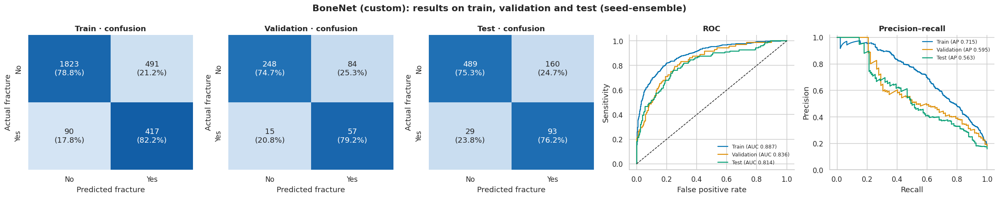

In [31]:
_ = report_model('custom_cnn')

# Section 7: Robustness Analysis

## 7.1 · Corruption functions and visual examples

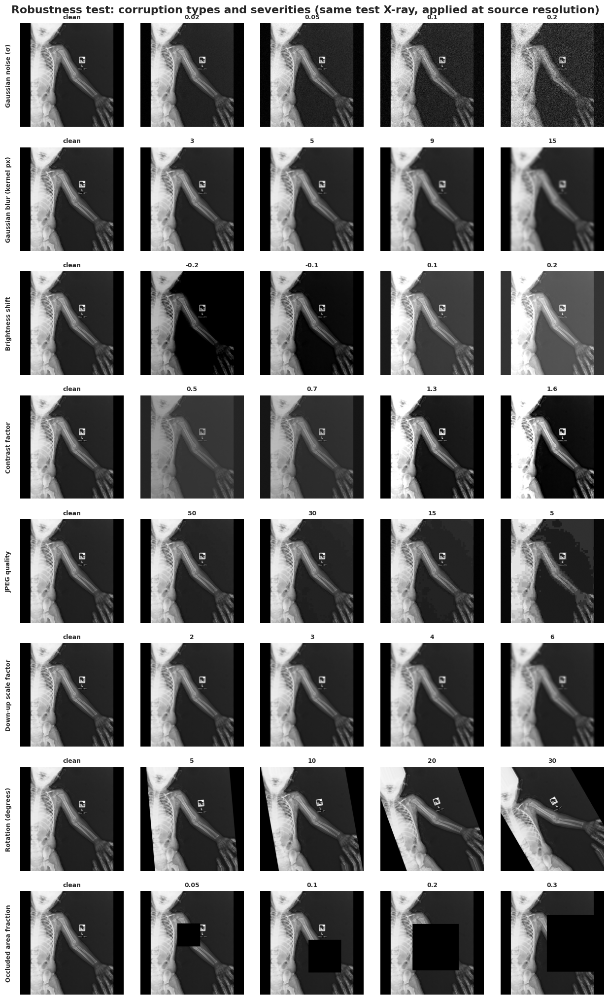

In [32]:
def corrupt(u8, kind, level, seed=0):
    x = u8.float().unsqueeze(1) / 255.; g = torch.Generator().manual_seed(1000 + seed); N, _, S, _ = x.shape
    if kind == 'gaussian_noise': x = x + level * torch.randn(x.shape, generator=g)
    elif kind == 'gaussian_blur' and level > 1:
        k = int(round(level * S / IMG_SIZE)); k += 1 - k % 2; pad = k // 2; k1 = _gauss_kernel(k)
        x = F.conv2d(F.pad(x, (pad, pad, 0, 0), mode='reflect'), k1.view(1, 1, 1, -1)); x = F.conv2d(F.pad(x, (0, 0, pad, pad), mode='reflect'), k1.view(1, 1, -1, 1))
    elif kind == 'brightness': x = x + level
    elif kind == 'contrast': m = x.mean((1, 2, 3), keepdim=True); x = (x - m) * level + m
    elif kind == 'jpeg':
        out = []
        for i in range(N):
            buf = io.BytesIO(); Image.fromarray(u8[i].numpy()).save(buf, format='JPEG', quality=int(level)); buf.seek(0)
            out.append(torch.from_numpy(np.asarray(Image.open(buf).convert('L')).copy()))
        return torch.stack(out)
    elif kind == 'low_resolution' and level > 1:
        small = F.interpolate(x, size=(max(S // int(level), 4),) * 2, mode='bilinear', antialias=True, align_corners=False)
        x = F.interpolate(small, size=(S, S), mode='bilinear', align_corners=False)
    elif kind == 'rotation':
        sign = (torch.arange(N) % 2 == 0).float() * 2 - 1; ang = torch.deg2rad(torch.tensor(float(level))) * sign
        c, s, z = torch.cos(ang), torch.sin(ang), torch.zeros(N)
        theta = torch.stack([torch.stack([c, -s, z], 1), torch.stack([s, c, z], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), mode='bilinear', padding_mode='border', align_corners=False)
    elif kind == 'occlusion' and level > 0:
        side = max(1, int(round(S * math.sqrt(level))))
        for i in range(N):
            ty, tx = int(torch.randint(0, S - side + 1, (1,), generator=g)), int(torch.randint(0, S - side + 1, (1,), generator=g)); x[i, :, ty:ty + side, tx:tx + side] = 0
    return (x.clamp(0, 1) * 255).round().to(torch.uint8)[:, 0]

test_hi = torch.stack([IMGS_HI[p] for p in parts['test'].path])
ex_i = int(np.flatnonzero(yt == 1)[0]); ex_img = test_hi[ex_i:ex_i + 1]
ncol = 1 + max(len(c['levels']) for c in CORRUPTIONS.values())
fig, axes = plt.subplots(len(CORRUPTIONS), ncol, figsize=(2.3 * ncol, 2.35 * len(CORRUPTIONS)), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for r_, (kind, cfg) in enumerate(CORRUPTIONS.items()):
    axes[r_, 0].imshow(ex_img[0], cmap='gray', vmin=0, vmax=255); axes[r_, 0].set_title('clean', fontsize=8)
    axes[r_, 0].text(-0.08, 0.5, cfg['label'], transform=axes[r_, 0].transAxes, rotation=90, va='center', ha='right', fontsize=8, fontweight='bold')
    for c_, lv in enumerate(cfg['levels'], start=1):
        axes[r_, c_].imshow(corrupt(ex_img, kind, lv)[0], cmap='gray', vmin=0, vmax=255); axes[r_, c_].set_title(f'{lv}', fontsize=8)
fig.suptitle('Robustness test: corruption types and severities (same test X-ray, applied at source resolution)', fontweight='bold'); finish(fig, 'R01_corruption_examples', svg=False)

## 7.2 · Evaluate every trained model on every corrupted test set

In [33]:
conds = [('clean', 0)] + [(k, lv) for k, c in CORRUPTIONS.items() for lv in c['levels']]
for name in ARCHS:
    for r in MODEL_RUNS[name]:
        for key in ('ckpt', 'ckpt2'):
            if not Path(r[key]).exists(): raise FileNotFoundError(f'{r[key]} missing: re-run Section 6 for {name}')
PIPES = {name: [load_pipe(r) for r in MODEL_RUNS[name]] for name in ARCHS}
ROB_P = {n: {c: [] for c in conds} for n in ARCHS}
for c in tqdm(conds, desc='Corrupted test conditions'):
    xs = test_hi if c[0] == 'clean' else corrupt(test_hi, *c)
    for name in ARCHS:
        for pipe in PIPES[name]: ROB_P[name][c].append(pipe.run(xs)['p'])
    del xs
for name in ARCHS:
    chk = np.abs(np.mean(ROB_P[name][('clean', 0)], 0) - np.mean([r['p_test'] for r in MODEL_RUNS[name]], 0)).max()
    assert chk < 1e-2, f'clean robustness predictions disagree with stored test predictions for {name} ({chk:.4f})'
del PIPES
if DEVICE.type == 'cuda': torch.cuda.empty_cache()

rows = []
for name in ARCHS:
    thr_lock = RESULTS[name]['thr']
    for kind, cfg in CORRUPTIONS.items():
        for lv in [cfg['clean']] + cfg['levels']:
            c = ('clean', 0) if lv == cfg['clean'] else (kind, lv); P_ = ROB_P[name][c]; pe = np.mean(P_, 0); mt = full_metrics(yt, pe, thr_lock)
            aur = [safe_auc(yt, p) for p in P_]; apr = [safe_ap(yt, p) for p in P_]
            rows.append(dict(model=name, kind=kind, level=lv, is_clean=(lv == cfg['clean']), auroc=float(np.mean(aur)), auroc_sd=float(np.std(aur, ddof=1)) if len(aur) > 1 else 0.0,
                             auprc=float(np.mean(apr)), auprc_sd=float(np.std(apr, ddof=1)) if len(apr) > 1 else 0.0,
                             sensitivity=mt['sensitivity'], specificity=mt['specificity'], accuracy=mt['accuracy'], f1=mt['f1'], mean_prob=float(pe.mean())))
rob = pd.DataFrame(rows); rob.round(4).to_csv(OUT / 'tables' / 'robustness_all_conditions.csv', index=False)
BEST = pd.DataFrame([dict(model=n, v=np.mean([safe_ap(yv, r['p_val']) for r in MODEL_RUNS[n]])) for n in ARCHS]).set_index('model').v.idxmax()
print(f'Best model by mean validation AUPRC (selection rule, used again in Sections 8-9): {nice(BEST)}')
display(rob[rob.model == BEST].round(3).head(12))

Corrupted test conditions:   0%|          | 0/33 [00:00<?, ?it/s]

Best model by mean validation AUPRC (selection rule, used again in Sections 8-9): DenseNet-121


,model,kind,level,is_clean,auroc,auroc_sd,auprc,auprc_sd,sensitivity,specificity,accuracy,f1,mean_prob
40,densenet121,gaussian_noise,0.00,True,0.915,0.006,0.818,0.013,0.713,0.971,0.930,0.763,0.149
41,densenet121,gaussian_noise,0.02,False,0.905,0.012,0.792,0.022,0.713,0.952,0.914,0.725,0.168
42,densenet121,gaussian_noise,0.05,False,0.883,0.022,0.721,0.044,0.795,0.812,0.809,0.569,0.247
43,densenet121,gaussian_noise,0.10,False,0.821,0.045,0.609,0.086,0.861,0.561,0.608,0.410,0.385
44,densenet121,gaussian_noise,0.20,False,0.731,0.074,0.456,0.060,0.689,0.709,0.706,0.425,0.291
45,densenet121,gaussian_blur,1.00,True,0.915,0.006,0.818,0.013,0.713,0.971,0.930,0.763,0.149
46,densenet121,gaussian_blur,3.00,False,0.914,0.007,0.811,0.015,0.697,0.971,0.927,0.752,0.145
47,densenet121,gaussian_blur,5.00,False,0.900,0.008,0.775,0.027,0.623,0.963,0.909,0.685,0.148
48,densenet121,gaussian_blur,9.00,False,0.869,0.029,0.701,0.077,0.623,0.958,0.905,0.676,0.145
49,densenet121,gaussian_blur,15.00,False,0.809,0.092,0.611,0.138,0.328,0.989,0.885,0.473,0.087


## 7.3 · Degradation curves and robustness summary

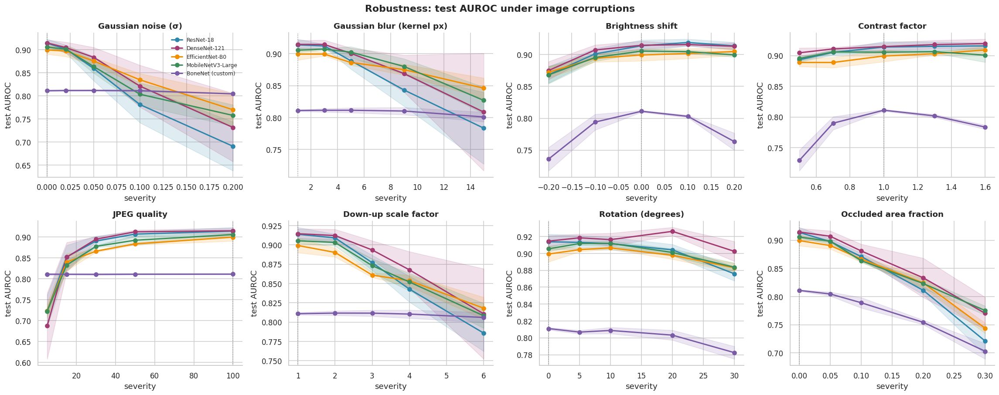

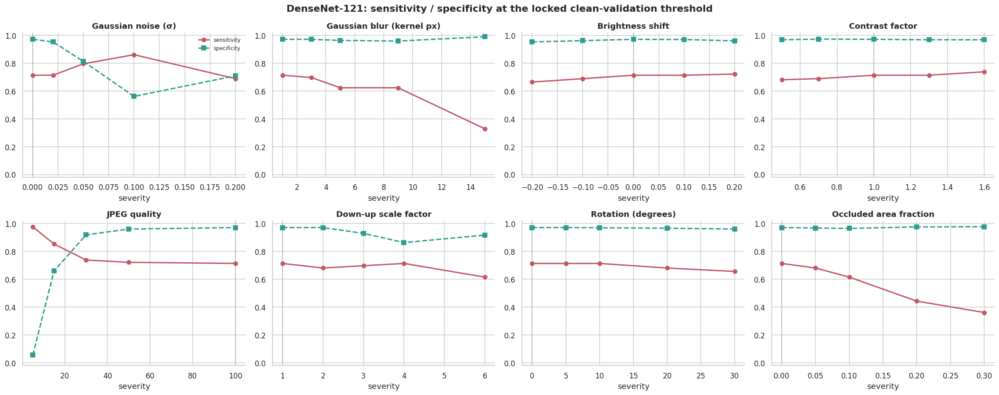

  ROBUSTNESS SUMMARY · test AUROC · drop from clean at the hardest severity (lower = more robust)


,clean AUROC,gaussian_noise,gaussian_blur,brightness,contrast,jpeg,low_resolution,rotation,occlusion,mean,mean AUROC retained %
model,,,,,,,,,,,
ResNet-18,0.914,0.223,0.130,0.046,0.021,0.191,0.128,0.038,0.193,0.121,94.325
DenseNet-121,0.915,0.183,0.106,0.040,0.010,0.228,0.104,0.012,0.144,0.103,95.605
EfficientNet-B0,0.899,0.130,0.053,0.027,0.011,0.176,0.081,0.016,0.155,0.081,96.249
MobileNetV3-Large,0.905,0.148,0.079,0.037,0.010,0.183,0.097,0.022,0.130,0.088,95.761
BoneNet (custom),0.811,0.007,0.010,0.075,0.082,0.001,0.005,0.028,0.108,0.039,97.905


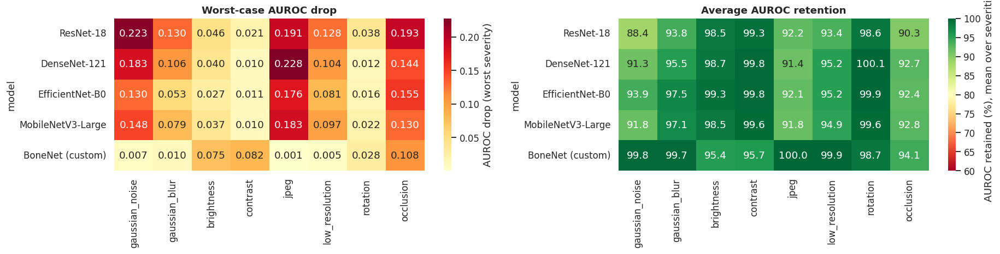

Most robust on average (mean AUROC retention): BoneNet (custom) (97.9%). Read this together with the clean AUROC: a weak model can retain a low score trivially, so robustness only matters for models that perform well when clean.


In [34]:
fig, axes = plt.subplots(2, 4, figsize=(21, 8.4))
for ax, (kind, cfg) in zip(axes.ravel(), CORRUPTIONS.items()):
    for name in ARCHS:
        g = rob[(rob.model == name) & (rob.kind == kind)].sort_values('level')
        ax.plot(g.level, g.auroc, marker='o', lw=2, color=MODEL_PAL[name], label=nice(name)); ax.fill_between(g.level, g.auroc - g.auroc_sd, g.auroc + g.auroc_sd, color=MODEL_PAL[name], alpha=.15)
    ax.axvline(cfg['clean'], color='gray', ls=':', lw=1); ax.set(title=cfg['label'], xlabel='severity', ylabel='test AUROC')
axes[0, 0].legend(frameon=False, fontsize=8); fig.suptitle('Robustness: test AUROC under image corruptions', fontweight='bold'); finish(fig, 'R02_robustness_auroc')

fig, axes = plt.subplots(2, 4, figsize=(21, 8.4))
for ax, (kind, cfg) in zip(axes.ravel(), CORRUPTIONS.items()):
    g = rob[(rob.model == BEST) & (rob.kind == kind)].sort_values('level')
    ax.plot(g.level, g.sensitivity, 'o-', color='#C45566', lw=2, label='sensitivity'); ax.plot(g.level, g.specificity, 's--', color='#2A9D8F', lw=2, label='specificity')
    ax.axvline(cfg['clean'], color='gray', ls=':', lw=1); ax.set(title=cfg['label'], xlabel='severity', ylim=(-.02, 1.02))
axes[0, 0].legend(frameon=False, fontsize=8); fig.suptitle(f'{nice(BEST)}: sensitivity / specificity at the locked clean-validation threshold', fontweight='bold'); finish(fig, 'R03_best_model_sens_spec_under_corruption')

summ = []
for name in ARCHS:
    cl = rob[(rob.model == name) & rob.is_clean].auroc.iloc[0]; row = dict(model=nice(name), clean_auroc=cl)
    for kind in CORRUPTIONS:
        g = rob[(rob.model == name) & (rob.kind == kind) & ~rob.is_clean]; row[f'{kind}_worst_drop'] = float(cl - g.auroc.min()); row[f'{kind}_mean_retention_pct'] = float(100 * g.auroc.mean() / cl)
    row['mean_retention_pct'] = float(np.mean([row[f'{k}_mean_retention_pct'] for k in CORRUPTIONS])); row['mean_worst_drop'] = float(np.mean([row[f'{k}_worst_drop'] for k in CORRUPTIONS])); summ.append(row)
summ = pd.DataFrame(summ).set_index('model'); summ.round(4).to_csv(OUT / 'tables' / 'robustness_summary.csv')
print('=' * 104); print('  ROBUSTNESS SUMMARY · test AUROC · drop from clean at the hardest severity (lower = more robust)'); print('=' * 104)
show = summ[[f'{k}_worst_drop' for k in CORRUPTIONS] + ['mean_worst_drop', 'mean_retention_pct']].copy(); show.columns = [c.replace('_worst_drop', '').replace('mean_retention_pct', 'mean AUROC retained %') for c in show.columns]; show.insert(0, 'clean AUROC', summ.clean_auroc)
display(show.round(3))
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4))
sns.heatmap(summ[[f'{k}_worst_drop' for k in CORRUPTIONS]].rename(columns=lambda c: c.replace('_worst_drop', '')), annot=True, fmt='.3f', cmap='YlOrRd', ax=axes[0], cbar_kws={'label': 'AUROC drop (worst severity)'})
sns.heatmap(summ[[f'{k}_mean_retention_pct' for k in CORRUPTIONS]].rename(columns=lambda c: c.replace('_mean_retention_pct', '')), annot=True, fmt='.1f', cmap='RdYlGn', vmin=60, vmax=100, ax=axes[1], cbar_kws={'label': 'AUROC retained (%), mean over severities'})
axes[0].set_title('Worst-case AUROC drop'); axes[1].set_title('Average AUROC retention'); finish(fig, 'R04_robustness_summary_heatmaps')
most = summ.mean_retention_pct.idxmax(); print(f'Most robust on average (mean AUROC retention): {most} ({summ.mean_retention_pct.max():.1f}%). Read this together with the clean AUROC: a weak model can retain a low score trivially, so robustness only matters for models that perform well when clean.')

## 7.4 · Seed stability

auroc         auprc        sensitivity        specificity  \
                     mean    std   mean    std        mean    std        mean   
model                                                                           
resnet18            0.914  0.009  0.788  0.007       0.694  0.096       0.934   
densenet121         0.915  0.006  0.818  0.013       0.697  0.051       0.959   
efficientnet_b0     0.899  0.009  0.765  0.007       0.664  0.014       0.944   
mobilenet_v3_large  0.905  0.003  0.782  0.005       0.639  0.022       0.957   
custom_cnn          0.811  0.001  0.557  0.004       0.773  0.019       0.718   

                              f1         
                      std   mean    std  
model                                    
resnet18            0.049  0.681  0.035  
densenet121         0.020  0.729  0.007  
efficientnet_b0     0.011  0.677  0.013  
mobilenet_v3_large  0.011  0.685  0.015  
custom_cnn          0.001  0.472  0.009

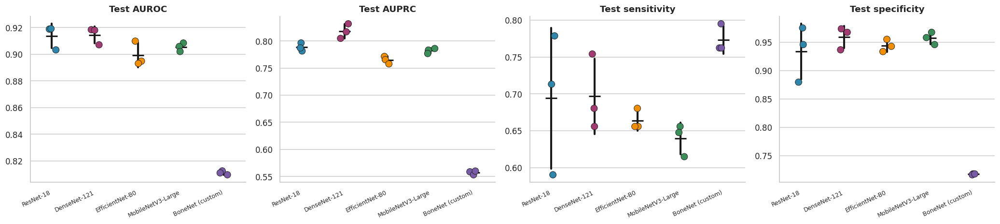

In [35]:
rows = []
for name in ARCHS:
    for r in MODEL_RUNS[name]:
        m = full_metrics(yt, r['p_test'], r['thr']); rows.append(dict(model=name, seed=r['seed'], auroc=m['auroc'], auprc=m['auprc'], sensitivity=m['sensitivity'], specificity=m['specificity'], f1=m['f1']))
seed_df = pd.DataFrame(rows)
stab = seed_df.groupby('model')[['auroc', 'auprc', 'sensitivity', 'specificity', 'f1']].agg(['mean', 'std']).reindex(ARCHS); stab.round(4).to_csv(OUT / 'tables' / 'seed_stability.csv'); display(stab.round(3))
if len(SEEDS) > 1:
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
    for ax, (m, lab) in zip(axes, [('auroc', 'Test AUROC'), ('auprc', 'Test AUPRC'), ('sensitivity', 'Test sensitivity'), ('specificity', 'Test specificity')]):
        sns.stripplot(data=seed_df, x='model', y=m, order=ARCHS, hue='model', palette=MODEL_PAL, size=9, edgecolor='k', linewidth=.6, legend=False, ax=ax)
        sns.pointplot(data=seed_df, x='model', y=m, order=ARCHS, color='k', linestyle='none', errorbar='sd', markers='_', markersize=16, ax=ax)
        ax.set(title=lab, xlabel='', ylabel=''); ax.set_xticks(range(len(ARCHS))); ax.set_xticklabels([nice(x) for x in ARCHS], rotation=25, ha='right', fontsize=8)
    finish(fig, 'R05_seed_stability')
else:
    print('Only one seed was trained: seed stability cannot be assessed (set SEEDS = [42, 123, 2026]).')

## 7.5 · External dataset shift (HBFMID originals)

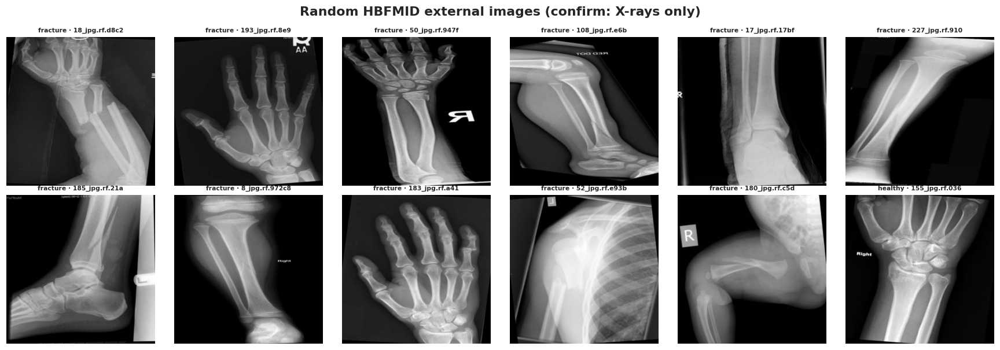

,model,n,fractured,healthy,sensitivity_main_threshold,sens_lo_main_threshold,sens_hi_main_threshold,healthy_flagged_main_threshold,sensitivity_sens90_threshold,sens_lo_sens90_threshold,sens_hi_sens90_threshold,healthy_flagged_sens90_threshold,internal_test_sensitivity
0,ResNet-18,161,151,10,0.517,0.437,0.595,1,0.987,0.953,0.996,6,0.664
1,DenseNet-121,161,151,10,0.669,0.590,0.739,1,0.960,0.916,0.982,6,0.713
2,EfficientNet-B0,161,151,10,0.517,0.437,0.595,3,0.947,0.899,0.973,6,0.631
3,MobileNetV3-Large,161,151,10,0.437,0.361,0.517,2,0.940,0.891,0.968,6,0.598
4,BoneNet (custom),161,151,10,0.682,0.604,0.751,7,0.960,0.916,0.982,10,0.762


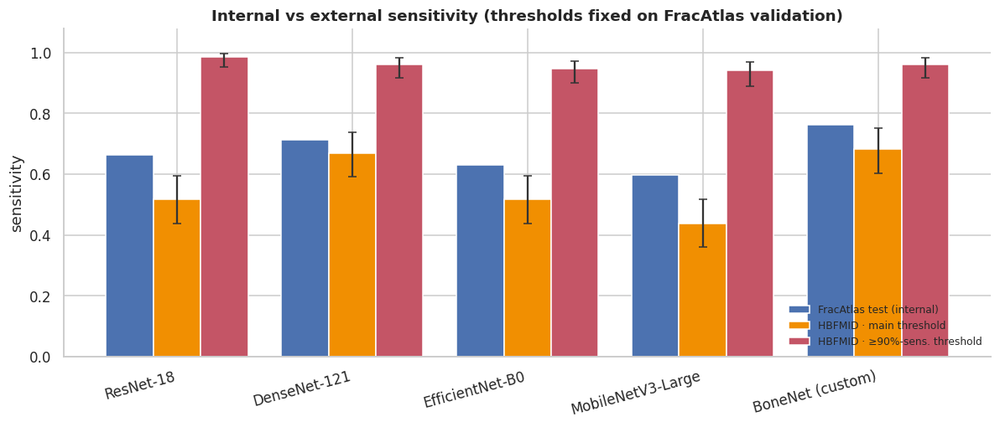

External set: 151 fractured, 10 healthy -> only sensitivity is meaningful.


In [36]:
ENS_EXT_OK = len(ext) > 0 and all(len(r['p_ext']) for n in ARCHS for r in MODEL_RUNS[n])
if not ENS_EXT_OK:
    print('No external predictions available (HBFMID labels or eligible X-ray originals missing); skipped.')
else:
    if DISPLAY_GALLERIES:
        sm = ext.sample(min(12, len(ext)), random_state=SEED); fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
        for ax in axes.ravel(): ax.axis('off')
        for ax, (_, r) in zip(axes.ravel(), sm.iterrows()):
            ax.imshow(IMGS[r.path].numpy(), cmap='gray'); ax.set_title(('fracture' if r.label else 'healthy') + f' · {Path(r.path).name[:14]}', fontsize=7)
        fig.suptitle('Random HBFMID external images (confirm: X-rays only)', fontweight='bold'); finish(fig, 'R06_external_samples', svg=False)
    rows = []
    for name in ARCHS:
        pe = np.mean([r['p_ext'] for r in MODEL_RUNS[name]], 0); tv = RESULTS[name]['thr']; ts = choose_threshold(yv, ensemble_of(name, 'val'), 'sens90')
        rr = dict(model=nice(name), n=len(ye), fractured=int(ye.sum()), healthy=int((ye == 0).sum()))
        for tag, t in [('main_threshold', tv), ('sens90_threshold', ts)]:
            hit = int((pe[ye == 1] >= t).sum()); lo, hi = wilson(hit, int((ye == 1).sum()))
            rr.update({f'sensitivity_{tag}': hit / max(int((ye == 1).sum()), 1), f'sens_lo_{tag}': lo, f'sens_hi_{tag}': hi, f'healthy_flagged_{tag}': int((pe[ye == 0] >= t).sum())})
        rr['internal_test_sensitivity'] = full_metrics(yt, ensemble_of(name, 'test'), tv)['sensitivity']; rows.append(rr)
    ext_df = pd.DataFrame(rows); ext_df.round(4).to_csv(OUT / 'tables' / 'external_hbfmid.csv', index=False); display(ext_df.round(3))
    fig, ax = plt.subplots(figsize=(11, 4.8)); w = .27; xx = np.arange(len(ARCHS))
    ax.bar(xx - w, ext_df.internal_test_sensitivity, w, label='FracAtlas test (internal)', color='#4C72B0')
    for j, (tag, col, lab) in enumerate([('main_threshold', '#F18F01', 'HBFMID · main threshold'), ('sens90_threshold', '#C45566', f'HBFMID · ≥{SENS_TARGET:.0%}-sens. threshold')]):
        v = ext_df[f'sensitivity_{tag}'].values; ax.bar(xx + j * w, v, w, label=lab, color=col, yerr=errbars(v, ext_df[f'sens_lo_{tag}'].values, ext_df[f'sens_hi_{tag}'].values), capsize=3, ecolor='#333')
    ax.set_xticks(xx); ax.set_xticklabels([nice(k) for k in ARCHS], rotation=15, ha='right'); ax.set(ylabel='sensitivity', ylim=(0, 1.08), title='Internal vs external sensitivity (thresholds fixed on FracAtlas validation)'); ax.legend(frameon=False, fontsize=8, loc='lower right')
    finish(fig, 'R07_internal_vs_external_sensitivity'); print(f'External set: {int(ye.sum())} fractured, {int((ye == 0).sum())} healthy -> only sensitivity is meaningful.')

# Section 8: Evaluation & Comparison

## 8.1 · Unified comparison table

In [37]:
KEYS = ARCHS + (['ensemble_all'] if len(ARCHS) > 1 else [])
PAL = {**MODEL_PAL}; ens, thr = {}, {}
for name in ARCHS: ens[name] = {k: ensemble_of(name, k) for k in ['train', 'val', 'test']}; ens[name]['ext'] = ensemble_of(name, 'ext') if ENS_EXT_OK else None
if len(ARCHS) > 1: ens['ensemble_all'] = {k: np.mean([ens[n][k] for n in ARCHS], 0) for k in ['train', 'val', 'test']}; ens['ensemble_all']['ext'] = np.mean([ens[n]['ext'] for n in ARCHS], 0) if ENS_EXT_OK else None
for k in KEYS: thr[k] = {'main': choose_threshold(yv, ens[k]['val']), 'sens90': choose_threshold(yv, ens[k]['val'], 'sens90'), 'spec90': choose_threshold(yv, ens[k]['val'], 'spec90')}

def per_model(name):
    runs = MODEL_RUNS[name]; f = lambda y, key: pd.DataFrame([full_metrics(y, r[f'p_{key}'], r['thr']) for r in runs])
    tr_, va_, te_ = f(ytr, 'train'), f(yv, 'val'), f(yt, 'test')
    return dict(tr_auroc=tr_.auroc.mean(), va_auroc=va_.auroc.mean(), te_auroc=te_.auroc.mean(), te_auprc=te_.auprc.mean(), te_acc=te_.accuracy.mean(), te_sens=te_.sensitivity.mean(), te_spec=te_.specificity.mean(),
                te_f1=te_.f1.mean(), te_mcc=te_.mcc.mean(), va_auprc=va_.auprc.mean(), tr_loss=tr_.loss.mean(), va_loss=va_.loss.mean(), te_loss=te_.loss.mean(), best_epoch=np.mean([r['best_epoch'] for r in runs]),
                epochs=np.mean([r['epochs_run'] for r in runs]), minutes=np.mean([r['train_time_s'] for r in runs]) / 60, params=runs[0]['params'] / 1e6)
PM = pd.DataFrame({n: per_model(n) for n in ARCHS}); PM.round(4).to_csv(OUT / 'tables' / 'unified_comparison.csv')
ROWS = [('Train AUROC', 'tr_auroc', 'neutral'), ('Validation AUROC', 'va_auroc', 'higher'), ('Validation AUPRC (selection metric)', 'va_auprc', 'higher'), ('Test AUROC', 'te_auroc', 'higher'), ('Test AUPRC', 'te_auprc', 'higher'),
        ('Test accuracy', 'te_acc', 'higher'), ('Test sensitivity', 'te_sens', 'higher'), ('Test specificity', 'te_spec', 'higher'), ('Test F1', 'te_f1', 'higher'), ('Test MCC', 'te_mcc', 'higher'),
        ('Train loss (BCE)', 'tr_loss', 'neutral'), ('Validation loss (BCE)', 'va_loss', 'lower'), ('Test loss (BCE)', 'te_loss', 'lower'), ('Selected epoch (mean)', 'best_epoch', 'neutral'),
        ('Epochs run (mean)', 'epochs', 'neutral'), ('Training time per run (min)', 'minutes', 'lower'), ('Parameters (M)', 'params', 'lower')]
W = 24 + 19 * len(ARCHS); print('=' * W); print(f'  UNIFIED MODEL COMPARISON · mean over {len(SEEDS)} seed(s) · per-seed validation threshold ({THRESHOLD_RULE})'); print('=' * W)
print(f'  {"Metric":<38}|' + ''.join(f'{nice(n)[:17]:>19}' for n in ARCHS)); print('-' * W)
for lab, key, d in ROWS:
    v = PM.loc[key, ARCHS].values.astype(float); b = (np.argmax(v) if d == 'higher' else np.argmin(v)) if d != 'neutral' else -1
    print(f'  {lab:<38}|' + ''.join(f'{x:>17.4f}' + (' ◄' if i == b else '  ') for i, x in enumerate(v)))
print('=' * W); print('  ◄ = best of the compared models for that row (test numbers are descriptive, selection used validation only)')
print(f'\nBest model by validation AUPRC: {nice(BEST)}')

  UNIFIED MODEL COMPARISON · mean over 3 seed(s) · per-seed validation threshold (youden)
  Metric                                |          ResNet-18       DenseNet-121    EfficientNet-B0  MobileNetV3-Large   BoneNet (custom)
-----------------------------------------------------------------------------------------------------------------------
  Train AUROC                           |           0.9890             0.9934             0.9854             0.9862             0.8846  
  Validation AUROC                      |           0.9340             0.9458 ◄           0.9429             0.9274             0.8350  
  Validation AUPRC (selection metric)   |           0.8765             0.8885 ◄           0.8740             0.8673             0.5950  
  Test AUROC                            |           0.9138             0.9146 ◄           0.8993             0.9054             0.8110  
  Test AUPRC                            |           0.7885             0.8179 ◄           0.7650         

## 8.2 · Test-set metrics with 95 % cluster-bootstrap confidence intervals

Cluster bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

TABLE 1 · test set · mean ± SD over 3 seed(s)  (* = selected on validation)


,AUROC,AUPRC,Accuracy,Bal. acc.,Sensitivity,Specificity,PPV,NPV,F1,MCC,Cohen κ,Brier,ECE
ResNet-18,0.914 ± 0.009,0.788 ± 0.007,0.896 ± 0.028,0.814 ± 0.027,0.694 ± 0.096,0.934 ± 0.049,0.693 ± 0.136,0.943 ± 0.014,0.681 ± 0.035,0.628 ± 0.045,0.620 ± 0.051,0.065 ± 0.002,0.025 ± 0.006
DenseNet-121 *,0.915 ± 0.006,0.818 ± 0.013,0.918 ± 0.009,0.828 ± 0.016,0.697 ± 0.051,0.959 ± 0.020,0.772 ± 0.070,0.944 ± 0.008,0.729 ± 0.007,0.684 ± 0.015,0.681 ± 0.012,0.060 ± 0.003,0.025 ± 0.004
EfficientNet-B0,0.899 ± 0.009,0.765 ± 0.007,0.900 ± 0.007,0.804 ± 0.004,0.664 ± 0.014,0.944 ± 0.011,0.692 ± 0.038,0.937 ± 0.002,0.677 ± 0.013,0.618 ± 0.019,0.618 ± 0.018,0.070 ± 0.000,0.027 ± 0.009
MobileNetV3-Large,0.905 ± 0.003,0.782 ± 0.005,0.907 ± 0.007,0.798 ± 0.008,0.639 ± 0.022,0.957 ± 0.011,0.741 ± 0.045,0.934 ± 0.003,0.685 ± 0.015,0.634 ± 0.021,0.631 ± 0.019,0.066 ± 0.001,0.019 ± 0.004
BoneNet (custom),0.811 ± 0.001,0.557 ± 0.004,0.726 ± 0.003,0.745 ± 0.010,0.773 ± 0.019,0.718 ± 0.001,0.340 ± 0.006,0.944 ± 0.004,0.472 ± 0.009,0.373 ± 0.014,0.323 ± 0.011,0.100 ± 0.000,0.029 ± 0.003


TABLE 2 · test set · seed-ensemble · 95 % cluster-bootstrap CI (1000 resamples, 711 test families)


,AUROC,AUPRC,Sensitivity,Specificity,PPV,F1,MCC,Accuracy
model,,,,,,,,
ResNet-18,0.928 (0.901–0.951),0.808 (0.749–0.863),0.664 (0.571–0.748),0.971 (0.958–0.983),0.810 (0.738–0.885),0.730 (0.660–0.793),0.689 (0.613–0.762),0.922 (0.902–0.941)
DenseNet-121,0.925 (0.891–0.953),0.829 (0.771–0.882),0.713 (0.630–0.793),0.971 (0.958–0.983),0.821 (0.745–0.893),0.763 (0.698–0.822),0.725 (0.654–0.793),0.930 (0.911–0.949)
EfficientNet-B0,0.906 (0.873–0.937),0.772 (0.705–0.836),0.631 (0.543–0.719),0.965 (0.950–0.978),0.770 (0.692–0.852),0.694 (0.619–0.760),0.647 (0.567–0.722),0.912 (0.890–0.932)
MobileNetV3-Large,0.914 (0.883–0.942),0.794 (0.731–0.852),0.598 (0.511–0.685),0.983 (0.973–0.992),0.869 (0.795–0.939),0.709 (0.631–0.781),0.681 (0.604–0.758),0.922 (0.903–0.941)
BoneNet (custom),0.814 (0.769–0.858),0.563 (0.477–0.645),0.762 (0.675–0.850),0.753 (0.719–0.787),0.368 (0.307–0.429),0.496 (0.431–0.557),0.401 (0.329–0.470),0.755 (0.723–0.786)
Ensemble (all models),0.919 (0.887–0.948),0.802 (0.737–0.861),0.705 (0.619–0.789),0.957 (0.941–0.972),0.754 (0.676–0.829),0.729 (0.660–0.792),0.680 (0.605–0.753),0.917 (0.897–0.936)


TABLE 3 · alternative operating points (thresholds from validation)


,model,operating_point,threshold,sensitivity,specificity,ppv,npv,f1,mcc,tp,fp,fn,tn
0,ResNet-18,≥90% sensitivity on validation,0.062,0.852,0.797,0.441,0.966,0.581,0.514,104,132,18,517
1,ResNet-18,≥90% specificity on validation,0.188,0.721,0.934,0.672,0.947,0.696,0.637,88,43,34,606
2,DenseNet-121,≥90% sensitivity on validation,0.067,0.877,0.824,0.484,0.973,0.624,0.566,107,114,15,535
3,DenseNet-121,≥90% specificity on validation,0.298,0.713,0.971,0.821,0.947,0.763,0.725,87,19,35,630
4,EfficientNet-B0,≥90% sensitivity on validation,0.073,0.836,0.792,0.430,0.963,0.568,0.497,102,135,20,514
5,EfficientNet-B0,≥90% specificity on validation,0.133,0.754,0.888,0.558,0.950,0.641,0.571,92,73,30,576
6,MobileNetV3-Large,≥90% sensitivity on validation,0.063,0.918,0.740,0.399,0.980,0.556,0.499,112,169,10,480
7,MobileNetV3-Large,≥90% specificity on validation,0.196,0.738,0.931,0.667,0.950,0.700,0.642,90,45,32,604
8,BoneNet (custom),≥90% sensitivity on validation,0.101,0.877,0.550,0.268,0.960,0.411,0.312,107,292,15,357
9,BoneNet (custom),≥90% specificity on validation,0.300,0.516,0.898,0.488,0.908,0.502,0.405,63,66,59,583


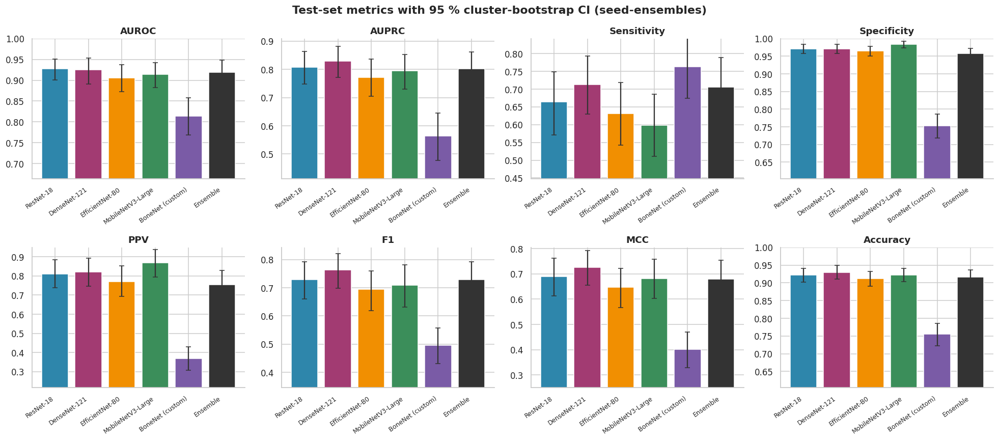

In [38]:
thr_main = {k: thr[k]['main'] for k in KEYS}
boot = cluster_bootstrap(yt, {k: ens[k]['test'] for k in KEYS}, gt, thr_main, N_BOOT)
rows = []
for k in KEYS:
    full = full_metrics(yt, ens[k]['test'], thr_main[k]); r = dict(model=nice(k), threshold=thr_main[k])
    for m in BOOT_METRICS: lo, hi = ci95(boot[k][m]); r.update({m: full[m], f'{m}_lo': lo, f'{m}_hi': hi})
    r.update({m: full[m] for m in ['balanced_acc', 'npv', 'kappa', 'brier', 'ece', 'tp', 'fp', 'fn', 'tn']}); rows.append(r)
ci_df = pd.DataFrame(rows); ci_df.round(4).to_csv(OUT / 'tables' / 'table2_seed_ensemble_with_95CI.csv', index=False)
fmt = lambda r, m: f'{r[m]:.3f} ({r[m + "_lo"]:.3f}–{r[m + "_hi"]:.3f})'
tab2 = pd.DataFrame({lab: [fmt(r, m) for _, r in ci_df.iterrows()] for m, lab in [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity'), ('ppv', 'PPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('accuracy', 'Accuracy')]}, index=ci_df.model)
tab2.to_csv(OUT / 'tables' / 'table2_formatted.csv')
per_seed = pd.DataFrame([dict(model=r['model'], seed=r['seed'], **full_metrics(yt, r['p_test'], r['thr'])) for n in ARCHS for r in MODEL_RUNS[n]])
g_ = per_seed.groupby('model'); cols = [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('accuracy', 'Accuracy'), ('balanced_acc', 'Bal. acc.'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity'), ('ppv', 'PPV'), ('npv', 'NPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('kappa', 'Cohen κ'), ('brier', 'Brier'), ('ece', 'ECE')]
mn, sd = g_[[c for c, _ in cols]].mean().reindex(ARCHS), g_[[c for c, _ in cols]].std().reindex(ARCHS)
tab1 = pd.DataFrame({lab: [f'{mn.loc[m, c]:.3f} ± {sd.loc[m, c]:.3f}' if len(SEEDS) > 1 else f'{mn.loc[m, c]:.3f}' for m in ARCHS] for c, lab in cols}, index=[nice(m) + (' *' if m == BEST else '') for m in ARCHS])
tab1.to_csv(OUT / 'tables' / 'table1_mean_sd_over_seeds.csv')
print(f'TABLE 1 · test set · mean ± SD over {len(SEEDS)} seed(s)  (* = selected on validation)'); display(tab1)
print(f'TABLE 2 · test set · seed-ensemble · 95 % cluster-bootstrap CI ({N_BOOT} resamples, {len(np.unique(gt))} test families)'); display(tab2)
rows = []
for k in KEYS:
    for tag in ['sens90', 'spec90']:
        m = full_metrics(yt, ens[k]['test'], thr[k][tag]); rows.append(dict(model=nice(k), operating_point={'sens90': f'≥{SENS_TARGET:.0%} sensitivity on validation', 'spec90': f'≥{SPEC_TARGET:.0%} specificity on validation'}[tag],
            threshold=thr[k][tag], **{c: m[c] for c in ['sensitivity', 'specificity', 'ppv', 'npv', 'f1', 'mcc', 'tp', 'fp', 'fn', 'tn']}))
op_df = pd.DataFrame(rows); op_df.round(4).to_csv(OUT / 'tables' / 'table3_operating_points.csv', index=False); print('TABLE 3 · alternative operating points (thresholds from validation)'); display(op_df.round(3))

pw = []
for a_, b_ in itertools.permutations(KEYS, 2):
    for m in ['auroc', 'auprc']:
        d = boot[a_][m] - boot[b_][m]; lo, hi = ci95(d); pw.append(dict(model_a=nice(a_), model_b=nice(b_), metric=m, diff=float(d.mean()), ci_low=lo, ci_high=hi, excludes_zero=bool(lo > 0 or hi < 0)))
pw_df = pd.DataFrame(pw); pw_df.round(4).to_csv(OUT / 'tables' / 'pairwise_differences.csv', index=False)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (m, lab) in zip(axes.ravel(), [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity'), ('ppv', 'PPV'), ('f1', 'F1'), ('mcc', 'MCC'), ('accuracy', 'Accuracy')]):
    v = ci_df[m].values; ax.bar(range(len(KEYS)), v, color=[PAL[k] for k in KEYS], yerr=errbars(v, ci_df[f'{m}_lo'].values, ci_df[f'{m}_hi'].values), capsize=3, ecolor='#333')
    ax.set_xticks(range(len(KEYS))); ax.set_xticklabels([nice(k).replace('Ensemble (all models)', 'Ensemble') for k in KEYS], rotation=35, ha='right', fontsize=8); ax.set_title(lab); ax.set_ylim(max(0, v.min() - .15), min(1.0, v.max() + .08))
fig.suptitle('Test-set metrics with 95 % cluster-bootstrap CI (seed-ensembles)', fontweight='bold'); finish(fig, 'E01_metrics_with_CI')

## 8.3 · Convergence, ROC, precision–recall and confusion matrices

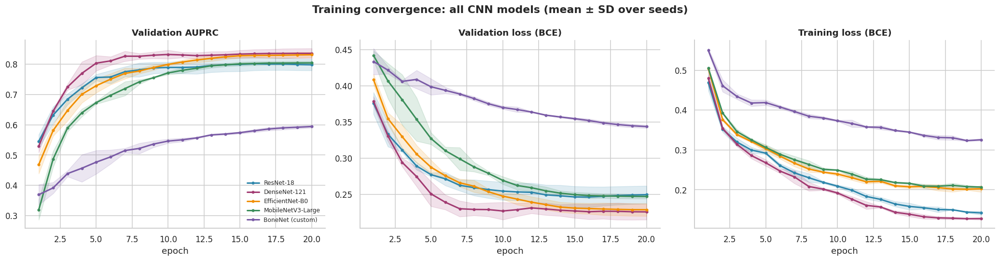

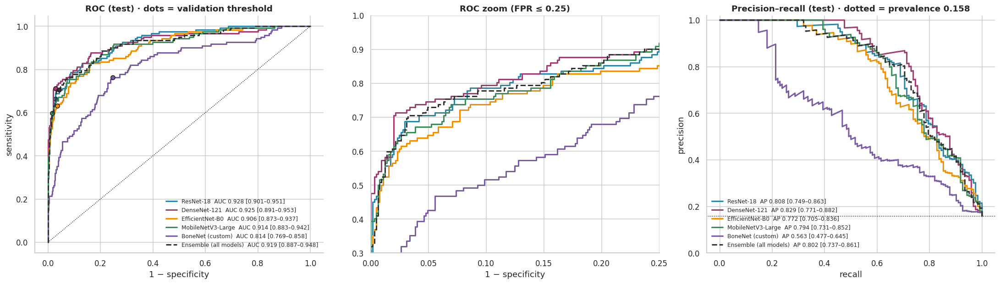

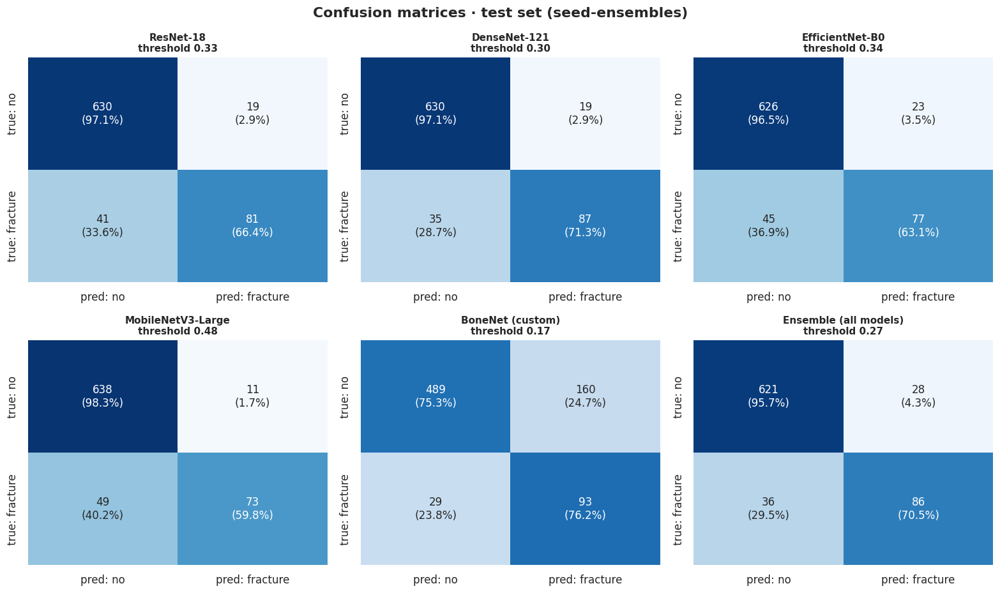

In [39]:
h_all = pd.concat([pd.DataFrame(r['hist']) for n in ARCHS for r in MODEL_RUNS[n]]); h_all.to_csv(OUT / 'tables' / 'training_history_all_epochs.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for name in ARCHS:
    for ax, c, ls in [(axes[0], 'val_auprc', '-'), (axes[1], 'val_loss', '-'), (axes[2], 'train_loss', '-')]:
        g = h_all[h_all.model == name].groupby('epoch')[c].agg(['mean', 'std']).fillna(0); ax.plot(g.index, g['mean'], marker='o', ms=3, lw=2, color=MODEL_PAL[name], label=nice(name)); ax.fill_between(g.index, g['mean'] - g['std'], g['mean'] + g['std'], color=MODEL_PAL[name], alpha=.15)
for ax, t in zip(axes, ['Validation AUPRC', 'Validation loss (BCE)', 'Training loss (BCE)']): ax.set(title=t, xlabel='epoch')
axes[0].legend(frameon=False, fontsize=8); fig.suptitle('Training convergence: all CNN models (mean ± SD over seeds)', fontweight='bold'); finish(fig, 'E02_convergence_all_models')

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
for k in KEYS:
    ls = '--' if k == 'ensemble_all' else '-'; p = ens[k]['test']; fpr, tpr, _ = roc_curve(yt, p); pr, rc, _ = precision_recall_curve(yt, p); lo, hi = ci95(boot[k]['auroc'])
    axes[0].plot(fpr, tpr, color=PAL[k], ls=ls, lw=2, label=f'{nice(k)}  AUC {roc_auc_score(yt, p):.3f} [{lo:.3f}–{hi:.3f}]'); axes[1].plot(fpr, tpr, color=PAL[k], ls=ls, lw=2)
    tp, fp, fn, tn = confusion(yt, p, thr_main[k]); axes[0].plot(fp / (fp + tn), tp / (tp + fn), 'o', color=PAL[k], mec='k', ms=6)
    lo, hi = ci95(boot[k]['auprc']); axes[2].plot(rc, pr, color=PAL[k], ls=ls, lw=2, label=f'{nice(k)}  AP {average_precision_score(yt, p):.3f} [{lo:.3f}–{hi:.3f}]')
axes[0].plot([0, 1], [0, 1], 'k:', lw=1); axes[0].set(title='ROC (test) · dots = validation threshold', xlabel='1 − specificity', ylabel='sensitivity'); axes[0].legend(frameon=False, fontsize=8, loc='lower right')
axes[1].plot([0, 1], [0, 1], 'k:', lw=1); axes[1].set(title='ROC zoom (FPR ≤ 0.25)', xlabel='1 − specificity', xlim=(0, .25), ylim=(.3, 1.0))
axes[2].axhline(yt.mean(), color='k', ls=':', lw=1); axes[2].set(title=f'Precision–recall (test) · dotted = prevalence {yt.mean():.3f}', xlabel='recall', ylabel='precision', ylim=(0, 1.02)); axes[2].legend(frameon=False, fontsize=8)
finish(fig, 'E03_roc_pr_curves')

nc = min(3, len(KEYS)); nr = int(np.ceil(len(KEYS) / nc)); fig, axes = plt.subplots(nr, nc, figsize=(4.8 * nc, 4.3 * nr), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ax, k in zip(axes.ravel(), KEYS):
    tp, fp, fn, tn = confusion(yt, ens[k]['test'], thr_main[k]); cm = np.array([[tn, fp], [fn, tp]]); rp = cm / cm.sum(1, keepdims=True); ax.axis('on')
    sns.heatmap(rp, annot=np.array([[f'{cm[i, j]}\n({100 * rp[i, j]:.1f}%)' for j in range(2)] for i in range(2)]), fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=['pred: no', 'pred: fracture'], yticklabels=['true: no', 'true: fracture'], ax=ax, annot_kws={'fontsize': 11})
    ax.set_title(f'{nice(k)}\nthreshold {thr_main[k]:.2f}', fontsize=10)
fig.suptitle('Confusion matrices · test set (seed-ensembles)', fontweight='bold'); finish(fig, 'E04_confusion_matrices_test')

## 8.4 · Efficiency: parameters, compute and inference time

Timing: end-to-end two-stage pipeline (flip TTA True), FP32, 512px source, 320px network input | GPU: Tesla T4 | CPU threads: 4


,params_M,params_single_M,size_MB_fp32,GMACs,gpu_b1_ms_mean,gpu_b1_ms_sd,gpu_b1_ms_median,gpu_b1_ms_p95,gpu_throughput_img_s_bs32,gpu_peak_mem_GB_bs32,cpu_b1_ms_mean,cpu_b1_ms_sd,cpu_b1_ms_median,cpu_b1_ms_p95,cpu_throughput_img_s_bs8,train_min,sec_per_epoch
model,,,,,,,,,,,,,,,,,
resnet18,22.57,11.39,90.27,7.42,21.10,0.31,21.20,21.60,123.71,0.63,208.54,3.54,208.54,213.65,4.88,8.95,14.26
densenet121,14.19,7.23,56.76,11.59,60.18,2.93,59.36,64.29,38.48,0.85,580.60,24.71,574.81,626.32,1.84,25.09,40.35
efficientnet_b0,8.33,4.32,33.32,1.60,35.34,0.66,35.21,36.53,103.73,0.80,200.61,19.20,197.05,209.39,4.84,13.69,21.44
mobilenet_v3_large,6.22,3.24,24.87,0.90,28.00,1.35,27.61,30.50,170.41,0.60,139.28,4.07,139.10,145.91,9.02,9.63,14.44
custom_cnn,5.67,2.93,22.70,5.16,16.36,0.51,16.21,17.36,138.96,0.89,154.87,5.37,154.30,163.78,7.17,9.07,14.21


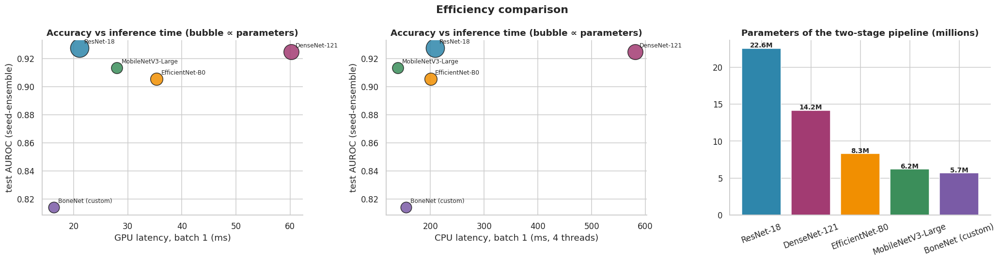

In [40]:
from torch.utils.flop_counter import FlopCounterMode
@torch.no_grad()
def lat(fn, repeats, warm, sync):
    for _ in range(warm): fn()
    if sync: torch.cuda.synchronize()
    ts = []
    for _ in range(repeats):
        t = time.perf_counter(); fn()
        if sync: torch.cuda.synchronize()
        ts.append((time.perf_counter() - t) * 1000)
    return np.array(ts)
summ_ = lambda a: dict(mean=a.mean(), sd=a.std(ddof=1) if len(a) > 1 else 0.0, median=float(np.median(a)), p95=float(np.percentile(a, 95)))
def macs(net, size):
    with FlopCounterMode(display=False) as fc: net(torch.randn(1, 3, size, size))
    return fc.get_total_flops() / 2e9
EFF = []; torch.set_num_threads(CPU_THREADS)
for name in ARCHS:
    n1, _ = build_model(name, pretrained=False); n2, _ = build_model(name, pretrained=False, loc=False); n1.eval(); n2.eval()
    p1, p2 = sum(p.numel() for p in n1.parameters()), sum(p.numel() for p in n2.parameters())
    row = dict(model=name, params_M=(p1 + p2) / 1e6, params_single_M=p1 / 1e6, size_MB_fp32=(p1 + p2) * 4 / 1e6)
    c1, c2 = copy.deepcopy(n1).cpu().eval(), copy.deepcopy(n2).cpu().eval()
    try: row['GMACs'] = macs(c1, IMG_SIZE) + macs(c2, CROP_SIZE)
    except Exception: row['GMACs'] = np.nan
    hi1 = torch.randint(0, 256, (1, HIRES, HIRES), dtype=torch.uint8); hib = torch.randint(0, 256, (32, HIRES, HIRES), dtype=torch.uint8)
    if DEVICE.type == 'cuda':
        pg = Pipe(n1, n2, 0.5); row.update({f'gpu_b1_ms_{k}': v for k, v in summ_(lat(lambda: pg.run(hi1), TIMING['gpu_b1'], 20, True)).items()})
        torch.cuda.reset_peak_memory_stats(); b = lat(lambda: pg.run(hib, bs=32), TIMING['gpu_bs'], 3, True)
        row['gpu_throughput_img_s_bs32'] = 32 / (b.mean() / 1000); row['gpu_peak_mem_GB_bs32'] = torch.cuda.max_memory_allocated() / 2**30; del pg
    pc_ = Pipe(c1, c2, 0.5, device=torch.device('cpu'))
    row.update({f'cpu_b1_ms_{k}': v for k, v in summ_(lat(lambda: pc_.run(hi1), TIMING['cpu_b1'], 3, False)).items()})
    row['cpu_throughput_img_s_bs8'] = 8 / (lat(lambda: pc_.run(hib[:8], bs=8), TIMING['cpu_bs'], 1, False).mean() / 1000); EFF.append(row)
    del n1, n2, c1, c2, pc_
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
eff_df = pd.DataFrame(EFF).set_index('model')
eff_df = eff_df.join(pd.DataFrame([dict(model=r['model'], train_min=r['train_time_s'] / 60, sec_per_epoch=r['train_time_s'] / (r['epochs_run'] + r['epochs_run2'])) for n in ARCHS for r in MODEL_RUNS[n]]).groupby('model').mean())
eff_df.round(3).to_csv(OUT / 'tables' / 'efficiency_and_training_cost.csv'); print(f'Timing: end-to-end two-stage pipeline (flip TTA {TTA}), FP32, {HIRES}px source, {IMG_SIZE}px network input | GPU: {ENV_GPU} | CPU threads: {CPU_THREADS}'); display(eff_df.round(2))
fig, axes = plt.subplots(1, 3, figsize=(19, 5)); ci_i = ci_df.set_index('model')
xcols = [('gpu_b1_ms_mean', 'GPU latency, batch 1 (ms)'), ('cpu_b1_ms_mean', f'CPU latency, batch 1 (ms, {CPU_THREADS} threads)')]
for ax, (xc, xl) in zip(axes[:2], xcols):
    if xc not in eff_df: ax.axis('off'); ax.set_title('(no GPU in this session)'); continue
    for m_ in ARCHS:
        ax.scatter(eff_df.loc[m_, xc], ci_i.loc[nice(m_), 'auroc'], s=80 + 24 * eff_df.loc[m_, 'params_M'], color=MODEL_PAL[m_], edgecolor='k', alpha=.85); ax.annotate(nice(m_), (eff_df.loc[m_, xc], ci_i.loc[nice(m_), 'auroc']), xytext=(6, 6), textcoords='offset points', fontsize=8)
    ax.set(xlabel=xl, ylabel='test AUROC (seed-ensemble)', title='Accuracy vs inference time (bubble ∝ parameters)')
bars = axes[2].bar([nice(m_) for m_ in ARCHS], eff_df.loc[ARCHS, 'params_M'], color=[MODEL_PAL[m_] for m_ in ARCHS], edgecolor='white')
for b_, v in zip(bars, eff_df.loc[ARCHS, 'params_M']): axes[2].text(b_.get_x() + b_.get_width() / 2, v + .1, f'{v:.1f}M', ha='center', fontsize=9, fontweight='bold')
axes[2].set(title='Parameters of the two-stage pipeline (millions)'); axes[2].tick_params(axis='x', rotation=20); fig.suptitle('Efficiency comparison', fontweight='bold'); finish(fig, 'E05_efficiency')

## 8.5 · Pairwise comparison and threshold analysis

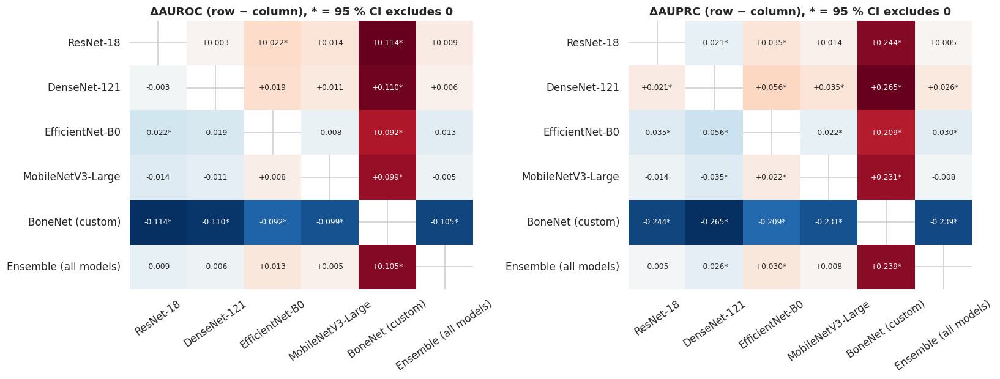

6 of 15 model pairs differ credibly in AUROC (95 % CI excludes 0). With many pairs, a CI that barely excludes 0 should be treated with caution; intervals cover test-case variation, not seed variation.


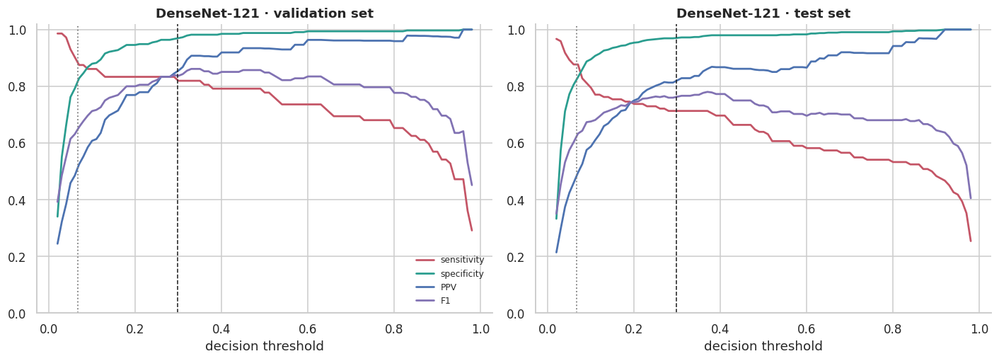

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, m in zip(axes, ['auroc', 'auprc']):
    M = np.full((len(KEYS), len(KEYS)), np.nan); A = np.empty((len(KEYS), len(KEYS)), dtype=object); A[:] = ''
    for i, a_ in enumerate(KEYS):
        for j, b_ in enumerate(KEYS):
            if i == j: continue
            r = pw_df[(pw_df.model_a == nice(a_)) & (pw_df.model_b == nice(b_)) & (pw_df.metric == m)].iloc[0]; M[i, j] = r['diff']; A[i, j] = f'{r["diff"]:+.3f}' + ('*' if r.excludes_zero else '')
    sns.heatmap(M, annot=A, fmt='', cmap='RdBu_r', center=0, cbar=False, xticklabels=[nice(k) for k in KEYS], yticklabels=[nice(k) for k in KEYS], ax=ax, annot_kws={'fontsize': 8}); ax.set_title(f'Δ{m.upper()} (row − column), * = 95 % CI excludes 0'); ax.tick_params(axis='x', rotation=35)
finish(fig, 'E06_pairwise_differences')
n_sig = int(pw_df[pw_df.metric == 'auroc'].excludes_zero.sum() // 2); n_pairs = len(KEYS) * (len(KEYS) - 1) // 2
print(f'{n_sig} of {n_pairs} model pairs differ credibly in AUROC (95 % CI excludes 0). With many pairs, a CI that barely excludes 0 should be treated with caution; intervals cover test-case variation, not seed variation.')

pb_v, pb_t = ens[BEST]['val'], ens[BEST]['test']; ts_ = np.linspace(0.02, 0.98, 97); fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (y_, p_, nm) in zip(axes, [(yv, pb_v, 'validation'), (yt, pb_t, 'test')]):
    mt = pd.DataFrame([full_metrics(y_, p_, t) for t in ts_])
    for c, lab, col in [('sensitivity', 'sensitivity', '#C45566'), ('specificity', 'specificity', '#2A9D8F'), ('ppv', 'PPV', '#4C72B0'), ('f1', 'F1', '#8172B3')]: ax.plot(ts_, mt[c], label=lab, color=col, lw=1.8)
    ax.axvline(thr[BEST]['main'], color='k', ls='--', lw=1); ax.axvline(thr[BEST]['sens90'], color='gray', ls=':', lw=1.2); ax.set(title=f'{nice(BEST)} · {nm} set', xlabel='decision threshold', ylim=(0, 1.02))
axes[0].legend(frameon=False, fontsize=8); finish(fig, 'E07_threshold_analysis_best_model')

## 8.6 · Hardware-free evaluation

Test images with hardware: 16 (16 fractured; all fractured = True) | without hardware: 755 (106 fractured, 649 healthy)


Cluster bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

TABLE 4 · test set WITHOUT hardware images (n=755) vs all test images · validation thresholds · 95 % family-bootstrap CI


,AUROC (all test),AUROC (no hardware),AUPRC (all),AUPRC (no hardware),Sens (all),Sens (no hardware),Spec (no hardware),Sens (hardware only)
model,,,,,,,,
ResNet-18,0.928,0.917 (0.888–0.944),0.808,0.760 (0.678–0.824),0.664,0.613 (0.510–0.704),0.971,1.000
DenseNet-121,0.925,0.914 (0.878–0.944),0.829,0.787 (0.711–0.848),0.713,0.670 (0.577–0.753),0.971,1.000
EfficientNet-B0,0.906,0.892 (0.855–0.921),0.772,0.717 (0.635–0.786),0.631,0.575 (0.474–0.664),0.965,1.000
MobileNetV3-Large,0.914,0.902 (0.865–0.933),0.794,0.749 (0.672–0.813),0.598,0.547 (0.447–0.635),0.983,0.938
BoneNet (custom),0.814,0.804 (0.754–0.853),0.563,0.523 (0.429–0.618),0.762,0.755 (0.660–0.840),0.753,0.812
Ensemble (all models),0.919,0.907 (0.872–0.937),0.802,0.754 (0.675–0.822),0.705,0.660 (0.563–0.743),0.957,1.000


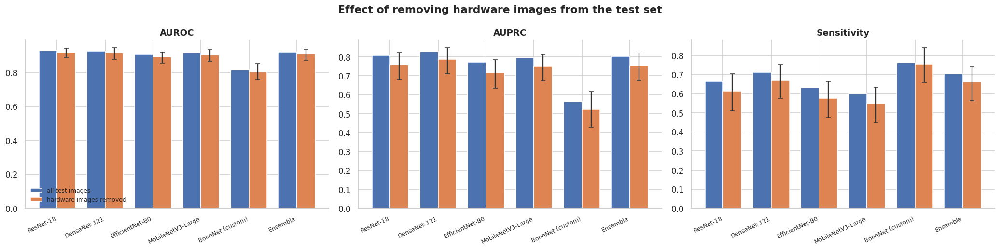

Mean AUROC change when hardware images are removed: -0.012; mean sensitivity change: -0.042 (a large sensitivity drop means hardware cases were easy credit). Report the hardware-free column as the primary fracture-detection estimate.


In [42]:
th = parts['test']; hw_df = None
if 'hardware' not in th or th.hardware.isna().all():
    print('No hardware metadata in the manifest; skipped.')
else:
    hw = th.hardware.eq('yes').fillna(False).to_numpy(dtype=bool); nh = ~hw
    print(f'Test images with hardware: {int(hw.sum())} ({int(yt[hw].sum())} fractured; all fractured = {bool(yt[hw].all()) if hw.any() else "n/a"}) | without hardware: {int(nh.sum())} ({int(yt[nh].sum())} fractured, {int((yt[nh] == 0).sum())} healthy)')
    assert len(np.unique(yt[nh])) == 2, 'the hardware-free test subset needs both classes'
    boot_nh = cluster_bootstrap(yt[nh], {k: ens[k]['test'][nh] for k in KEYS}, gt[nh], thr_main, N_BOOT)
    rows = []
    for k in KEYS:
        pa = ens[k]['test']; m_all = full_metrics(yt, pa, thr_main[k]); m_nh = full_metrics(yt[nh], pa[nh], thr_main[k]); r = dict(model=nice(k))
        for m in ['auroc', 'auprc', 'sensitivity', 'specificity', 'f1']:
            lo, hi = ci95(boot_nh[k][m]); r.update({f'{m}_all': m_all[m], f'{m}_nohw': m_nh[m], f'{m}_nohw_lo': lo, f'{m}_nohw_hi': hi})
        r['sensitivity_hardware_only'] = float((pa[hw] >= thr_main[k]).mean()) if hw.any() else np.nan; rows.append(r)
    hw_df = pd.DataFrame(rows); hw_df.round(4).to_csv(OUT / 'tables' / 'table4_hardware_free.csv', index=False)
    hw_fmt = pd.DataFrame({'AUROC (all test)': [f'{v:.3f}' for v in hw_df.auroc_all], 'AUROC (no hardware)': [f'{r.auroc_nohw:.3f} ({r.auroc_nohw_lo:.3f}–{r.auroc_nohw_hi:.3f})' for r in hw_df.itertuples()],
                           'AUPRC (all)': [f'{v:.3f}' for v in hw_df.auprc_all], 'AUPRC (no hardware)': [f'{r.auprc_nohw:.3f} ({r.auprc_nohw_lo:.3f}–{r.auprc_nohw_hi:.3f})' for r in hw_df.itertuples()],
                           'Sens (all)': [f'{v:.3f}' for v in hw_df.sensitivity_all], 'Sens (no hardware)': [f'{r.sensitivity_nohw:.3f} ({r.sensitivity_nohw_lo:.3f}–{r.sensitivity_nohw_hi:.3f})' for r in hw_df.itertuples()],
                           'Spec (no hardware)': [f'{r.specificity_nohw:.3f}' for r in hw_df.itertuples()], 'Sens (hardware only)': [f'{v:.3f}' for v in hw_df.sensitivity_hardware_only]}, index=hw_df.model)
    print(f'TABLE 4 · test set WITHOUT hardware images (n={int(nh.sum())}) vs all test images · validation thresholds · 95 % family-bootstrap CI'); display(hw_fmt)
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.8)); xx = np.arange(len(KEYS)); w = .38
    for ax, (m, lab) in zip(axes, [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('sensitivity', 'Sensitivity')]):
        ax.bar(xx - w / 2, hw_df[f'{m}_all'], w, label='all test images', color='#4C72B0')
        v = hw_df[f'{m}_nohw'].values; ax.bar(xx + w / 2, v, w, label='hardware images removed', color='#DD8452', yerr=errbars(v, hw_df[f'{m}_nohw_lo'].values, hw_df[f'{m}_nohw_hi'].values), capsize=3, ecolor='#333')
        ax.set_xticks(xx); ax.set_xticklabels([nice(k).replace('Ensemble (all models)', 'Ensemble') for k in KEYS], rotation=25, ha='right', fontsize=8); ax.set_title(lab)
    axes[0].legend(frameon=False, fontsize=8); fig.suptitle('Effect of removing hardware images from the test set', fontweight='bold'); finish(fig, 'E08_hardware_free_evaluation')
    drop = (hw_df.auroc_all - hw_df.auroc_nohw).mean(); print(f'Mean AUROC change when hardware images are removed: {-drop:+.3f}; mean sensitivity change: {(hw_df.sensitivity_nohw - hw_df.sensitivity_all).mean():+.3f} '
                                                          '(a large sensitivity drop means hardware cases were easy credit). Report the hardware-free column as the primary fracture-detection estimate.')
def hw_val(n, col='auroc_nohw'):
    return f'{hw_df.set_index("model").loc[nice(n), col]:.3f}' if hw_df is not None else 'n/a'

# Section 9: Error Analysis & Explainability

## 9.1 · Calibration · confidence distribution · subgroups

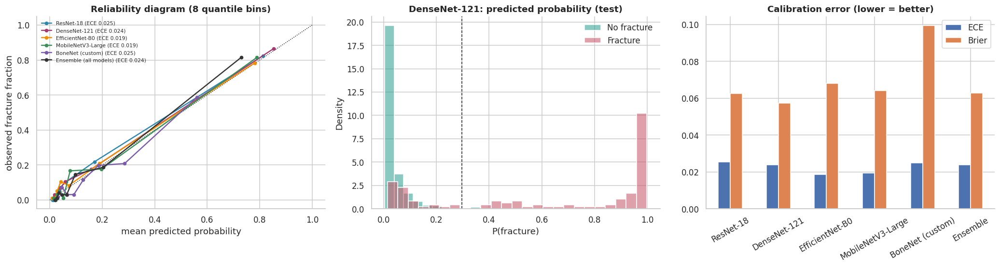

Subgroup performance · DenseNet-121 · test set


,variable,level,n,fractured,healthy,auroc,sensitivity,sens_lo,sens_hi,specificity,spec_lo,spec_hi,reliable
0,body_region,hand,251,61,190,0.915,0.721,0.598,0.818,0.942,0.899,0.967,True
1,body_region,hip,44,2,42,NaN,1.000,0.342,1.000,1.000,0.916,1.000,False
2,body_region,leg,379,37,342,0.903,0.730,0.570,0.846,0.994,0.979,0.998,True
3,body_region,mixed,73,20,53,0.858,0.650,0.433,0.819,0.887,0.774,0.947,True
4,body_region,shoulder,24,2,22,NaN,0.500,0.095,0.905,1.000,0.851,1.000,False
5,view,frontal,435,66,369,0.953,0.742,0.626,0.833,0.986,0.969,0.994,True
6,view,frontal+lateral,48,10,38,0.926,0.800,0.490,0.943,0.895,0.759,0.958,True
7,view,frontal+oblique,3,1,2,NaN,1.000,0.207,1.000,0.500,0.095,0.905,False
8,view,lateral,210,36,174,0.908,0.694,0.531,0.820,0.954,0.912,0.977,True
9,view,lateral+oblique,5,2,3,NaN,1.000,0.342,1.000,1.000,0.438,1.000,False


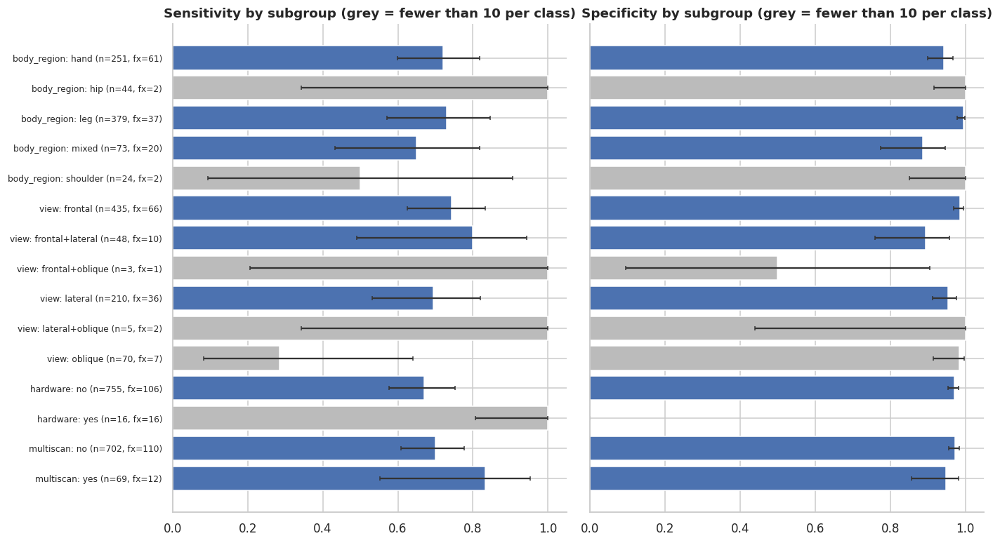

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2)); axes[0].plot([0, 1], [0, 1], 'k:', lw=1)
for k in KEYS:
    fr, mp = calibration_curve(yt, ens[k]['test'], n_bins=8, strategy='quantile'); axes[0].plot(mp, fr, 'o-', color=PAL[k], ms=4, lw=1.6, label=f'{nice(k)} (ECE {ece_score(yt, ens[k]["test"]):.3f})')
axes[0].set(xlabel='mean predicted probability', ylabel='observed fracture fraction', title='Reliability diagram (8 quantile bins)'); axes[0].legend(frameon=False, fontsize=7)
for c, col in [(0, '#2A9D8F'), (1, '#C45566')]: sns.histplot(ens[BEST]['test'][yt == c], bins=25, stat='density', color=col, alpha=.55, label=['No fracture', 'Fracture'][c], ax=axes[1])
axes[1].axvline(thr[BEST]['main'], color='k', ls='--', lw=1); axes[1].set(title=f'{nice(BEST)}: predicted probability (test)', xlabel='P(fracture)'); axes[1].legend(frameon=False)
cal = pd.DataFrame({'ECE': [ece_score(yt, ens[k]['test']) for k in KEYS], 'Brier': [brier_score_loss(yt, ens[k]['test']) for k in KEYS]}, index=[nice(k).replace('Ensemble (all models)', 'Ensemble') for k in KEYS])
cal.plot.bar(ax=axes[2], rot=30, color=['#4C72B0', '#DD8452']); axes[2].set(title='Calibration error (lower = better)'); finish(fig, 'X01_calibration_and_confidence')

te = parts['test'].copy(); te['p'] = ens[BEST]['test']; t_b = thr[BEST]['main']; rows = []
for var in ['body_region', 'view', 'hardware', 'multiscan']:
    if var not in te or te[var].isna().all(): continue
    for lvl, g in te.dropna(subset=[var]).groupby(var):
        y_, p_ = g.label.values, g.p.values; pos, neg = int(y_.sum()), int((y_ == 0).sum()); tp = int(((p_ >= t_b) & (y_ == 1)).sum()); tn = int(((p_ < t_b) & (y_ == 0)).sum()); sl, sh = wilson(tp, pos); pl, ph_ = wilson(tn, neg)
        rows.append(dict(variable=var, level=str(lvl), n=len(g), fractured=pos, healthy=neg, auroc=safe_auc(y_, p_) if min(pos, neg) >= 3 else np.nan, sensitivity=tp / pos if pos else np.nan, sens_lo=sl, sens_hi=sh,
                         specificity=tn / neg if neg else np.nan, spec_lo=pl, spec_hi=ph_, reliable=(pos >= 10 and neg >= 10)))
sub_df = pd.DataFrame(rows); sub_df.round(4).to_csv(OUT / 'tables' / 'subgroups_best_model.csv', index=False); print(f'Subgroup performance · {nice(BEST)} · test set'); display(sub_df.round(3))
if len(sub_df):
    fig, axes = plt.subplots(1, 2, figsize=(13, max(3.5, .38 * len(sub_df) + 1.5))); lab = [f'{r.variable}: {r.level} (n={r.n}, fx={r.fractured})' for r in sub_df.itertuples()]; yy = np.arange(len(sub_df))[::-1]
    for ax, (c, lo, hi, ttl) in zip(axes, [('sensitivity', 'sens_lo', 'sens_hi', 'Sensitivity'), ('specificity', 'spec_lo', 'spec_hi', 'Specificity')]):
        v = sub_df[c].values; ax.barh(yy, np.nan_to_num(v), color=['#4C72B0' if r else '#BBBBBB' for r in sub_df.reliable], xerr=errbars(v, sub_df[lo].values, sub_df[hi].values), capsize=2, ecolor='#333')
        ax.set_yticks(yy); ax.set_yticklabels(lab if c == 'sensitivity' else [''] * len(lab), fontsize=8); ax.set_xlim(0, 1.05); ax.set_title(f'{ttl} by subgroup (grey = fewer than 10 per class)')
    finish(fig, 'X02_subgroup_performance')

## 9.2 · Error cases · high-confidence errors · Grad-CAM

{'correct': 717, 'false negative': 35, 'false positive': 19}
High-confidence errors (confidence > 70 %): 41


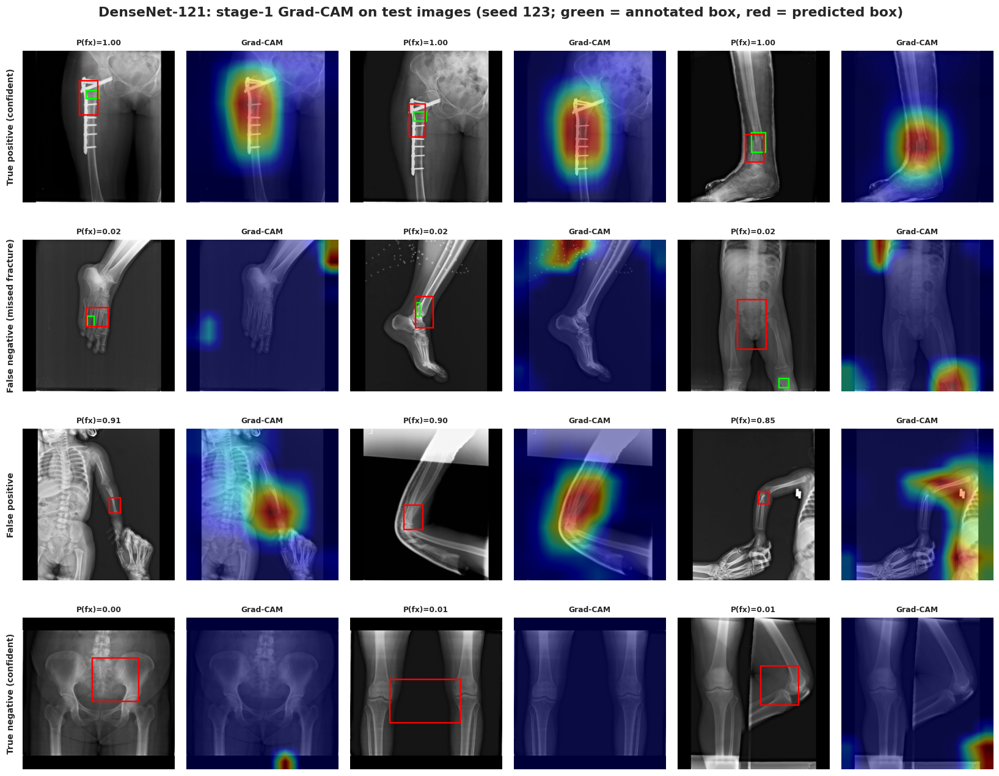

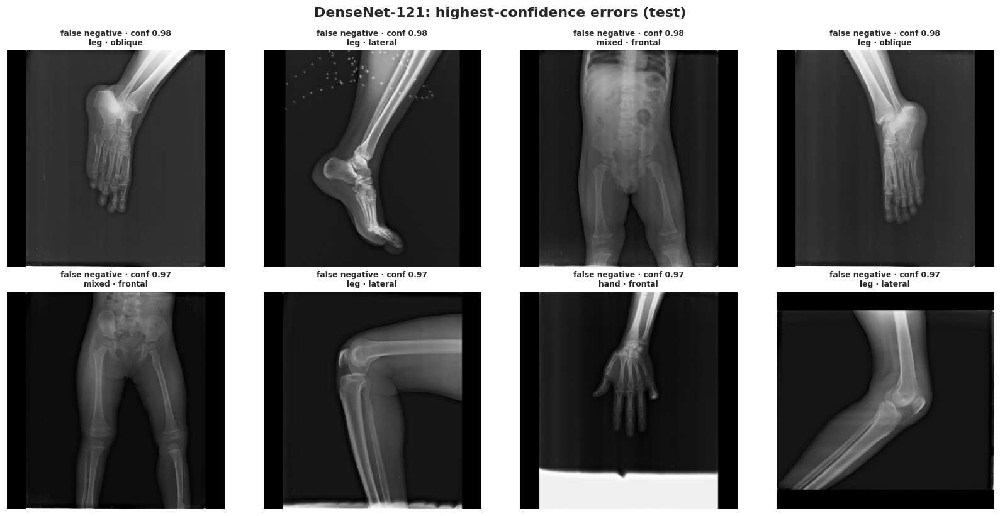

In [44]:
te['pred'] = (te.p >= t_b).astype(int); te['error'] = np.where((te.label == 1) & (te.pred == 0), 'false negative', np.where((te.label == 0) & (te.pred == 1), 'false positive', 'correct'))
te['confidence'] = np.where(te.pred == 1, te.p, 1 - te.p)
te.loc[te.error != 'correct', ['path', 'label', 'p', 'confidence', 'error'] + [c for c in ['body_region', 'view', 'hardware'] if c in te]].sort_values(['error', 'confidence'], ascending=[True, False]).to_csv(OUT / 'tables' / 'error_cases_best_model.csv', index=False)
print(te.error.value_counts().to_dict()); hard = te[(te.error != 'correct') & (te.confidence > 0.7)].sort_values('confidence', ascending=False); print(f'High-confidence errors (confidence > 70 %): {len(hard)}')

def grad_cam(model, x, layer):
    store = {}
    def fh(m, i, o): store['a'] = o; o.register_hook(lambda g_: store.__setitem__('g', g_))
    h = layer.register_forward_hook(fh); model.eval(); model.zero_grad(set_to_none=True); out = model.cls(x.to(DEVICE)); out.sum().backward(); h.remove()
    w = store['g'].mean((2, 3), keepdim=True); cam = F.relu((w * store['a']).sum(1, keepdim=True)); cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0].detach().cpu()
    mn_, mx_ = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True); return ((cam - mn_) / (mx_ - mn_ + 1e-8)).numpy()

best_run = max(MODEL_RUNS[BEST], key=lambda r: safe_ap(yv, r['p_val']))
pipe_b = load_pipe(best_run); mdl = pipe_b.n1; layer = cam_target(mdl, BEST); box_of = dict(zip(parts['test'].path, bx_te))
sel = {'True positive (confident)': te[(te.label == 1) & (te.pred == 1)].nlargest(3, 'p'), 'False negative (missed fracture)': te[te.error == 'false negative'].nsmallest(3, 'p'),
       'False positive': te[te.error == 'false positive'].nlargest(3, 'p'), 'True negative (confident)': te[(te.label == 0) & (te.pred == 0)].nsmallest(3, 'p')}
fig, axes = plt.subplots(len(sel), 6, figsize=(15, 2.9 * len(sel)), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ri, (title, d_) in enumerate(sel.items()):
    for c_, (_, r) in enumerate(d_.iterrows()):
        u8 = IMGS[r.path][None]; cam = grad_cam(mdl, to_input(u8), layer); img = IMGS[r.path].numpy(); a1, a2 = axes[ri, 2 * c_], axes[ri, 2 * c_ + 1]
        pb = pipe_b.run([r.path])['box'][0]
        a1.imshow(img, cmap='gray'); a2.imshow(img, cmap='gray'); a2.imshow(cam[0], cmap='jet', alpha=.45)
        draw_box(a1, box_of[r.path], IMG_SIZE, 'lime'); draw_box(a1, pb, IMG_SIZE, 'red'); a1.set_title(f'P(fx)={r.p:.2f}', fontsize=8); a2.set_title('Grad-CAM', fontsize=8)
    axes[ri, 0].text(-0.05, 0.5, title, transform=axes[ri, 0].transAxes, rotation=90, va='center', ha='right', fontsize=9, fontweight='bold')
fig.suptitle(f'{nice(BEST)}: stage-1 Grad-CAM on test images (seed {best_run["seed"]}; green = annotated box, red = predicted box)', y=1.0, fontweight='bold'); finish(fig, 'X03_gradcam_best_model', svg=False)
if len(hard):
    sh = hard.head(8); fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
    for ax in axes.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axes.ravel(), sh.iterrows()):
        ax.imshow(IMGS[r.path].numpy(), cmap='gray'); ax.set_title(f'{r.error} · conf {r.confidence:.2f}\n{r.get("body_region", "")} · {r.get("view", "")}', fontsize=8)
    fig.suptitle(f'{nice(BEST)}: highest-confidence errors (test)', fontweight='bold'); finish(fig, 'X04_high_confidence_errors', svg=False)
del mdl, pipe_b

# Section 10: Localization and Two-Stage Pipeline Analysis

## 10.1 · Stage-1 localization quality

Stage-1 localization on 122 annotated test fractures (mean ± SD over 3 seed(s))


,iou_mean,iou_median,iou_ge_0p5,centre_in_box,crop_covers_box_mean,crop_covers_90pct
ResNet-18,0.202 ± 0.007,0.138 ± 0.020,0.104 ± 0.033,0.410 ± 0.030,0.868 ± 0.018,0.798 ± 0.017
DenseNet-121,0.245 ± 0.009,0.180 ± 0.009,0.169 ± 0.037,0.481 ± 0.009,0.876 ± 0.020,0.790 ± 0.019
EfficientNet-B0,0.201 ± 0.009,0.156 ± 0.008,0.090 ± 0.014,0.429 ± 0.017,0.882 ± 0.012,0.803 ± 0.008
MobileNetV3-Large,0.204 ± 0.003,0.121 ± 0.012,0.098 ± 0.016,0.402 ± 0.022,0.866 ± 0.017,0.770 ± 0.016
BoneNet (custom),0.119 ± 0.003,0.061 ± 0.004,0.022 ± 0.005,0.227 ± 0.013,0.881 ± 0.003,0.850 ± 0.005


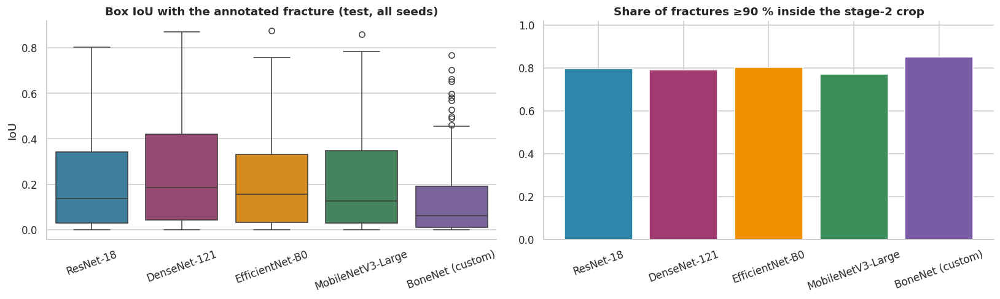

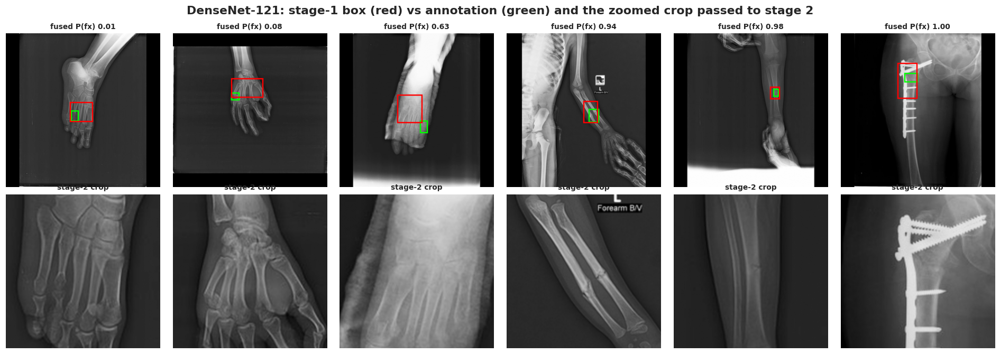

In [45]:
has_gt = np.isfinite(bx_te).all(1) & (yt == 1); gbx = bx_te[has_gt]; rows = []
for name in ARCHS:
    for r in MODEL_RUNS[name]:
        pb = r['box_test'][has_gt]; iou = box_iou_np(pb, gbx)
        cx, cy, side = crop_geom(torch.from_numpy(pb)); cx, cy, side = cx.numpy(), cy.numpy(), side.numpy()
        iw = np.clip(np.minimum(gbx[:, 0] + gbx[:, 2] / 2, cx + side / 2) - np.maximum(gbx[:, 0] - gbx[:, 2] / 2, cx - side / 2), 0, None)
        ih = np.clip(np.minimum(gbx[:, 1] + gbx[:, 3] / 2, cy + side / 2) - np.maximum(gbx[:, 1] - gbx[:, 3] / 2, cy - side / 2), 0, None)
        cover = iw * ih / (gbx[:, 2] * gbx[:, 3])
        inside = (np.abs(pb[:, 0] - gbx[:, 0]) <= gbx[:, 2] / 2) & (np.abs(pb[:, 1] - gbx[:, 1]) <= gbx[:, 3] / 2)
        rows.append(dict(model=name, seed=r['seed'], iou_mean=float(iou.mean()), iou_median=float(np.median(iou)), iou_ge_0p5=float((iou >= 0.5).mean()),
                         centre_in_box=float(inside.mean()), crop_covers_box_mean=float(cover.mean()), crop_covers_90pct=float((cover >= 0.9).mean())))
        r['_iou'] = iou
loc_df = pd.DataFrame(rows); loc_df.round(4).to_csv(OUT / 'tables' / 'localization_per_seed.csv', index=False)
cols = ['iou_mean', 'iou_median', 'iou_ge_0p5', 'centre_in_box', 'crop_covers_box_mean', 'crop_covers_90pct']
g_ = loc_df.groupby('model')[cols]; mn, sd = g_.mean().reindex(ARCHS), g_.std().reindex(ARCHS)
loc_tab = pd.DataFrame({c: [f'{mn.loc[m, c]:.3f} ± {sd.loc[m, c]:.3f}' if len(SEEDS) > 1 else f'{mn.loc[m, c]:.3f}' for m in ARCHS] for c in cols}, index=[nice(m) for m in ARCHS])
loc_tab.to_csv(OUT / 'tables' / 'localization_summary.csv')
print(f'Stage-1 localization on {int(has_gt.sum())} annotated test fractures (mean ± SD over {len(SEEDS)} seed(s))'); display(loc_tab)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
dist = pd.DataFrame([dict(model=nice(n), iou=v) for n in ARCHS for r in MODEL_RUNS[n] for v in r['_iou']])
sns.boxplot(data=dist, x='model', y='iou', order=[nice(n) for n in ARCHS], hue='model', palette={nice(n): MODEL_PAL[n] for n in ARCHS}, legend=False, ax=axes[0]); axes[0].set(title='Box IoU with the annotated fracture (test, all seeds)', xlabel='', ylabel='IoU'); axes[0].tick_params(axis='x', rotation=20)
cv = loc_df.groupby('model').crop_covers_90pct.mean().reindex(ARCHS)
axes[1].bar([nice(n) for n in ARCHS], cv.values, color=[MODEL_PAL[n] for n in ARCHS]); axes[1].set(title='Share of fractures ≥90 % inside the stage-2 crop', ylim=(0, 1.02)); axes[1].tick_params(axis='x', rotation=20)
finish(fig, 'L01_localization_quality')

best_run = max(MODEL_RUNS[BEST], key=lambda r: safe_ap(yv, r['p_val'])); pipe_b = load_pipe(best_run)
cases = parts['test'][has_gt].copy(); cases['gtbox'] = list(gbx); cases['p'] = ens[BEST]['test'][has_gt]; cases = cases.sort_values('p').iloc[np.linspace(0, len(cases) - 1, min(6, len(cases))).astype(int)]
res = pipe_b.run(list(cases.path)); bxs = torch.from_numpy(res['box']); cx, cy, side = crop_geom(bxs)
crops = sample_crops(torch.stack([IMGS_HI[p] for p in cases.path]).float().unsqueeze(1) / 255., cx, cy, side)
fig, axes = plt.subplots(2, len(cases), figsize=(2.9 * len(cases), 6.2), squeeze=False)
for j, (_, r) in enumerate(cases.iterrows()):
    axes[0, j].imshow(IMGS[r.path].numpy(), cmap='gray'); draw_box(axes[0, j], r['gtbox'], IMG_SIZE, 'lime'); draw_box(axes[0, j], res['box'][j], IMG_SIZE, 'red')
    axes[0, j].set_title(f'fused P(fx) {res["p"][j]:.2f}', fontsize=9); axes[1, j].imshow(crops[j, 0], cmap='gray', vmin=0, vmax=1); axes[1, j].set_title('stage-2 crop', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
fig.suptitle(f'{nice(BEST)}: stage-1 box (red) vs annotation (green) and the zoomed crop passed to stage 2', fontweight='bold'); finish(fig, 'L02_localization_examples', svg=False)
del pipe_b

## 10.2 · Full image vs zoomed crop vs fused

Cluster bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]

TABLE 10 · test set · full image only vs zoomed crop only vs fused (seed-ensembles, thresholds from validation, * = paired 95 % CI excludes 0)


,AUROC full image,AUROC crop only,AUROC fused,Δ AUROC fused − full,AUPRC full image,AUPRC crop only,AUPRC fused,Δ AUPRC fused − full,mean fusion weight on stage 1
model,,,,,,,,,
ResNet-18,0.898,0.914,0.928 (0.901–0.951),+0.029 (+0.005 to +0.055)*,0.770,0.791,0.808,+0.037 (-0.005 to +0.079),0.17
DenseNet-121,0.900,0.917,0.925 (0.891–0.953),+0.025 (-0.002 to +0.054),0.799,0.821,0.829,+0.029 (-0.003 to +0.063),0.20
EfficientNet-B0,0.899,0.888,0.906 (0.873–0.937),+0.007 (-0.010 to +0.026),0.763,0.749,0.772,+0.009 (-0.021 to +0.039),0.33
MobileNetV3-Large,0.907,0.890,0.914 (0.883–0.942),+0.007 (-0.007 to +0.021),0.776,0.768,0.794,+0.019 (-0.010 to +0.050),0.37
BoneNet (custom),0.819,0.710,0.814 (0.769–0.858),-0.005 (-0.009 to -0.000)*,0.570,0.422,0.563,-0.007 (-0.017 to +0.003),0.87


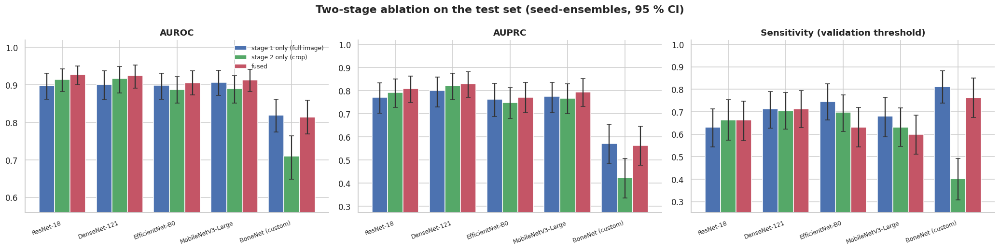

Fusion credibly improves AUROC over the full-image stage for: ResNet-18; credibly worse for: BoneNet (custom).


In [46]:
VAR = {'full': 'pf', 'crop': 'pc', 'fused': 'p'}
EV = {n: {v: {k: np.mean([r[f'{pre}_{k}'] for r in MODEL_RUNS[n]], 0) for k in ['val', 'test']} for v, pre in VAR.items()} for n in ARCHS}
Pb = {f'{n}|{v}': EV[n][v]['test'] for n in ARCHS for v in VAR}; Tb = {f'{n}|{v}': choose_threshold(yv, EV[n][v]['val']) for n in ARCHS for v in VAR}
bt = cluster_bootstrap(yt, Pb, gt, Tb, N_BOOT); rows = []
for n in ARCHS:
    row = dict(model=nice(n), alpha_mean=float(np.mean([r['alpha'] for r in MODEL_RUNS[n]])))
    for v in VAR:
        k = f'{n}|{v}'; full = full_metrics(yt, Pb[k], Tb[k])
        for m in ['auroc', 'auprc', 'sensitivity', 'specificity']: lo, hi = ci95(bt[k][m]); row.update({f'{m}_{v}': full[m], f'{m}_{v}_lo': lo, f'{m}_{v}_hi': hi})
    for m in ['auroc', 'auprc']:
        for other in ['full', 'crop']:
            d = bt[f'{n}|fused'][m] - bt[f'{n}|{other}'][m]; lo, hi = ci95(d); row.update({f'd_{m}_vs_{other}': float(d.mean()), f'd_{m}_vs_{other}_lo': lo, f'd_{m}_vs_{other}_hi': hi})
    rows.append(row)
abl = pd.DataFrame(rows); abl.round(4).to_csv(OUT / 'tables' / 'twostage_ablation.csv', index=False)
star = lambda r, m, o: '*' if (r[f'd_{m}_vs_{o}_lo'] > 0 or r[f'd_{m}_vs_{o}_hi'] < 0) else ''
abl_fmt = pd.DataFrame({'AUROC full image': [f'{r.auroc_full:.3f}' for r in abl.itertuples()], 'AUROC crop only': [f'{r.auroc_crop:.3f}' for r in abl.itertuples()],
                        'AUROC fused': [f'{r.auroc_fused:.3f} ({r.auroc_fused_lo:.3f}–{r.auroc_fused_hi:.3f})' for r in abl.itertuples()],
                        'Δ AUROC fused − full': [f'{r["d_auroc_vs_full"]:+.3f} ({r["d_auroc_vs_full_lo"]:+.3f} to {r["d_auroc_vs_full_hi"]:+.3f})' + star(r, 'auroc', 'full') for _, r in abl.iterrows()],
                        'AUPRC full image': [f'{r.auprc_full:.3f}' for r in abl.itertuples()], 'AUPRC crop only': [f'{r.auprc_crop:.3f}' for r in abl.itertuples()],
                        'AUPRC fused': [f'{r.auprc_fused:.3f}' for r in abl.itertuples()],
                        'Δ AUPRC fused − full': [f'{r["d_auprc_vs_full"]:+.3f} ({r["d_auprc_vs_full_lo"]:+.3f} to {r["d_auprc_vs_full_hi"]:+.3f})' + star(r, 'auprc', 'full') for _, r in abl.iterrows()],
                        'mean fusion weight on stage 1': [f'{v:.2f}' for v in abl.alpha_mean]}, index=abl.model)
abl_fmt.to_csv(OUT / 'tables' / 'twostage_ablation_formatted.csv')
print('TABLE 10 · test set · full image only vs zoomed crop only vs fused (seed-ensembles, thresholds from validation, * = paired 95 % CI excludes 0)'); display(abl_fmt)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8)); xx = np.arange(len(ARCHS)); w = .27
for ax, (m, lab) in zip(axes, [('auroc', 'AUROC'), ('auprc', 'AUPRC'), ('sensitivity', 'Sensitivity (validation threshold)')]):
    for j, (v, col, nm) in enumerate([('full', '#4C72B0', 'stage 1 only (full image)'), ('crop', '#55A868', 'stage 2 only (crop)'), ('fused', '#C45566', 'fused')]):
        vals = abl[f'{m}_{v}'].values; ax.bar(xx + (j - 1) * w, vals, w, label=nm, color=col, yerr=errbars(vals, abl[f'{m}_{v}_lo'].values, abl[f'{m}_{v}_hi'].values), capsize=3, ecolor='#333')
    ax.set_xticks(xx); ax.set_xticklabels([nice(n) for n in ARCHS], rotation=20, ha='right', fontsize=8); ax.set_title(lab); ax.set_ylim(max(0, min(abl[f'{m}_{v}'].min() for v in VAR) - .15), 1.02)
axes[0].legend(frameon=False, fontsize=8); fig.suptitle('Two-stage ablation on the test set (seed-ensembles, 95 % CI)', fontweight='bold'); finish(fig, 'L03_twostage_ablation')
better = [nice(n) for n, (_, r) in zip(ARCHS, abl.iterrows()) if r['d_auroc_vs_full_lo'] > 0]; worse = [nice(n) for n, (_, r) in zip(ARCHS, abl.iterrows()) if r['d_auroc_vs_full_hi'] < 0]
print(f'Fusion credibly improves AUROC over the full-image stage for: {", ".join(better) if better else "none"}; credibly worse for: {", ".join(worse) if worse else "none"}.')

# Section 11: Final Model Comparison · Which Model Is Better?

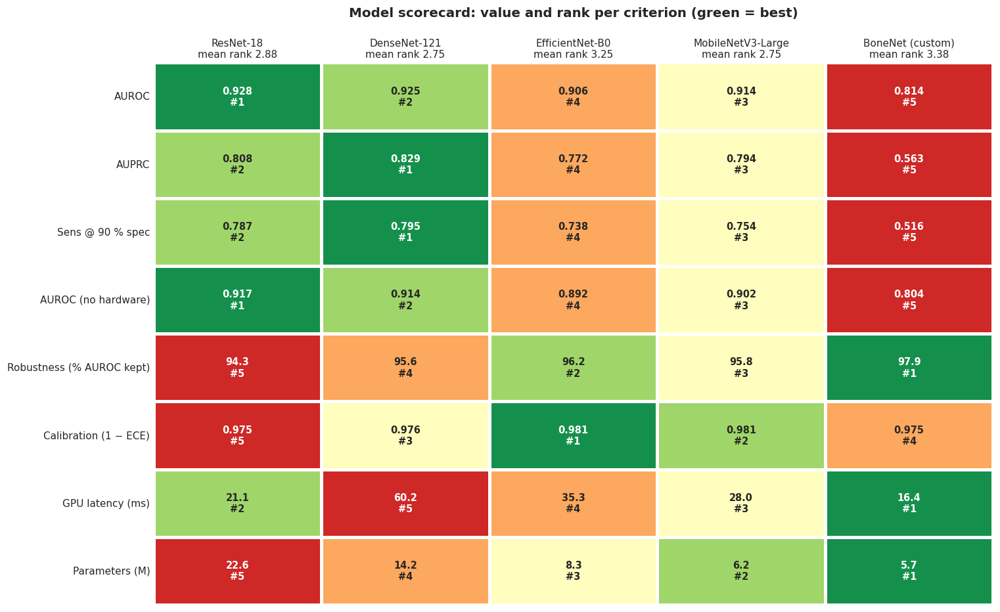

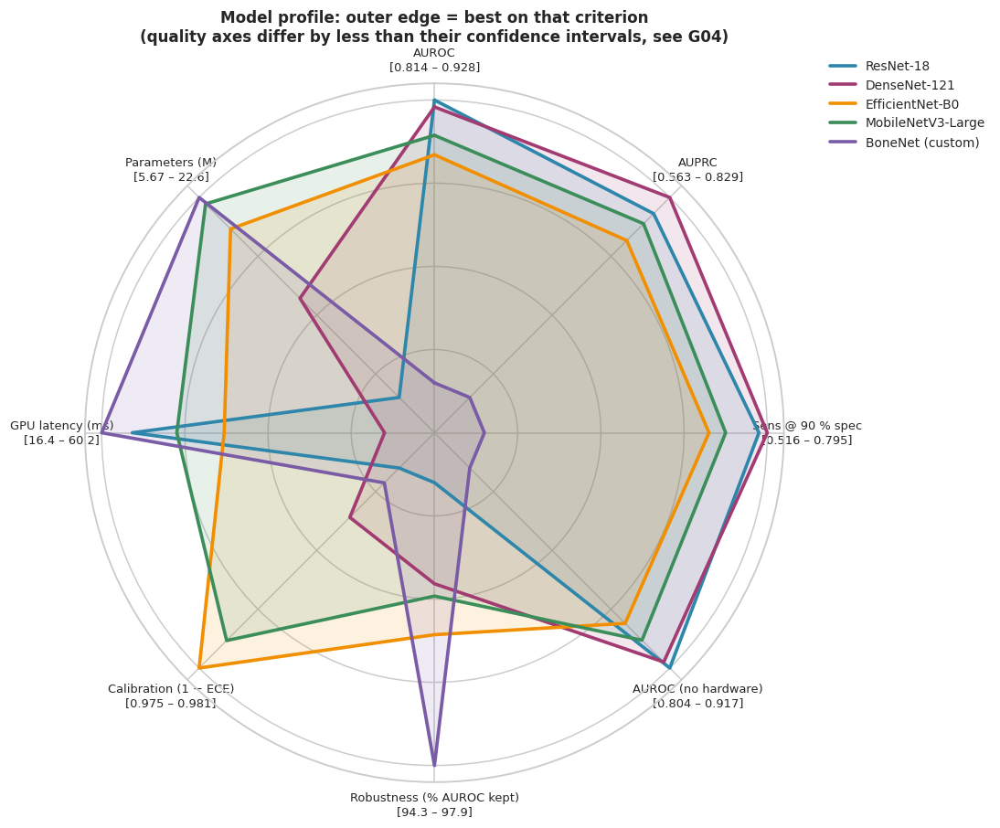

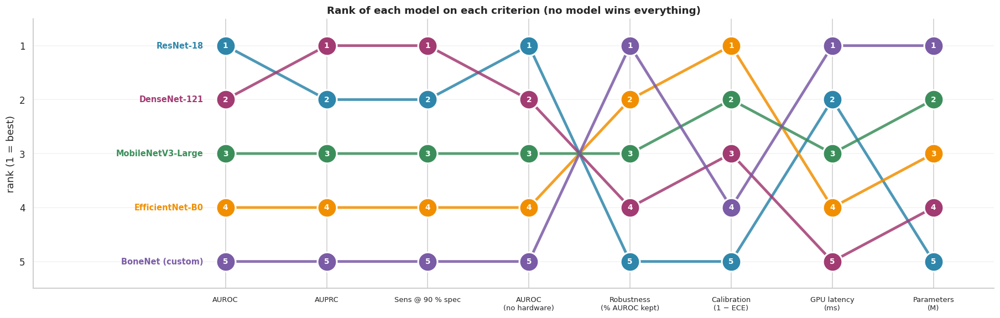

Mean rank (lower = better): {'ResNet-18': 2.88, 'DenseNet-121': 2.75, 'EfficientNet-B0': 3.25, 'MobileNetV3-Large': 2.75, 'BoneNet (custom)': 3.38}


In [47]:
def sens_at_spec(y, p, spec=0.90):
    fpr, tpr, _ = roc_curve(y, p); ok = np.where(1 - fpr >= spec)[0]; return float(tpr[ok].max()) if len(ok) else 0.0
lat_col = 'gpu_b1_ms_mean' if 'gpu_b1_ms_mean' in eff_df else 'cpu_b1_ms_mean'; LAT_NAME = 'GPU' if lat_col.startswith('gpu') else 'CPU'
hwd = hw_df.set_index('model') if ('hw_df' in globals() and hw_df is not None) else None
rows = {}
for n in ARCHS:
    p = ens[n]['test']
    rows[n] = {'AUROC': safe_auc(yt, p), 'AUPRC': safe_ap(yt, p), 'Sens @ 90 % spec': sens_at_spec(yt, p), 'AUROC (no hardware)': float(hwd.loc[nice(n), 'auroc_nohw']) if hwd is not None else safe_auc(yt, p),
               'Robustness (% AUROC kept)': float(summ.loc[nice(n), 'mean_retention_pct']), 'Calibration (1 − ECE)': 1 - ece_score(yt, p), f'{LAT_NAME} latency (ms)': float(eff_df.loc[n, lat_col]), 'Parameters (M)': float(eff_df.loc[n, 'params_M'])}
crit = pd.DataFrame(rows).T; LOWER = [f'{LAT_NAME} latency (ms)', 'Parameters (M)']; NM = len(ARCHS)
rank = pd.DataFrame({c: crit[c].rank(ascending=(c in LOWER), method='average') for c in crit}); mean_rank = rank.mean(axis=1)
crit.round(4).to_csv(OUT / 'tables' / 'final_scorecard_values.csv'); rank.to_csv(OUT / 'tables' / 'final_scorecard_ranks.csv')

score = ((NM - rank) / max(NM - 1, 1)).T; ann = np.array([[(f'{crit.loc[n, c]:.1f}' if c in LOWER or 'Robust' in c else f'{crit.loc[n, c]:.3f}') + f'\n#{rank.loc[n, c]:g}' for n in ARCHS] for c in crit.columns])
fig, ax = plt.subplots(figsize=(2.0 * NM + 4, 0.78 * len(crit.columns) + 2.4))
sns.heatmap(score, annot=ann, fmt='', cmap='RdYlGn', vmin=-.1, vmax=1.1, cbar=False, linewidths=3, linecolor='white', annot_kws={'fontsize': 9.5, 'fontweight': 'bold'}, ax=ax,
            xticklabels=[f'{nice(n)}\nmean rank {mean_rank[n]:.2f}' for n in ARCHS], yticklabels=list(crit.columns)); ax.xaxis.tick_top(); ax.tick_params(axis='both', length=0, labelsize=10)
ax.set_title('Model scorecard: value and rank per criterion (green = best)', fontsize=13, fontweight='bold', pad=46); finish(fig, 'G01_model_scorecard')

K = len(crit.columns); S = crit.copy()
for c in crit: v = crit[c].astype(float); s = (v - v.min()) / (v.max() - v.min() + 1e-12); S[c] = 0.15 + 0.85 * ((1 - s) if c in LOWER else s)
ang = np.linspace(0, 2 * np.pi, K, endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(9.6, 8.4)); ax = plt.subplot(111, polar=True); ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1)
for n in ARCHS:
    v = S.loc[n].tolist() + [S.loc[n].iloc[0]]; ax.plot(ang, v, lw=2.4, color=MODEL_PAL[n], label=nice(n)); ax.fill(ang, v, color=MODEL_PAL[n], alpha=.12)
ax.set_xticks(ang[:-1]); ax.set_xticklabels([f'{c}\n[{crit[c].min():.3g} – {crit[c].max():.3g}]' for c in crit.columns], fontsize=8.5); ax.set_yticks([.25, .5, .75, 1.0]); ax.set_yticklabels([]); ax.set_ylim(0, 1.05)
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1.05), frameon=False, fontsize=9); ax.set_title('Model profile: outer edge = best on that criterion\n(quality axes differ by less than their confidence intervals, see G04)', fontsize=11, fontweight='bold', pad=30)
finish(fig, 'G02_radar_profile')

fig, ax = plt.subplots(figsize=(1.7 * K + 3, 5.4)); xs = np.arange(K); first = rank.iloc[:, 0]; LBL_OFF = {}
for _rv, _grp in first.groupby(first):
    for _k, _n in enumerate(list(_grp.index)): LBL_OFF[_n] = (_k - (len(_grp) - 1) / 2) * 0.34
for n in ARCHS:
    ax.plot(xs, rank.loc[n].values, '-', lw=3.2, color=MODEL_PAL[n], alpha=.85); ax.scatter(xs, rank.loc[n].values, s=520, color=MODEL_PAL[n], edgecolor='white', linewidth=2, zorder=5)
    for x_, r_ in zip(xs, rank.loc[n].values): ax.text(x_, r_, f'{r_:g}', ha='center', va='center', color='white', fontsize=9, fontweight='bold', zorder=6)
    ax.text(xs[0] - 0.22, rank.loc[n].iloc[0] + LBL_OFF[n], nice(n), ha='right', va='center', fontsize=9.5, color=MODEL_PAL[n], fontweight='bold')
ax.set_xticks(xs); ax.set_xticklabels([c.replace(' (', '\n(') for c in crit.columns], fontsize=8.5); ax.set_ylim(NM + .5, .5); ax.set_yticks(range(1, NM + 1)); ax.set_ylabel('rank (1 = best)'); ax.set_xlim(-1.9, K - .4)
ax.grid(axis='y', alpha=.25); ax.set_title('Rank of each model on each criterion (no model wins everything)', fontweight='bold'); finish(fig, 'G03_rank_bump_chart')
print('Mean rank (lower = better):', {nice(n): round(float(mean_rank[n]), 2) for n in ARCHS})

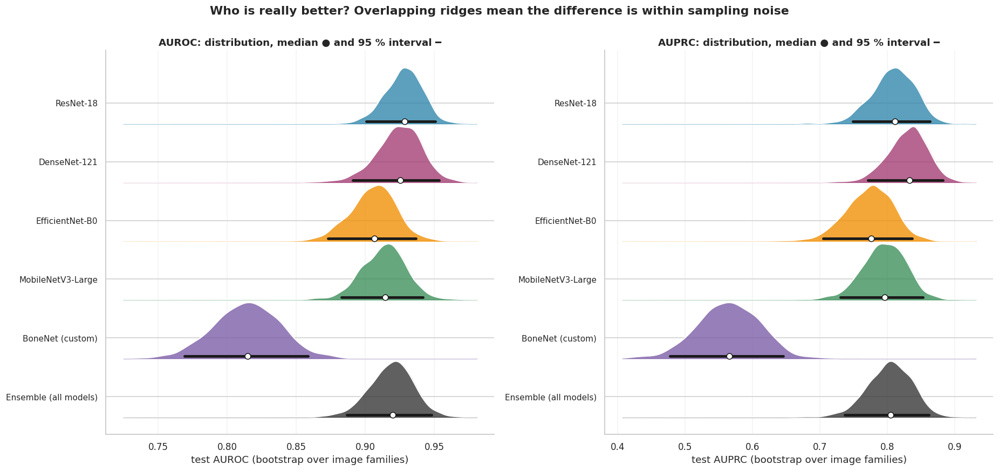

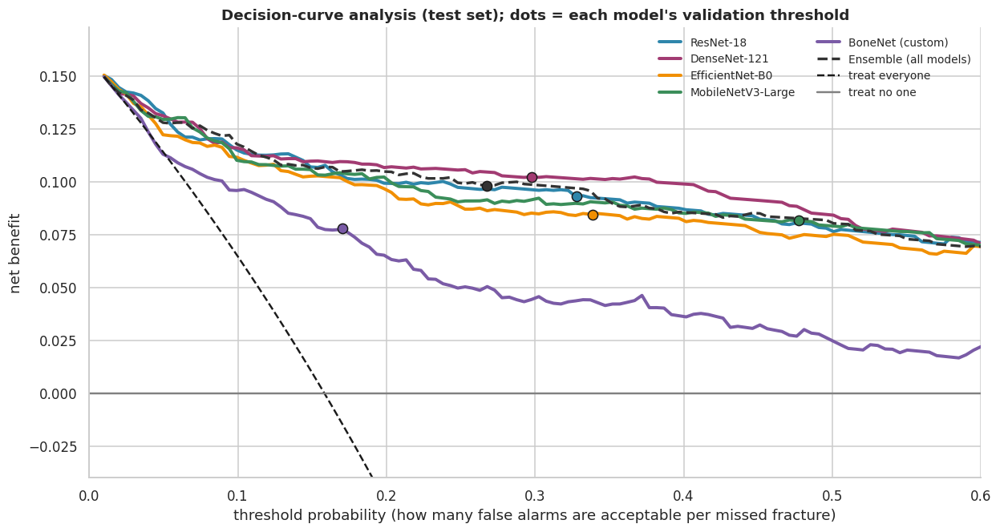

In [48]:
from scipy.stats import gaussian_kde
fig, axes = plt.subplots(1, 2, figsize=(17, 0.92 * len(KEYS) + 2.4))
for ax, (m, ttl) in zip(axes, [('auroc', 'AUROC'), ('auprc', 'AUPRC')]):
    allv = np.concatenate([boot[k][m] for k in KEYS]); xs = np.linspace(allv.min() - .01, min(1.0, allv.max() + .01), 400)
    for j, k in enumerate(KEYS[::-1]):
        v = boot[k][m]; off = float(j)
        if v.std() < 1e-6: ax.plot([v.mean()] * 2, [off, off + .8], color=PAL[k], lw=3)
        else:
            d = gaussian_kde(v)(xs); d = d / d.max() * .95; ax.fill_between(xs, off, off + d, color=PAL[k], alpha=.78, zorder=100 - j); ax.plot(xs, off + d, color='white', lw=1.4, zorder=100 - j)
        lo, hi = ci95(v); ax.plot([lo, hi], [off + .04] * 2, color='k', lw=3.2, zorder=200); ax.plot(np.median(v), off + .04, 'o', color='white', mec='k', ms=7, zorder=201)
    ax.set_yticks([j + .35 for j in range(len(KEYS))]); ax.set_yticklabels([nice(k) for k in KEYS[::-1]], fontsize=10); ax.set_xlabel(f'test {ttl} (bootstrap over image families)'); ax.set_title(f'{ttl}: distribution, median ● and 95 % interval ━'); ax.grid(axis='x', alpha=.25)
fig.suptitle('Who is really better? Overlapping ridges mean the difference is within sampling noise', fontweight='bold', y=1.0); finish(fig, 'G04_bootstrap_ridgelines')

pts = np.linspace(0.01, 0.60, 120); prev = yt.mean(); N_ = len(yt)
def net_benefit(p, t): pred = p >= t; return ((pred & (yt == 1)).sum() - (pred & (yt == 0)).sum() * t / (1 - t)) / N_
fig, ax = plt.subplots(figsize=(11.5, 6.2))
for k in KEYS:
    nb = np.array([net_benefit(ens[k]['test'], t) for t in pts]); ax.plot(pts, nb, lw=2.6 if k != 'ensemble_all' else 2.2, ls='-' if k != 'ensemble_all' else '--', color=PAL[k], label=nice(k))
    tt = thr_main[k]
    if pts[0] <= tt <= pts[-1]: ax.plot(tt, net_benefit(ens[k]['test'], tt), 'o', color=PAL[k], mec='k', ms=8, zorder=5)
ax.plot(pts, prev - (1 - prev) * pts / (1 - pts), 'k--', lw=1.6, label='treat everyone'); ax.axhline(0, color='gray', lw=1.6, label='treat no one')
ax.set_ylim(-0.04, prev + .015); ax.set_xlim(0, .6); ax.set(xlabel='threshold probability (how many false alarms are acceptable per missed fracture)', ylabel='net benefit', title='Decision-curve analysis (test set); dots = each model\'s validation threshold')
ax.legend(frameon=False, fontsize=9, ncol=2); finish(fig, 'G05_decision_curves')

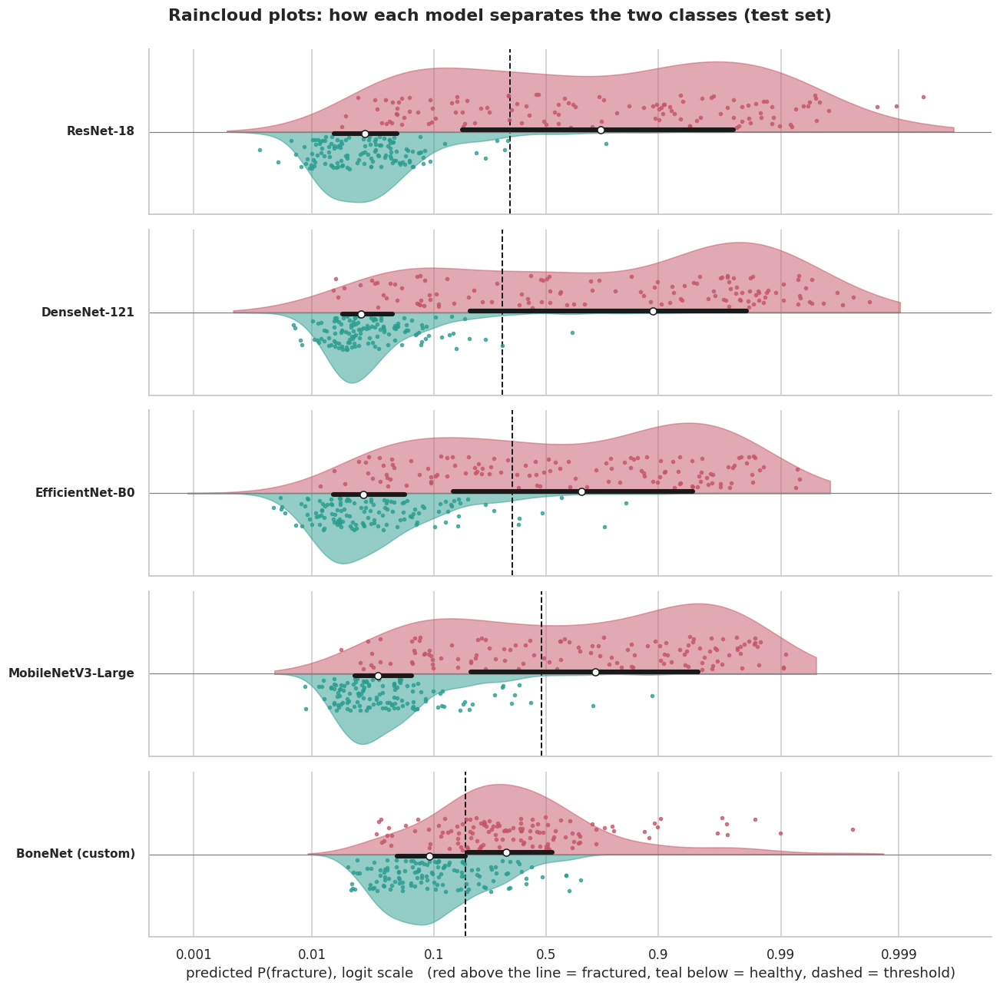

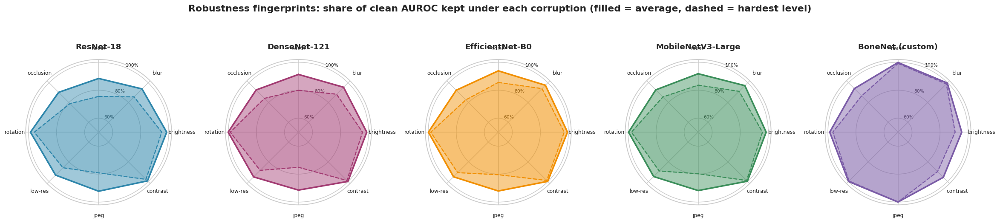

In [49]:
rng_ = np.random.default_rng(SEED); lg = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
fig, axes = plt.subplots(len(ARCHS), 1, figsize=(12, 2.35 * len(ARCHS)), sharex=True)
for ax, n in zip(np.atleast_1d(axes), ARCHS):
    z = lg(ens[n]['test']); xs = np.linspace(z.min() - .6, z.max() + .6, 300)
    for c, col, sg in [(0, '#2A9D8F', -1), (1, '#C45566', 1)]:
        zc = z[yt == c]
        if len(zc) > 2 and zc.std() > 1e-6: d = gaussian_kde(zc)(xs); d = d / d.max() * .85; ax.fill_between(xs, 0, sg * d, color=col, alpha=.5)
        pick = rng_.choice(zc, min(130, len(zc)), replace=False); ax.scatter(pick, sg * (.05 + rng_.uniform(0, .4, len(pick))), s=7, color=col, alpha=.75, zorder=4)
        q1, md, q3 = np.percentile(zc, [25, 50, 75]); ax.plot([q1, q3], [sg * .02] * 2, color='k', lw=4, zorder=6); ax.plot(md, sg * .02, 'o', color='white', mec='k', ms=6, zorder=7)
    ax.axvline(lg(np.array(thr_main[n])), color='k', ls='--', lw=1.3); ax.axhline(0, color='gray', lw=.8); ax.set_yticks([]); ax.set_ylabel(nice(n), rotation=0, ha='right', va='center', fontsize=10, fontweight='bold', labelpad=12); ax.set_ylim(-1, 1)
tk = np.array([.001, .01, .1, .5, .9, .99, .999]); np.atleast_1d(axes)[-1].set_xticks(lg(tk)); np.atleast_1d(axes)[-1].set_xticklabels([f'{t:g}' for t in tk]); np.atleast_1d(axes)[-1].set_xlabel('predicted P(fracture), logit scale   (red above the line = fractured, teal below = healthy, dashed = threshold)')
fig.suptitle('Raincloud plots: how each model separates the two classes (test set)', fontweight='bold', y=.995); finish(fig, 'G06_raincloud_probabilities')

cn = list(CORRUPTIONS); Kc = len(cn); angc = np.linspace(0, 2 * np.pi, Kc, endpoint=False).tolist(); angc += angc[:1]
fig, axes = plt.subplots(1, len(ARCHS), figsize=(4.3 * len(ARCHS), 4.9), subplot_kw=dict(polar=True))
for ax, n in zip(np.atleast_1d(axes), ARCHS):
    cl = rob[(rob.model == n) & rob.is_clean].auroc.iloc[0]
    mean_r = [rob[(rob.model == n) & (rob.kind == k) & ~rob.is_clean].auroc.mean() / cl for k in cn]; worst_r = [rob[(rob.model == n) & (rob.kind == k) & ~rob.is_clean].auroc.min() / cl for k in cn]
    ax.set_theta_offset(np.pi / 2); ax.set_theta_direction(-1); ax.fill(angc, worst_r + worst_r[:1], color=MODEL_PAL[n], alpha=.18); ax.plot(angc, worst_r + worst_r[:1], '--', color=MODEL_PAL[n], lw=1.6)
    ax.fill(angc, mean_r + mean_r[:1], color=MODEL_PAL[n], alpha=.45); ax.plot(angc, mean_r + mean_r[:1], color=MODEL_PAL[n], lw=2.4)
    ax.set_xticks(angc[:-1]); ax.set_xticklabels([c.replace('gaussian_', '').replace('low_resolution', 'low-res').replace('_', ' ') for c in cn], fontsize=8); ax.set_ylim(.5, 1.02); ax.set_yticks([.6, .8, 1.0]); ax.set_yticklabels(['60%', '80%', '100%'], fontsize=7); ax.set_title(nice(n), fontweight='bold', pad=16)
fig.suptitle('Robustness fingerprints: share of clean AUROC kept under each corruption (filled = average, dashed = hardest level)', fontweight='bold', y=1.02); finish(fig, 'G07_robustness_fingerprints')

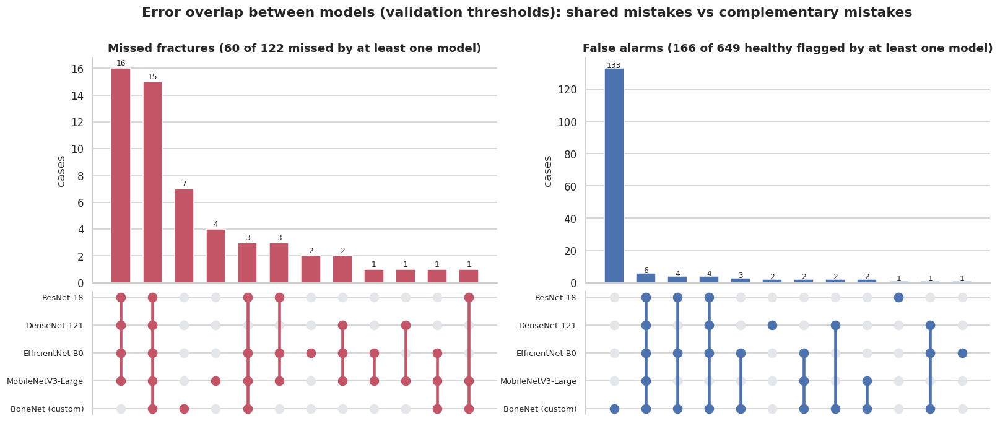

Fractures missed by ALL models: 15 | missed by at least one: 60 | missed by exactly one: 14 (an ensemble can recover these)


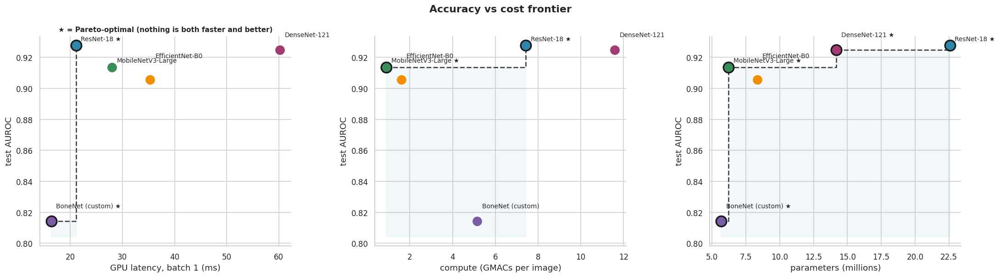

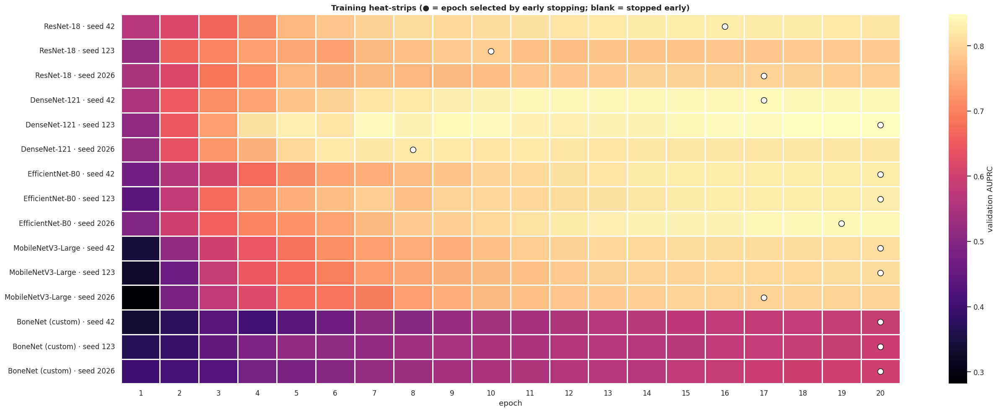

In [50]:
def upset(fig, spec_bar, spec_dot, miss, names, title, color, topn=12):
    from collections import Counter
    pat = Counter(tuple(bool(v) for v in miss[:, j]) for j in range(miss.shape[1])); items = sorted([(k, v) for k, v in pat.items() if any(k)], key=lambda t: -t[1])[:topn]
    axb, axd = fig.add_subplot(spec_bar), fig.add_subplot(spec_dot); xs = np.arange(len(items))
    if not items: axb.axis('off'); axd.axis('off'); axb.set_title(title + ' (none)'); return
    axb.bar(xs, [v for _, v in items], color=color, width=.62); [axb.text(x_, v + .2, str(v), ha='center', fontsize=8) for x_, (_, v) in zip(xs, items)]; axb.set_xticks([]); axb.set_ylabel('cases'); axb.set_title(title, fontweight='bold')
    for x_, (k, _) in zip(xs, items):
        ys = [i for i in range(len(names)) if k[i]]; axd.scatter([x_] * len(names), range(len(names)), s=85, color='#E3E6EA', zorder=2); axd.scatter([x_] * len(ys), ys, s=85, color=color, zorder=3)
        if len(ys) > 1: axd.plot([x_, x_], [min(ys), max(ys)], color=color, lw=3, zorder=2)
    axd.set_yticks(range(len(names))); axd.set_yticklabels(names, fontsize=8.5); axd.set_xticks([]); axd.set_xlim(axb.get_xlim()); axd.invert_yaxis(); axd.spines[['top', 'right', 'bottom']].set_visible(False)
pos_idx, neg_idx = np.where(yt == 1)[0], np.where(yt == 0)[0]
miss = np.array([ens[n]['test'][pos_idx] < thr_main[n] for n in ARCHS]); fa = np.array([ens[n]['test'][neg_idx] >= thr_main[n] for n in ARCHS])
fig = plt.figure(figsize=(17, 6.8)); gs = fig.add_gridspec(2, 2, height_ratios=[2.2, 1.2], hspace=.05, wspace=.22)
upset(fig, gs[0, 0], gs[1, 0], miss, [nice(n) for n in ARCHS], f'Missed fractures ({int(miss.any(0).sum())} of {len(pos_idx)} missed by at least one model)', '#C45566')
upset(fig, gs[0, 1], gs[1, 1], fa, [nice(n) for n in ARCHS], f'False alarms ({int(fa.any(0).sum())} of {len(neg_idx)} healthy flagged by at least one model)', '#4C72B0')
fig.suptitle('Error overlap between models (validation thresholds): shared mistakes vs complementary mistakes', fontweight='bold', y=.99); finish(fig, 'G08_error_overlap_upset', tight=False)
print(f'Fractures missed by ALL models: {int(miss.all(0).sum())} | missed by at least one: {int(miss.any(0).sum())} | missed by exactly one: {int((miss.sum(0) == 1).sum())} (an ensemble can recover these)')

def pareto(xv, yv_):
    idx = [i for i in range(len(xv)) if not any((xv[j] <= xv[i] and yv_[j] >= yv_[i]) and (xv[j] < xv[i] or yv_[j] > yv_[i]) for j in range(len(xv)))]; return sorted(idx, key=lambda i: xv[i])
yA = crit.loc[ARCHS, 'AUROC'].values; fig, axes = plt.subplots(1, 3, figsize=(20, 5.6))
for ax, (xc, xl) in zip(axes, [(lat_col, f'{LAT_NAME} latency, batch 1 (ms)'), ('GMACs', 'compute (GMACs per image)'), ('params_M', 'parameters (millions)')]):
    xv = eff_df.loc[ARCHS, xc].values; fr = pareto(xv, yA)
    ax.step([xv[i] for i in fr], [yA[i] for i in fr], where='post', color='#444', lw=1.8, ls='--', zorder=1); ax.fill_between([xv[i] for i in fr], [yA[i] for i in fr], yA.min() - .01, step='post', color='#2E86AB', alpha=.06)
    for i, n in enumerate(ARCHS):
        ax.scatter(xv[i], yA[i], s=220, color=MODEL_PAL[n], edgecolor='k' if i in fr else 'white', linewidth=2.2 if i in fr else 1.2, zorder=3, marker='o'); ax.annotate(nice(n) + (' ★' if i in fr else ''), (xv[i], yA[i]), xytext=(7, 7 + 12 * (i % 3)), textcoords='offset points', fontsize=9)
    ax.set(xlabel=xl, ylabel='test AUROC'); ax.set_title('★ = Pareto-optimal (nothing is both faster and better)' if xc == lat_col else '', fontsize=10)
fig.suptitle('Accuracy vs cost frontier', fontweight='bold'); finish(fig, 'G09_pareto_frontier')

hh = h_all.copy(); hh['run'] = hh.model.map(nice) + ' · seed ' + hh.seed.astype(str); piv = hh.pivot_table(index='run', columns='epoch', values='val_auprc'); order = [f'{nice(n)} · seed {s}' for n in ARCHS for s in SEEDS if f'{nice(n)} · seed {s}' in piv.index]
piv = piv.loc[order]; fig, ax = plt.subplots(figsize=(1.0 * piv.shape[1] + 4, .46 * len(piv) + 2.2))
sns.heatmap(piv, cmap='magma', annot=False, cbar_kws={'label': 'validation AUPRC'}, linewidths=.8, linecolor='white', ax=ax)
for yi, run in enumerate(piv.index): be = piv.loc[run].idxmax(); ax.plot(list(piv.columns).index(be) + .5, yi + .5, 'o', color='white', mec='k', ms=9)
ax.set(xlabel='epoch', ylabel='', title='Training heat-strips (● = epoch selected by early stopping; blank = stopped early)'); finish(fig, 'G10_training_heatstrips')

## 11.5 · Feature-space maps and attention across models

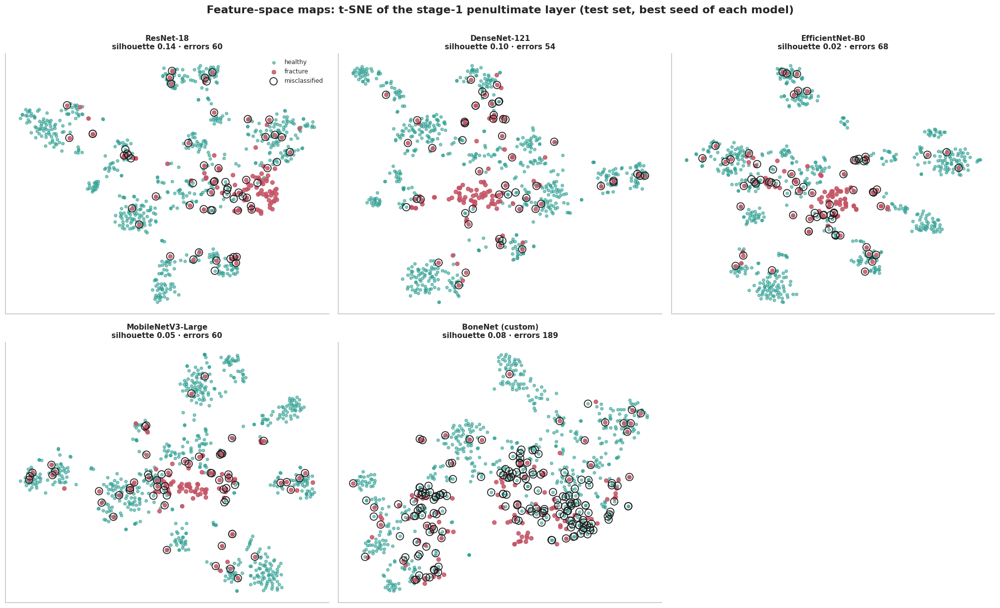

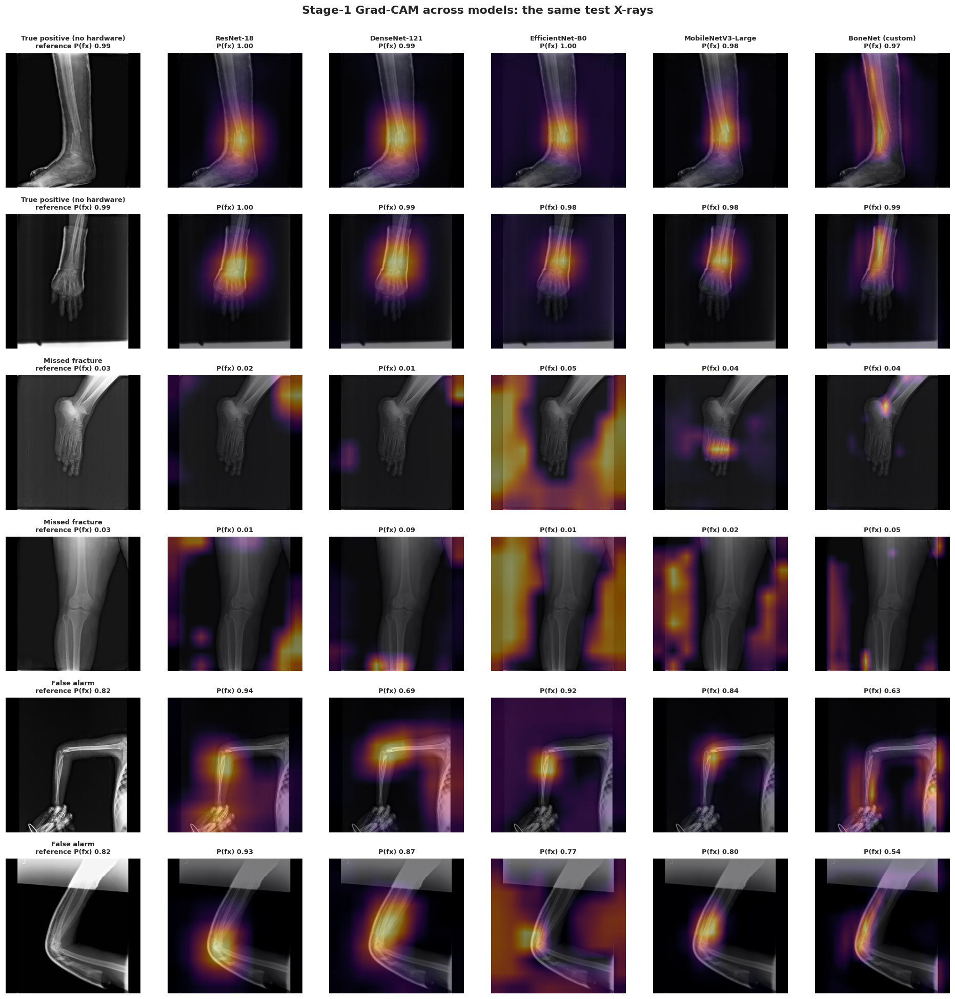

In [51]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler as _SS
from sklearn.metrics import silhouette_score
BEST_RUN = {n: max(MODEL_RUNS[n], key=lambda r: safe_ap(yv, r['p_val'])) for n in ARCHS}
def load_best(n): return load_pipe(BEST_RUN[n])
@torch.no_grad()
def penultimate(pipe, hi, bs=64):
    return torch.cat([pipe.n1.embed(to_input(to_model_res(hi[i:i + bs].to(DEVICE)))).float().cpu() for i in range(0, len(hi), bs)]).numpy()
nc = min(3, len(ARCHS)); nr = int(np.ceil(len(ARCHS) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(6.2 * nc, 5.6 * nr), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
SIL = {}
for ax, n in zip(axes.ravel(), ARCHS):
    pp = load_best(n); X = _SS().fit_transform(penultimate(pp, test_hi)); del pp; SIL[n] = float(silhouette_score(X, yt))
    try: E = TSNE(n_components=2, perplexity=float(min(30, max(5, (len(X) - 1) // 3))), init='pca', learning_rate='auto', random_state=SEED).fit_transform(X)
    except TypeError: E = TSNE(n_components=2, perplexity=float(min(30, max(5, (len(X) - 1) // 3))), random_state=SEED).fit_transform(X)
    err = (ens[n]['test'] >= thr_main[n]) != (yt == 1); ax.axis('on')
    ax.scatter(E[yt == 0, 0], E[yt == 0, 1], s=14, color='#2A9D8F', alpha=.55, label='healthy'); ax.scatter(E[yt == 1, 0], E[yt == 1, 1], s=26, color='#C45566', alpha=.85, label='fracture')
    ax.scatter(E[err, 0], E[err, 1], s=95, facecolors='none', edgecolors='k', linewidths=1.1, label='misclassified'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f'{nice(n)}\nsilhouette {SIL[n]:.2f} · errors {int(err.sum())}', fontsize=10, fontweight='bold')
axes.ravel()[0].legend(frameon=False, fontsize=8, loc='best'); fig.suptitle('Feature-space maps: t-SNE of the stage-1 penultimate layer (test set, best seed of each model)', fontweight='bold', y=1.0); finish(fig, 'G11_feature_space_tsne')
pd.DataFrame({'model': [nice(n) for n in ARCHS], 'silhouette_penultimate_features': [SIL[n] for n in ARCHS]}).round(4).to_csv(OUT / 'tables' / 'feature_separability.csv', index=False)

ref = 'ensemble_all' if 'ensemble_all' in ens else ARCHS[0]; te_ = parts['test'].copy(); te_['p'] = ens[ref]['test']; tr_ = thr_main[ref]
hwm = te_.hardware.eq('yes').fillna(False) if 'hardware' in te_ else pd.Series(False, index=te_.index)
sel = [('True positive\n(no hardware)', te_[(te_.label == 1) & (te_.p >= tr_) & ~hwm].nlargest(2, 'p')), ('Missed fracture', te_[(te_.label == 1) & (te_.p < tr_)].nsmallest(2, 'p')), ('False alarm', te_[(te_.label == 0) & (te_.p >= tr_)].nlargest(2, 'p'))]
cases = [(t, r) for t, d_ in sel for _, r in d_.iterrows()]
if cases:
    CAM = {}
    for n in ARCHS:
        pp = load_best(n); lay = cam_target(pp.n1, n); CAM[n] = []
        for _, r in cases:
            cam = grad_cam(pp.n1, to_input(IMGS[r.path][None]), lay); CAM[n].append((cam[0], float(pp.run([r.path])['p'][0])))
        del pp
    fig, axes = plt.subplots(len(cases), 1 + len(ARCHS), figsize=(2.9 * (1 + len(ARCHS)), 2.95 * len(cases)), squeeze=False)
    for ri, (t, r) in enumerate(cases):
        axes[ri, 0].imshow(IMGS[r.path].numpy(), cmap='gray'); axes[ri, 0].set_title(f'{t.replace(chr(10), " ")}\nreference P(fx) {r.p:.2f}', fontsize=8.5, fontweight='bold')
        for ci_, n in enumerate(ARCHS, start=1):
            cam, pr = CAM[n][ri]; axes[ri, ci_].imshow(IMGS[r.path].numpy(), cmap='gray'); axes[ri, ci_].imshow(cam, cmap='inferno', alpha=.5); axes[ri, ci_].set_title((nice(n) + '\n' if ri == 0 else '') + f'P(fx) {pr:.2f}', fontsize=8.5)
    for ax in axes.ravel(): ax.axis('off')
    fig.suptitle('Stage-1 Grad-CAM across models: the same test X-rays', fontweight='bold', y=1.0); finish(fig, 'G12_gradcam_model_comparison', svg=False)
else: print('No suitable true-positive / missed / false-alarm cases for the comparison panel.')

## 11.6 · Verdict: what happened and which model is better

In [52]:
def pw_row(a, b, m):
    r = pw_df[(pw_df.model_a == nice(a)) & (pw_df.model_b == nice(b)) & (pw_df.metric == m)]; return r.iloc[0] if len(r) else None
V = []
V.append(f'Selection (fixed on validation AUPRC, before looking at test): {nice(BEST)}.')
tied, lower, higher = [], [], []
for n in ARCHS:
    if n == BEST: continue
    ra, rp = pw_row(n, BEST, 'auroc'), pw_row(n, BEST, 'auprc')
    if (ra.ci_high < 0) or (rp.ci_high < 0): lower.append(f'{nice(n)} (ΔAUROC {ra["diff"]:+.3f}, ΔAUPRC {rp["diff"]:+.3f})')
    elif (ra.ci_low > 0) or (rp.ci_low > 0): higher.append(nice(n))
    else: tied.append(nice(n))
V.append('Statistically indistinguishable from it on test (both paired 95 % CIs include 0): ' + (', '.join(tied) if tied else 'none') + '. This means the test set cannot separate them; it does not prove they are equal.')
V.append('Credibly lower than it on at least one of AUROC / AUPRC: ' + ('; '.join(lower) if lower else 'none') + '.' + (f' Credibly higher: {", ".join(higher)}.' if higher else ''))
ranked = crit.AUROC.sort_values(ascending=False); V.append('Test AUROC order (descriptive): ' + ' > '.join(f'{nice(n)} {v:.3f}' for n, v in ranked.items()) + '; gaps smaller than the intervals in G04 are not real differences.')
if 'custom_cnn' in ARCHS:
    pre = [n for n in ARCHS if n != 'custom_cnn']; bp = max(pre, key=lambda n: np.mean([safe_ap(yv, r['p_val']) for r in MODEL_RUNS[n]])); r1, r2 = pw_row('custom_cnn', bp, 'auroc'), pw_row('custom_cnn', bp, 'auprc')
    verdict = 'credibly worse' if r1.ci_high < 0 else ('credibly better' if r1.ci_low > 0 else 'not distinguishable')
    V.append(f'Custom BoneNet vs the best pretrained model ({nice(bp)}): ΔAUROC {r1["diff"]:+.3f} ({r1.ci_low:+.3f} to {r1.ci_high:+.3f}), ΔAUPRC {r2["diff"]:+.3f} ({r2.ci_low:+.3f} to {r2.ci_high:+.3f}) -> {verdict}. '
             f'BoneNet has {crit.loc["custom_cnn", "Parameters (M)"]:.2f}M parameters ({crit.loc["custom_cnn", "Parameters (M)"] / crit.loc[bp, "Parameters (M)"]:.2f}× {nice(bp)}), {crit.loc["custom_cnn", f"{LAT_NAME} latency (ms)"]:.1f} ms {LAT_NAME} latency ({crit.loc["custom_cnn", f"{LAT_NAME} latency (ms)"] / crit.loc[bp, f"{LAT_NAME} latency (ms)"]:.2f}× {nice(bp)}), no ImageNet pretraining; rank {int(rank.loc["custom_cnn", "AUROC"])} of {NM} by AUROC.')
ok = []
for n in ARCHS:
    if n == BEST: ok.append(n); continue
    ra, rp = pw_row(n, BEST, 'auroc'), pw_row(n, BEST, 'auprc')
    if not (ra.ci_high < 0 or rp.ci_high < 0) and ra['diff'] >= -0.01: ok.append(n)
cheap = min(ok, key=lambda n: crit.loc[n, f'{LAT_NAME} latency (ms)'])
V.append(f'Practical recommendation: among models that are not credibly worse than {nice(BEST)} AND whose AUROC is within 0.01 of it ({", ".join(nice(n) for n in ok)}), the cheapest to run is {nice(cheap)} '
         f'({crit.loc[cheap, f"{LAT_NAME} latency (ms)"]:.1f} ms {LAT_NAME}, {crit.loc[cheap, "Parameters (M)"]:.2f}M parameters, AUROC {crit.loc[cheap, "AUROC"]:.3f}). Non-inferiority is NOT proven: with {int(yt.sum())} fractured test images the intervals are wide, so "tied" means "cannot be separated", not "equal".')
rb = crit['Robustness (% AUROC kept)']; V.append(f'Robustness (mean AUROC kept under 8 corruptions): best {nice(rb.idxmax())} {rb.max():.1f} %, worst {nice(rb.idxmin())} {rb.min():.1f} %; spread {rb.max() - rb.min():.1f} points' + (' (small: do not rank on it).' if rb.max() - rb.min() < 3 else ' (material).'))
cal = crit['Calibration (1 − ECE)']; V.append(f'Calibration: lowest ECE {nice(cal.idxmax())} ({1 - cal.max():.3f}), highest {nice(cal.idxmin())} ({1 - cal.min():.3f}).')
gap = PM.loc['tr_auroc'] - PM.loc['va_auroc']; V.append(f'Overfitting (train − validation AUROC): largest {nice(gap.idxmax())} {gap.max():+.3f}, smallest {nice(gap.idxmin())} {gap.min():+.3f}.')
if hwd is not None: nh_ = crit['AUROC (no hardware)']; V.append(f'Hardware-free AUROC (conservative estimate): best {nice(nh_.idxmax())} {nh_.max():.3f}; mean change vs all test images {float((nh_ - crit.AUROC).mean()):+.3f}.')
V.append(f'Error overlap: {int(miss.all(0).sum())} of {len(pos_idx)} fractures are missed by every model (hard cases), {int((miss.sum(0) == 1).sum())} by exactly one (recoverable by ensembling); ensemble of all models AUROC {safe_auc(yt, ens["ensemble_all"]["test"]):.3f}.' if 'ensemble_all' in ens else '')
V.append(f'Feature separability (silhouette of penultimate features): best {nice(max(SIL, key=SIL.get))} {max(SIL.values()):.2f}, lowest {nice(min(SIL, key=SIL.get))} {min(SIL.values()):.2f}.')
V = [v for v in V if v]; VERDICT_LINES = V
print('=' * 118); print('  FINAL VERDICT (rule-based, from this run)'); print('=' * 118)
for i, v in enumerate(V, 1): print(f'{i:>2}. {v}\n')
(OUT / 'final_verdict.txt').write_text('\n'.join(f'{i}. {v}' for i, v in enumerate(V, 1))); print('Saved:', OUT / 'final_verdict.txt')

  FINAL VERDICT (rule-based, from this run)
 1. Selection (fixed on validation AUPRC, before looking at test): DenseNet-121.

 2. Statistically indistinguishable from it on test (both paired 95 % CIs include 0): none. This means the test set cannot separate them; it does not prove they are equal.

 3. Credibly lower than it on at least one of AUROC / AUPRC: ResNet-18 (ΔAUROC +0.003, ΔAUPRC -0.021); EfficientNet-B0 (ΔAUROC -0.019, ΔAUPRC -0.056); MobileNetV3-Large (ΔAUROC -0.011, ΔAUPRC -0.035); BoneNet (custom) (ΔAUROC -0.110, ΔAUPRC -0.265).

 4. Test AUROC order (descriptive): ResNet-18 0.928 > DenseNet-121 0.925 > MobileNetV3-Large 0.914 > EfficientNet-B0 0.906 > BoneNet (custom) 0.814; gaps smaller than the intervals in G04 are not real differences.

 5. Custom BoneNet vs the best pretrained model (DenseNet-121): ΔAUROC -0.110 (-0.150 to -0.069), ΔAUPRC -0.265 (-0.339 to -0.196) -> credibly worse. BoneNet has 5.67M parameters (0.40× DenseNet-121), 16.4 ms GPU latency (0.27× DenseNe

# Section 12: Final Summary & Export

In [53]:
def md_table(df, index=True):
    d = df.reset_index() if index else df.copy(); cols = [str(c) for c in d.columns]
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    for _, r in d.iterrows(): lines.append('| ' + ' | '.join(f'{v:.3f}' if isinstance(v, float) else str(v) for v in r.values) + ' |')
    return '\n'.join(lines)
def save_table(df, name, index=True):
    (OUT / 'tables' / f'{name}.md').write_text(md_table(df, index))
    try: (OUT / 'tables' / f'{name}.tex').write_text(df.to_latex(index=index, escape=True))
    except Exception as e: print(f'LaTeX export skipped for {name}: {type(e).__name__}')
save_table(tab1, 'table1_mean_sd_over_seeds'); save_table(tab2, 'table2_formatted'); save_table(abl_fmt, 'table10_twostage_ablation'); save_table(loc_tab, 'table11_localization')

if 'hw_val' not in globals(): hw_val = lambda n, col='auroc_nohw': 'n/a'
print('=' * 100); print('FINAL CNN RESULTS SUMMARY'); print('=' * 100)
fin = pd.DataFrame([dict(Model=nice(n) + (' *' if n == BEST else ''), Params=f'{PM.loc["params", n]:.2f}M', TestAUROC=f'{ci_i.loc[nice(n), "auroc"]:.3f}', TestAUPRC=f'{ci_i.loc[nice(n), "auprc"]:.3f}', Sens=f'{ci_i.loc[nice(n), "sensitivity"]:.3f}',
                    Spec=f'{ci_i.loc[nice(n), "specificity"]:.3f}', F1=f'{ci_i.loc[nice(n), "f1"]:.3f}', BestEp=f'{PM.loc["best_epoch", n]:.1f}', TrainAUROC=f'{PM.loc["tr_auroc", n]:.3f}', ValAUROC=f'{PM.loc["va_auroc", n]:.3f}',
                    Robust=f'{summ.loc[nice(n), "mean_retention_pct"]:.1f}%', AUROC_noHW=hw_val(n), GPUms=(f'{eff_df.loc[n, "gpu_b1_ms_mean"]:.2f}' if 'gpu_b1_ms_mean' in eff_df else 'n/a'), CPUms=f'{eff_df.loc[n, "cpu_b1_ms_mean"]:.1f}') for n in ARCHS])
print(fin.to_string(index=False)); fin.to_csv(OUT / 'tables' / 'final_summary.csv', index=False)
print(f'\nBest model (highest mean validation AUPRC): {nice(BEST)}   * = selected on validation, never on test')

pred = parts['test'][['path', 'group_id', 'label']].copy()
for k in KEYS: pred[f'p_{nice(k)}'] = ens[k]['test']
pred.to_csv(OUT / 'tables' / 'test_predictions_seed_ensembles.csv', index=False)
ENV = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__, device=str(DEVICE), gpu=ENV_GPU, platform=platform.platform())
(OUT / 'run_config_training.json').write_text(json.dumps(dict(env=ENV, models=ARCHS, seeds=SEEDS, img_size=IMG_SIZE, hires=HIRES, crop_size=CROP_SIZE, epochs=EPOCHS, patience=PATIENCE, warmup_epochs=WARMUP_EPOCHS,
    batch=BATCH, lr=LR, head_lr_mult=HEAD_LR_MULT, lr_by_model=LR_BY_MODEL, weight_decay=WD, label_smoothing=LABEL_SMOOTH, head_dropout=HEAD_DROPOUT, ema_decay=EMA_DECAY, tta=TTA, loss=LOSS,
    robust_aug=ROBUST_AUG, loc_weight=LOC_WEIGHT, crop_scale=CROP_SCALE, min_crop=MIN_CROP, crop_jitter=CROP_JITTER, neg_random_frac=NEG_RANDOM_FRAC, pretrained=PRETRAINED, pretrained_loaded=PRETRAINED_OK,
    threshold_rule=THRESHOLD_RULE, norm_mean=MEAN, norm_std=STD, n_boot=N_BOOT, selected_by_val_auprc=BEST, split=split_tab.reset_index().to_dict('records')), indent=2, default=str))
b = ci_i.loc[nice(BEST)]; ncorr = int(summ.shape[0])
notes = f"""# Paper notes (auto-generated from this run)

## Data and split
FracAtlas, cleaned: exact duplicates, label conflicts and COCO-box disagreements removed; near-duplicate images grouped into families and kept in one split (family-grouped, label-stratified 70/10/20). FracAtlas has no patient IDs, so the split is family-level, not patient-level.
{md_table(split_tab)}
External set: HBFMID originals (valid/test folders, X-ray inferred from filenames, no family overlap with FracAtlas); never used for training, thresholds or model selection.

## Method
Models: {', '.join(nice(m) for m in ARCHS)} (torchvision, ImageNet weights loaded: {PRETRAINED_OK}); BoneNet is trained from scratch.
Stage 1: full image at {IMG_SIZE}x{IMG_SIZE} (letterboxed grayscale repeated to 3 channels, normalised with train mean/std {MEAN:.4f}/{STD:.4f}); classification head plus a localization head (soft-argmax single box) trained on the union of the FracAtlas fracture boxes (L1 + GIoU, weight {LOC_WEIGHT}).
Stage 2: zoomed {CROP_SIZE}x{CROP_SIZE} crop taken from the {HIRES}px source at the stage-1 box (side x{CROP_SCALE}, minimum {MIN_CROP} of the image); trained on jittered annotated boxes for fractures and on stage-1 or random boxes for healthy images.
Fusion: weighted mean of the two logits, weight chosen on validation (grid of 0 to 1 in steps of 0.1, by validation AUPRC).
Recipe: AdamW (lr {LR}, x{HEAD_LR_MULT} on the heads, BoneNet lr {LR_BY_MODEL.get('custom_cnn')}), weight decay {WD}, {WARMUP_EPOCHS}-epoch warm-up then cosine over {EPOCHS} epochs, label smoothing {LABEL_SMOOTH}, head dropout {HEAD_DROPOUT}, EMA of weights ({EMA_DECAY}), batch {BATCH}, gradient clipping 1.0, mixed precision on GPU, early stopping on validation AUPRC (patience {PATIENCE}); seeds {SEEDS}.
Augmentation (training only, both classes): rotation ±10°, scale ±8%, translation ±5%, horizontal flip, brightness ±5%, contrast ±10%, random blur, noise and JPEG re-compression {ROBUST_AUG}; flip test-time augmentation: {TTA}.
Decision threshold chosen on validation ({THRESHOLD_RULE}); 95 % CIs from a cluster bootstrap over image families ({N_BOOT} resamples). Hardware: {ENV_GPU or 'CPU only'}; torch {ENV['torch']}.

## Main results (test set, seed-ensemble, 95 % CI)
{md_table(tab2)}

Mean ± SD over seeds:
{md_table(tab1)}

## Localization (stage 1, annotated test fractures)
{md_table(loc_tab)}

## Two-stage ablation (test set)
{md_table(abl_fmt)}

## Robustness (test AUROC retained, mean over severities; corruptions applied at source resolution)
{md_table(summ[['mean_retention_pct', 'mean_worst_drop']].round(3))}

## Efficiency (two-stage pipeline, flip TTA {TTA})
{md_table(eff_df[[c for c in ['params_M', 'GMACs', 'gpu_b1_ms_mean', 'cpu_b1_ms_mean', 'train_min'] if c in eff_df]].round(2).rename(index=nice))}

## Best model by validation AUPRC: {nice(BEST)}
Test AUROC {b.auroc:.3f} ({b.auroc_lo:.3f}-{b.auroc_hi:.3f}), AUPRC {b.auprc:.3f} ({b.auprc_lo:.3f}-{b.auprc_hi:.3f}) at prevalence {yt.mean():.3f}; sensitivity {b.sensitivity:.3f}, specificity {b.specificity:.3f}, F1 {b.f1:.3f}, MCC {b.mcc:.3f}, ECE {b.ece:.3f}.
Model pairs with a credible AUROC difference (95 % CI excludes 0): {n_sig} of {n_pairs}.

## Caveats to state
- Family-level, not patient-level split; {len(SEEDS)} seed(s); {int(yt.sum())} fractured test images, so intervals are wide.
- External set has {int((ye == 0).sum()) if len(ye) else 0} healthy images: only sensitivity is meaningful; domain shift (resolution, borders, contrast) is large.
- Boxes exist only for FracAtlas fractures; stage 2 crops for healthy images come from stage-1 or random boxes.
- Corruption tests are synthetic and applied at source resolution; Grad-CAM is qualitative; test numbers are descriptive and were not used for any choice.
"""
if 'hw_fmt' in globals() and hw_df is not None:
    notes += "\n## Hardware-free evaluation (Table 4)\nEvery FracAtlas image with orthopaedic hardware is a fracture, so hardware can act as a label proxy; the table repeats the test evaluation without those images (same models and thresholds).\n" + md_table(hw_fmt) + "\n"
if 'VERDICT_LINES' in globals():
    notes += "\n## Final comparison and verdict (auto-generated from this run; verify against the figures)\n" + '\n'.join('- ' + v for v in VERDICT_LINES) + "\n"
(OUT / 'paper_notes.md').write_text(notes)
zp = shutil.make_archive(str(OUT.parent / 'bone_fracture_cnn_outputs'), 'zip', OUT)
print('\nOutputs :', OUT, '\nZip     :', zp, '\nWeights :', CKPT_DIR); print('Figures :', len(list((OUT / 'figures').glob('*.png'))), 'PNG |', 'Tables :', len(list((OUT / 'tables').glob('*.csv'))), 'CSV')

FINAL CNN RESULTS SUMMARY
            Model Params TestAUROC TestAUPRC  Sens  Spec    F1 BestEp TrainAUROC ValAUROC Robust AUROC_noHW GPUms CPUms
        ResNet-18 22.57M     0.928     0.808 0.664 0.971 0.730   19.0      0.989    0.934  94.3%      0.917 21.10 208.5
   DenseNet-121 * 14.19M     0.925     0.829 0.713 0.971 0.763   19.0      0.993    0.946  95.6%      0.914 60.18 580.6
  EfficientNet-B0  8.33M     0.906     0.772 0.631 0.965 0.694   20.0      0.985    0.943  96.2%      0.892 35.34 200.6
MobileNetV3-Large  6.22M     0.914     0.794 0.598 0.983 0.709   20.0      0.986    0.927  95.8%      0.902 28.00 139.3
 BoneNet (custom)  5.67M     0.814     0.563 0.762 0.753 0.496   20.0      0.885    0.835  97.9%      0.804 16.36 154.9

Best model (highest mean validation AUPRC): DenseNet-121   * = selected on validation, never on test

Outputs : /kaggle/working/bone_fracture_cnn 
Zip     : /kaggle/working/bone_fracture_cnn_outputs.zip 
Weights : /kaggle/working/bone_fracture_cnn_check